
# Agentic AI for Retail Demand & Inventory Decision Support

**IDS 560 Capstone | Group 4 | Walmart M5 Forecasting Project**

> **Project Focus:** Data Preparation · Forecasting Baselines · Chronological Validation · Segmented Error Analysis · Statistical Model Comparison · LightGBM Development · Forecast Reliability · RAG Integration

---

### 1. Project Overview

This project develops a reproducible, memory-efficient, and leakage-aware demand forecasting framework using the **Walmart M5 Forecasting dataset** to support retail demand planning and inventory decision-making through an agentic AI workflow.

The forecasting pipeline progresses from data preparation and interpretable baselines to statistical model exploration, feature-based LightGBM forecasting, forecast uncertainty evaluation, and downstream retrieval-augmented decision support.

**The central objective is not only to improve forecast accuracy, but also to evaluate forecast reliability, identify systematic error patterns, and produce structured forecasting outputs that support inventory decisions.**

#### Dataset & Experimental Scope

| Component | Specification |
|---|---|
| **Dataset** | M5 Forecasting — Walmart-originated, Kaggle |
| **Source Files** | `sales_train_evaluation.csv`, `calendar.csv`, `sell_prices.csv` |
| **Full Population** | 30,490 daily item-store sales series |
| **Geographic Coverage** | California (CA), Texas (TX), Wisconsin (WI) |
| **Product Categories** | FOODS, HOUSEHOLD, HOBBIES |
| **Prototype Sample** | 100 series |
| **20% Sample** | 6,098 stratified series |
| **50% Sample** | 15,245 stratified series |
| **Sampling Design** | State × Category stratification; 20% sample nested within 50% |
| **Evaluation Horizons** | 7, 14, and 28 days |
| **Final Item-Level Export** | 7-day forecasts |
| **Downstream Integration** | Historical forecast scenarios, inventory analysis, and RAG decision support |

The prototype supports rapid experimentation, while the nested 20% and 50% samples support larger-scale evaluation and robustness checks.

Because the samples overlap, comparisons between them should not be interpreted as independent validation experiments.

---

### 2. End-to-End Project Workflow

| Phase | Main Activities | Expected Deliverables |
|---|---|---|
| **01 — Data Preparation** | Load and align M5 datasets; stratified sampling; chronological splitting; preprocessing and integrity checks | Validated sample manifests, aligned sales matrices, and consistent identifiers |
| **02 — Baseline Forecasting & Error Analysis** | Evaluate simple baselines; rolling-origin validation; state/category and demand-type diagnostics; bias and uncertainty analysis | Baseline metrics, segmented error tables, prediction intervals, and baseline forecasts |
| **03 — Statistical Model Exploration** | Evaluate Croston, SBA, TSB, and SES; tune using 2015 validation; apply predefined decision criteria; conduct exploratory 2016 comparisons | Statistical model benchmarks, tuning results, selection decisions, and exploratory test results |
| **04 — LightGBM Final Forecasting** | Feature-based forecasting; temporal evaluation; bias correction; cross-model comparison; final forecast generation | LightGBM metrics, final forecast artifacts, and structured RAG handoff |
| **Downstream — Inventory & RAG** | Retrieve forecasting evidence; analyze demand and uncertainty; support inventory-related decisions | AI-assisted inventory insights and decision-support evaluation |

**Separation of responsibilities:** Forecasting accuracy, RAG answer reliability, and simulated inventory outcomes are evaluated as distinct components. Improvements in one component do not automatically establish improvements in the others.

---

### 3. Forecasting Models

| Model Family | Models | Research Purpose |
|---|---|---|
| **Simple Baselines** | Zero Naive; Weekly Seasonal Naive; Recent Mean 7D; Recent Mean 28D | Establish interpretable reference forecasts and assess the value of additional complexity |
| **Intermittent-Demand Models** | Croston; SBA; TSB | Examine demand-size, sales-interval, and demand-occurrence modeling for sparse sales |
| **Exponential Smoothing** | SES / ETS(A,N,N) | Evaluate a general-purpose statistical alternative based on exponentially weighted demand |
| **Machine Learning** | LightGBM | Combine historical sales, price, product attributes, and calendar-based features |

Model families are evaluated using consistent samples, chronological boundaries, forecast horizons, and comparable error metrics.

The final model decision considers both forecast accuracy and systematic bias rather than relying exclusively on the lowest WAPE.

---

### 4. Chronological Evaluation Design

| Period | Date Range | Duration | Primary Purpose |
|---|---|---:|---|
| **Training** | Jan 29, 2011 – Dec 31, 2014 | 1,433 days | Model fitting, historical feature construction, and training-only demand classification |
| **Validation** | Jan 1, 2015 – Dec 31, 2015 | 365 days | Rolling-origin evaluation, parameter tuning, model comparison, and selection |
| **Held-Out Test** | Jan 1, 2016 – May 22, 2016 | 143 days | Out-of-sample performance assessment using previously selected configurations |

#### Shared Evaluation Rules

| Component | Method |
|---|---|
| **Rolling-Origin Step** | 7 days |
| **Forecast Horizons** | 7, 14, and 28 days |
| **Primary Accuracy Metrics** | WAPE, RMSE, MAE |
| **Forecast Bias** | Signed forecast bias and segmented bias diagnostics |
| **Benchmark Comparison** | Forecast Value Added (FVA) and model-to-baseline comparisons |
| **Demand Classification** | Training-only ADI and CV²; thresholds of 1.32 and 0.49 |
| **Model Selection** | Predefined statistical-model screening criteria and validation-based comparison |
| **Leakage Prevention** | Features and demand statistics use only information available before each forecast origin |
| **Test Discipline** | 2016 test results are distinguished from validation-based tuning and exploratory analysis |

The held-out test period is not used to retune the original forecasting model configurations.

---

### 5. Forecast Evaluation & Reliability

| Evaluation Dimension | Measures / Analysis | Why It Matters |
|---|---|---|
| **Overall Accuracy** | WAPE, RMSE, MAE | Quantifies aggregate forecasting errors |
| **Forecast Bias** | Signed bias and segmented bias | Identifies persistent over-forecasting or under-forecasting |
| **Forecast Value Added** | Performance relative to simple benchmarks | Determines whether added model complexity creates measurable value |
| **Demand Segmentation** | Smooth, Erratic, Intermittent, Lumpy, No Sales | Explains differences in forecasting difficulty across demand patterns |
| **Business Segmentation** | State, category, demand level | Identifies where forecasting errors are concentrated |
| **Prediction Intervals** | Coverage, mean interval width, P10/P90 pinball loss | Evaluates forecast uncertainty and interval reliability |
| **Model Robustness** | 20% versus 50% sample performance; multiple horizons | Tests whether performance patterns remain consistent across sample sizes and forecast lengths |
| **Inventory Relevance** | Forecast errors, bias, and uncertainty | Provides inputs for evaluating potential stockout and holding-cost consequences |

**Key principle:** A model with lower WAPE is not necessarily preferable if it introduces excessive systematic bias or unreliable forecasts.

---

### 6. Forecasting Notebook Organization

The forecasting work is organized into four independently executable notebooks. Each notebook uses consistent source data and canonical sampling manifests while retaining its own model-specific calculations.

| Notebook | Responsibility | Relationship to Other Notebooks |
|---|---|---|
| **01 — M5 Data Preparation** | Source loading, sampling, chronological splitting, preprocessing, and validation | Establishes the canonical data preparation framework |
| **02 — Baseline Forecasting & Error Analysis** | Baselines, error decomposition, bias analysis, demand classification, prediction intervals, and baseline exports | Establishes reference performance and diagnostic benchmarks |
| **03 — Statistical Model Exploration** | Croston, SBA, TSB, SES, tuning, selection checks, and exploratory 2016 testing | Tests whether statistical methods improve on the baseline reference |
| **04 — LightGBM Final Forecasting** | LightGBM development, final evaluation, statistical comparisons, bias correction, and RAG handoff | Produces and validates final forecasting artifacts for downstream use |

#### Reproducibility & Integration Principles

- **Canonical Inputs:** All notebooks use the same M5 source datasets and established sampling manifests.
- **Independent Execution:** Each notebook restores the inputs needed for its own calculations instead of relying on another notebook's in-memory variables.
- **Consistent Evaluation:** Sample membership, chronological boundaries, forecast horizons, and shared error metrics remain aligned.
- **No Unintended Resampling:** Downstream notebooks reuse existing sample identifiers rather than creating new random samples.
- **Output Compatibility:** Established forecast filenames, schemas, and required paths are preserved where they form part of downstream interfaces.
- **RAG Handoff:** Structured forecasts, segment classifications, uncertainty information, and model comparisons are made available to downstream decision-support components.

---

### 7. Project Success Criteria

The project evaluates success across three connected, but distinct, layers:

| Layer | Success Criterion |
|---|---|
| **Forecasting Quality** | Reliable improvements over appropriate baselines, supported by chronological and segmented evaluation |
| **Forecasting Reliability** | Controlled bias, transparent uncertainty, reproducible results, and consistent data interfaces |
| **Decision Support** | Forecasting evidence can be retrieved and interpreted for inventory-related analysis, with downstream RAG and inventory outcomes evaluated separately |

**Overall Goal:** Build an interpretable and reproducible forecasting-to-decision-support framework that connects demand patterns, model performance, forecast reliability, and AI-assisted inventory analysis.



# Notebook 02 | M5 Baseline Forecasting

**Focus:** Baseline Model Comparison, Rolling-Origin Validation, Forecast Error Analysis, Signed Bias, Demand Segmentation, and Prediction Interval Evaluation.

**Objective:** Establish interpretable forecasting benchmarks, identify major sources of forecast error, and provide a consistent reference for statistical and LightGBM model development.

### Notebook Overview

This notebook evaluates simple forecasting methods using the established M5 item-store samples and chronological evaluation framework.

The analysis compares Zero Naive, Weekly Seasonal Naive, and Recent Mean forecasting methods across 7-, 14-, and 28-day horizons.

Beyond overall WAPE, RMSE, and signed bias, the notebook investigates forecast errors across states, categories, demand levels, and demand types, including the impact of zero-sales observations and irregular demand.

### Notebook Organization

| # | Section | Purpose |
|---|---|---|
| 1 | Setup & Data Loading | Load original M5 data, existing sample manifests, and required metadata |
| 2 | Baseline Forecasting | Generate Zero Naive, Weekly Seasonal Naive, and Recent Mean forecasts |
| 3 | Rolling-Origin Validation | Evaluate forecasts across historical origins |
| 4 | Horizon Evaluation & FVA | Compare baseline accuracy over 7/14/28 days |
| 5 | Error Analysis | Analyze forecasting errors across states and categories |
| 6 | Forecast Bias Analysis | Evaluate systematic over- and under-forecasting |
| 7 | Demand Segmentation Evaluation | Compare demand levels and demand types |
| 8 | Segmented Signed Bias Analysis | Evaluate bias across states, categories, and demand types |
| 9 | Prediction Interval Evaluation | Evaluate P10–P90 uncertainty intervals |
| 10 | Forecast Generation & Export | Generate standardized Recent Mean forecast outputs |
| 11 | Baseline Findings & Summary | Summarize baseline results and motivate advanced forecasting models |

### Data Dependencies

This notebook reads the original M5 datasets and the existing canonical sample manifests from `M5_Forecasting_Outputs/`.

Sample matrices and metadata are reconstructed in memory using the original series ordering. No new stratified sampling is performed.

The notebook runs independently of Notebook 01 and preserves existing shared forecast outputs by default.



## 1. Load Canonical Forecasting Inputs

This section loads the original M5 data and existing canonical sample manifests established in Notebook 01.

The predefined chronological training, validation, and test boundaries are reused to reconstruct the required forecasting matrices and metadata.

No new stratified sampling, data preparation experiments, or changes to the original evaluation design are performed.

This allows the baseline forecasting notebook to run independently without relying on variables from another Colab runtime.


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Existing M5 dataset and shared forecasting outputs
BASE_PATH = Path(
    "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 EDA/datasets/"
)
SALES_FILE = "sales_train_evaluation.csv"
Forecasting_OUTPUT = Path(
    "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/"
)

# 2. Dedicated directory for Notebook 02 figures
BASELINE_FIGURE_DIR = (
    Forecasting_OUTPUT / "baseline_experiment" / "figures"
)

EXPORT_BASELINE_FIGURES = True

def save_chart(filename=None):
    plt.tight_layout()

    if EXPORT_BASELINE_FIGURES and filename is not None:
        BASELINE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(
            BASELINE_FIGURE_DIR / filename,
            dpi=150,
            bbox_inches="tight"
        )

    plt.show()

# 3. Load original M5 datasets
sales = pd.read_csv(
    BASE_PATH / "sales_train_evaluation.csv"
)

calendar = pd.read_csv(
    BASE_PATH / "calendar.csv",
    parse_dates=["date"]
)

# 4. Load existing canonical sample manifests
# No new sampling or overwriting shared manifests
sample_prototype = pd.read_csv(
    Forecasting_OUTPUT / "sample_prototype_manifest.csv"
)

sample_20 = pd.read_csv(
    Forecasting_OUTPUT / "sample_20_manifest.csv"
)

sample_50 = pd.read_csv(
    Forecasting_OUTPUT / "sample_50_manifest.csv"
)

# 5. Validate sample sizes and memberships
assert len(sample_prototype) == 100
assert len(sample_20) == 6098
assert len(sample_50) == 15245

assert sample_prototype["id"].is_unique
assert sample_20["id"].is_unique
assert sample_50["id"].is_unique

assert set(sample_prototype["id"]).issubset(set(sample_20["id"]))
assert set(sample_20["id"]).issubset(set(sample_50["id"]))

print("M5 data and existing sample manifests loaded.")
print("Sales:", sales.shape)
print("Calendar:", calendar.shape)
print("Prototype: 100 | 20%: 6098 | 50%: 15245")
print("Baseline figures:", BASELINE_FIGURE_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
M5 data and existing sample manifests loaded.
Sales: (30490, 1947)
Calendar: (1969, 14)
Prototype: 100 | 20%: 6098 | 50%: 15245
Baseline figures: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/baseline_experiment/figures


In [ ]:

# Restore Canonical Forecasting Inputs — Baseline Notebook
# Reuse fixed manifests and chronological splits; do not resample or export.

import numpy as np
import pandas as pd
from pathlib import Path

# 1. Verify source data and canonical manifests
required_inputs = ["sales", "calendar", "sample_prototype", "sample_20", "sample_50"]
missing = [name for name in required_inputs if name not in globals()]
assert not missing, f"Missing loaded inputs: {missing}"

ID_COLS = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
day_cols = sorted(
    [c for c in sales.columns if c.startswith("d_")],
    key=lambda x: int(x.split("_")[1])
)

assert sales["id"].is_unique
assert calendar["d"].is_unique
assert set(day_cols).issubset(set(calendar["d"]))

# 2. Restore original chronological boundaries
calendar_sales = calendar.set_index("d").loc[day_cols].copy()
calendar_sales["date"] = pd.to_datetime(calendar_sales["date"])

train_mask = calendar_sales["date"] <= pd.Timestamp("2014-12-31")
val_mask = calendar_sales["date"].between("2015-01-01", "2015-12-31")
test_mask = calendar_sales["date"].between("2016-01-01", "2016-05-22")

train_days = calendar_sales.index[train_mask].tolist()
val_days = calendar_sales.index[val_mask].tolist()
test_days = calendar_sales.index[test_mask].tolist()
train_val_days = train_days + val_days
train_length = len(train_days)

assert (len(train_days), len(val_days), len(test_days)) == (1433, 365, 143)
assert train_days + val_days + test_days == day_cols
assert len(train_val_days) == 1798

# 3. Restore original helper function
def get_sales_split(sales, sample_ids, period_cols):
    result = sales.loc[
        sales["id"].isin(sample_ids),
        ID_COLS + list(period_cols)
    ].copy()
    assert len(result) == len(sample_ids)
    assert result["id"].is_unique
    return result

# 4. Restore canonical samples in ORIGINAL SALES FILE ORDER
manifests = {
    "prototype": sample_prototype,
    "sample_20": sample_20,
    "sample_50": sample_50,
}
expected_sizes = {"prototype": 100, "sample_20": 6098, "sample_50": 15245}

for name, manifest in manifests.items():
    assert len(manifest) == expected_sizes[name]
    assert manifest["id"].is_unique
    assert manifest["id"].isin(sales["id"]).all()

assert set(sample_prototype["id"]).issubset(set(sample_20["id"]))
assert set(sample_20["id"]).issubset(set(sample_50["id"]))

# Restore preprocessing outputs
prototype_tv = get_sales_split(sales, sample_prototype["id"], train_val_days)
sample20_tv = get_sales_split(sales, sample_20["id"], train_val_days)
sample50_tv = get_sales_split(sales, sample_50["id"], train_val_days)

prototype_ids = prototype_tv["id"].to_numpy()
sample20_ids = sample20_tv["id"].to_numpy()
sample50_ids = sample50_tv["id"].to_numpy()

prototype_matrix = prototype_tv[train_val_days].to_numpy(dtype=np.float32)
sample20_matrix = sample20_tv[train_val_days].to_numpy(dtype=np.float32)
sample50_matrix = sample50_tv[train_val_days].to_numpy(dtype=np.float32)

# 5. Restore original sample containers and aliases
sample_matrices = {
    "prototype": prototype_matrix,
    "sample_20": sample20_matrix,
    "sample_50": sample50_matrix,
}
sample_ids = {
    "prototype": prototype_ids,
    "sample_20": sample20_ids,
    "sample_50": sample50_ids,
}

# Original sampling-validation aliases used by later cells
sample_20_ids = set(sample_20["id"])
sample_50_ids = set(sample_50["id"])

# 6. Restore aligned metadata
metadata_20 = sample20_tv[["id", "state_id", "cat_id", "store_id"]].copy().reset_index(drop=True)
metadata_50 = sample50_tv[["id", "state_id", "cat_id", "store_id"]].copy().reset_index(drop=True)
prototype_metadata = prototype_tv[["id", "state_id", "cat_id", "store_id"]].copy().reset_index(drop=True)

# Original group-level metadata
metadata = sales.set_index("id")[["state_id", "cat_id"]]
sample20_metadata = metadata.reindex(sample20_ids)
sample50_metadata = metadata.reindex(sample50_ids)

# 7. Restore related calendar and source aliases
cal_by_d = calendar.set_index("d")
dates = pd.DatetimeIndex(cal_by_d.loc[day_cols, "date"])
week_of_day = cal_by_d.loc[day_cols, "wm_yr_wk"].to_numpy()
series = sales[ID_COLS].copy()
n_series = len(sales)
n_days = len(day_cols)

# 8. Validate ALL restored inputs
for name, matrix in sample_matrices.items():
    assert matrix.shape == (expected_sizes[name], 1798)
    assert np.isfinite(matrix).all()
    assert (matrix >= 0).all()

assert metadata_20["id"].tolist() == sample20_ids.tolist()
assert metadata_50["id"].tolist() == sample50_ids.tolist()
assert prototype_metadata["id"].tolist() == prototype_ids.tolist()

positions_20 = pd.Index(sample50_ids).get_indexer(sample20_ids)
assert (positions_20 >= 0).all()
assert np.array_equal(
    sample20_matrix,
    sample50_matrix[positions_20]
), "Nested sample matrix mismatch"

print("PASS: Canonical Baseline Inputs Restored")
print("Train / Validation / Test:", len(train_days), len(val_days), len(test_days))
print("Prototype:", prototype_matrix.shape)
print("20%:", sample20_matrix.shape)
print("50%:", sample50_matrix.shape)
print("Sample IDs, metadata and nested matrix alignment: PASSED")
print("No sampling or file exports performed.")


PASS: Canonical Baseline Inputs Restored
Train / Validation / Test: 1433 365 143
Prototype: (100, 1798)
20%: (6098, 1798)
50%: (15245, 1798)
Sample IDs, metadata and nested matrix alignment: PASSED
No sampling or file exports performed.


#2. Baseline Forecasting

In [ ]:
#Model configuration and validation
HORIZONS = [7, 14, 28]
SEASON_LENGTH = 7
RECENT_MEAN_WINDOW = 7

def validate_history(history, min_history=1):
    history = np.asarray(history, dtype=np.float32)
    if history.ndim != 2:
        raise ValueError("History must be a 2D array.")
    if history.shape[0] == 0:
        raise ValueError("History contains no series.")
    if history.shape[1] < min_history:
        raise ValueError("Insufficient historical days.")
    if not np.isfinite(history).all():
        raise ValueError("History contains NaN or Inf.")
    if (history < 0).any():
        raise ValueError("History contains negative sales.")
    return history

def validate_horizon(horizon):
    if (not isinstance(horizon, (int, np.integer))
        or isinstance(horizon, (bool, np.bool_))
        or horizon <= 0):
        raise ValueError("Horizon must be a positive integer.")

In [ ]:
def zero_naive(history, horizon):
    validate_horizon(horizon)
    n_series = history.shape[0]
    forecast = np.zeros((n_series, horizon),dtype=np.float32)
    assert np.all(forecast == 0)
    return forecast

def weekly_seasonal_naive(history,horizon,season_length=7):
    validate_horizon(horizon)
    if season_length <= 0:
        raise ValueError("Season length must be positive.")
    if history.shape[1] < season_length:
        raise ValueError("Insufficient seasonal history.")
    # Select the most recent seasonal cycle
    last_season = history[:, -season_length:]
    # Number of times the pattern must repeat
    repeats = int(np.ceil(horizon / season_length))
    # Repeat and truncate to requested horizon
    forecast = np.tile(last_season,(1, repeats))[:, :horizon]
    # Check the first seasonal block
    check_length = min(horizon, season_length)
    assert np.array_equal(
        forecast[:, :check_length],
        last_season[:, :check_length]
    )
    return forecast
def recent_mean(history,horizon,window=7):
    validate_horizon(horizon)
    if window <= 0:
        raise ValueError("Window must be positive.")
    if history.shape[1] < window:
        raise ValueError("Insufficient history for mean.")
    # Select recent observations
    recent_history = history[:, -window:]
    # One mean per series
    means = np.mean(recent_history,axis=1,dtype=np.float64).astype(np.float32)
    # Convert (n_series,) into (n_series, 1)
    means = means[:, None]
    # Repeat each series mean across future days
    forecast = np.repeat(means,horizon,axis=1)
    assert np.allclose(
        forecast,
        forecast[:, [0]]
    )
    return forecast
#Combine the three models
def generate_baselines(history,horizon,recent_mean_window=7,season_length=7):
    validate_horizon(horizon)
    history = validate_history(
        history,
        min_history=max(
            recent_mean_window,
            season_length
        )
    )
    forecasts = {
        "zero_naive": zero_naive(history, horizon),
        "weekly_seasonal_naive": weekly_seasonal_naive(history,horizon,season_length=season_length),
        "recent_mean": recent_mean(history,horizon,window=recent_mean_window)
    }
    expected_shape = (history.shape[0],horizon)
    for model_name, forecast in forecasts.items():
        assert forecast.shape == expected_shape, model_name
        assert np.isfinite(forecast).all(), model_name
        assert (forecast >= 0).all(), model_name
    return forecasts

In [ ]:
# Generate Baselines for Prototype, 20%, and 50%
HORIZONS = [7, 14, 28]
sample_matrices = {"prototype": prototype_matrix, "sample_20": sample20_matrix, "sample_50": sample50_matrix}
train_length = len(train_days)
baseline_forecasts = {}
generation_rows = []

for sample_name, matrix in sample_matrices.items():
    training_history = matrix[:, :train_length]
    baseline_forecasts[sample_name] = {}
    for horizon in HORIZONS:
        forecasts = generate_baselines(history=training_history, horizon=horizon, recent_mean_window=RECENT_MEAN_WINDOW, season_length=SEASON_LENGTH)
        baseline_forecasts[sample_name][horizon] = forecasts
        generation_rows.append({"Sample": sample_name, "Horizon (Days)": horizon, "Series": matrix.shape[0], "Models": len(forecasts), "Forecast Shape": str(next(iter(forecasts.values())).shape), "Status": "PASS" if all(f.shape == (matrix.shape[0], horizon) for f in forecasts.values()) else "FAIL"})

generation_summary = pd.DataFrame(generation_rows)
display(generation_summary)
print(f"Completed: {len(generation_summary)} sample-horizon combinations | {generation_summary['Models'].sum()} model forecasts")

,Sample,Horizon (Days),Series,Models,Forecast Shape,Status
0,prototype,7,100,3,"(100, 7)",PASS
1,prototype,14,100,3,"(100, 14)",PASS
2,prototype,28,100,3,"(100, 28)",PASS
3,sample_20,7,6098,3,"(6098, 7)",PASS
4,sample_20,14,6098,3,"(6098, 14)",PASS
5,sample_20,28,6098,3,"(6098, 28)",PASS
6,sample_50,7,15245,3,"(15245, 7)",PASS
7,sample_50,14,15245,3,"(15245, 14)",PASS
8,sample_50,28,15245,3,"(15245, 28)",PASS


Completed: 9 sample-horizon combinations | 27 model forecasts


In [ ]:
# Manual Sanity Check — Baseline Forecasts
sample_ids = {"prototype": prototype_ids, "sample_20": sample20_ids, "sample_50": sample50_ids}
series_index = 0
horizon = 14
sanity_rows = []

for sample_name, matrix in sample_matrices.items():
    history = matrix[series_index, :train_length][-7:]
    series_id = sample_ids[sample_name][series_index]
    for model_name, forecasts in baseline_forecasts[sample_name][horizon].items():
        prediction = forecasts[series_index]
        expected = np.zeros(horizon) if model_name == "zero_naive" else np.tile(history, int(np.ceil(horizon / 7)))[:horizon] if model_name == "weekly_seasonal_naive" else np.full(horizon, history.mean())
        sanity_rows.append({"Sample": sample_name, "Series ID": series_id, "Model": model_name, "Last 7 Actual": str(history.tolist()), "First 7 Forecast": str(np.round(prediction[:7], 3).tolist()), "Total Forecast": round(float(prediction.sum()), 3), "Check": "PASS" if np.allclose(prediction, expected) else "FAIL"})

sanity_summary = pd.DataFrame(sanity_rows)
display(sanity_summary)
assert (sanity_summary["Check"] == "PASS").all(), "Baseline sanity check failed."
print(f"Sanity Check: {len(sanity_summary)} / {len(sanity_summary)} model checks passed.")

,Sample,Series ID,Model,Last 7 Actual,First 7 Forecast,Total Forecast,Check
0,prototype,HOBBIES_1_115_CA_1_evaluation,zero_naive,"[0.0, 3.0, 0.0, 1.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]",0.0,PASS
1,prototype,HOBBIES_1_115_CA_1_evaluation,weekly_seasonal_naive,"[0.0, 3.0, 0.0, 1.0, 0.0, 0.0, 0.0]","[0.0, 3.0, 0.0, 1.0, 0.0, 0.0, 0.0]",8.0,PASS
2,prototype,HOBBIES_1_115_CA_1_evaluation,recent_mean,"[0.0, 3.0, 0.0, 1.0, 0.0, 0.0, 0.0]","[0.5709999799728394, 0.5709999799728394, 0.570...",8.0,PASS
3,sample_20,HOBBIES_1_003_CA_1_evaluation,zero_naive,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]",0.0,PASS
4,sample_20,HOBBIES_1_003_CA_1_evaluation,weekly_seasonal_naive,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]",2.0,PASS
5,sample_20,HOBBIES_1_003_CA_1_evaluation,recent_mean,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.14300000667572021, 0.14300000667572021, 0.1...",2.0,PASS
6,sample_50,HOBBIES_1_002_CA_1_evaluation,zero_naive,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]",0.0,PASS
7,sample_50,HOBBIES_1_002_CA_1_evaluation,weekly_seasonal_naive,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]",2.0,PASS
8,sample_50,HOBBIES_1_002_CA_1_evaluation,recent_mean,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.14300000667572021, 0.14300000667572021, 0.1...",2.0,PASS


Sanity Check: 9 / 9 model checks passed.


In [ ]:
# Baseline Prediction Summary
baseline_rows = []

for sample_name, horizons in baseline_forecasts.items():
    for horizon, forecasts in horizons.items():
        for model_name, forecast in forecasts.items():
            baseline_rows.append({"sample": sample_name, "horizon": horizon, "model": model_name, "n_series": forecast.shape[0], "total_predicted_units": float(forecast.sum()), "mean_prediction": float(forecast.mean()), "zero_prediction_share": float(np.mean(forecast == 0))})

baseline_summary = pd.DataFrame(baseline_rows)
display(baseline_summary)
baseline_summary.to_csv(Forecasting_OUTPUT / "baseline_prediction_summary.csv", index=False)

,sample,horizon,model,n_series,total_predicted_units,mean_prediction,zero_prediction_share
0,prototype,7,zero_naive,100,0.0,0.000000,1.000000
1,prototype,7,weekly_seasonal_naive,100,354.0,0.505714,0.762857
2,prototype,7,recent_mean,100,354.0,0.505714,0.360000
3,prototype,14,zero_naive,100,0.0,0.000000,1.000000
4,prototype,14,weekly_seasonal_naive,100,708.0,0.505714,0.762857
5,prototype,14,recent_mean,100,708.0,0.505714,0.360000
6,prototype,28,zero_naive,100,0.0,0.000000,1.000000
7,prototype,28,weekly_seasonal_naive,100,1416.0,0.505714,0.762857
8,prototype,28,recent_mean,100,1416.0,0.505714,0.360000
9,sample_20,7,zero_naive,6098,0.0,0.000000,1.000000


In [ ]:
# Baseline Visualization Configuration
import matplotlib.pyplot as plt

SAMPLES = ["sample_20", "sample_50"]
MODELS = ["zero_naive", "weekly_seasonal_naive", "recent_mean"]
MODEL_LABELS = {"zero_naive": "Zero Naive", "weekly_seasonal_naive": "Weekly Seasonal Naive", "recent_mean": "Recent Mean"}
MODEL_COLORS = {"zero_naive": "#777777", "weekly_seasonal_naive": "#E69F00", "recent_mean": "#0072B2"}

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False})

def save_baseline_plot(filename):
    plt.tight_layout()
    plt.savefig(Forecasting_OUTPUT / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

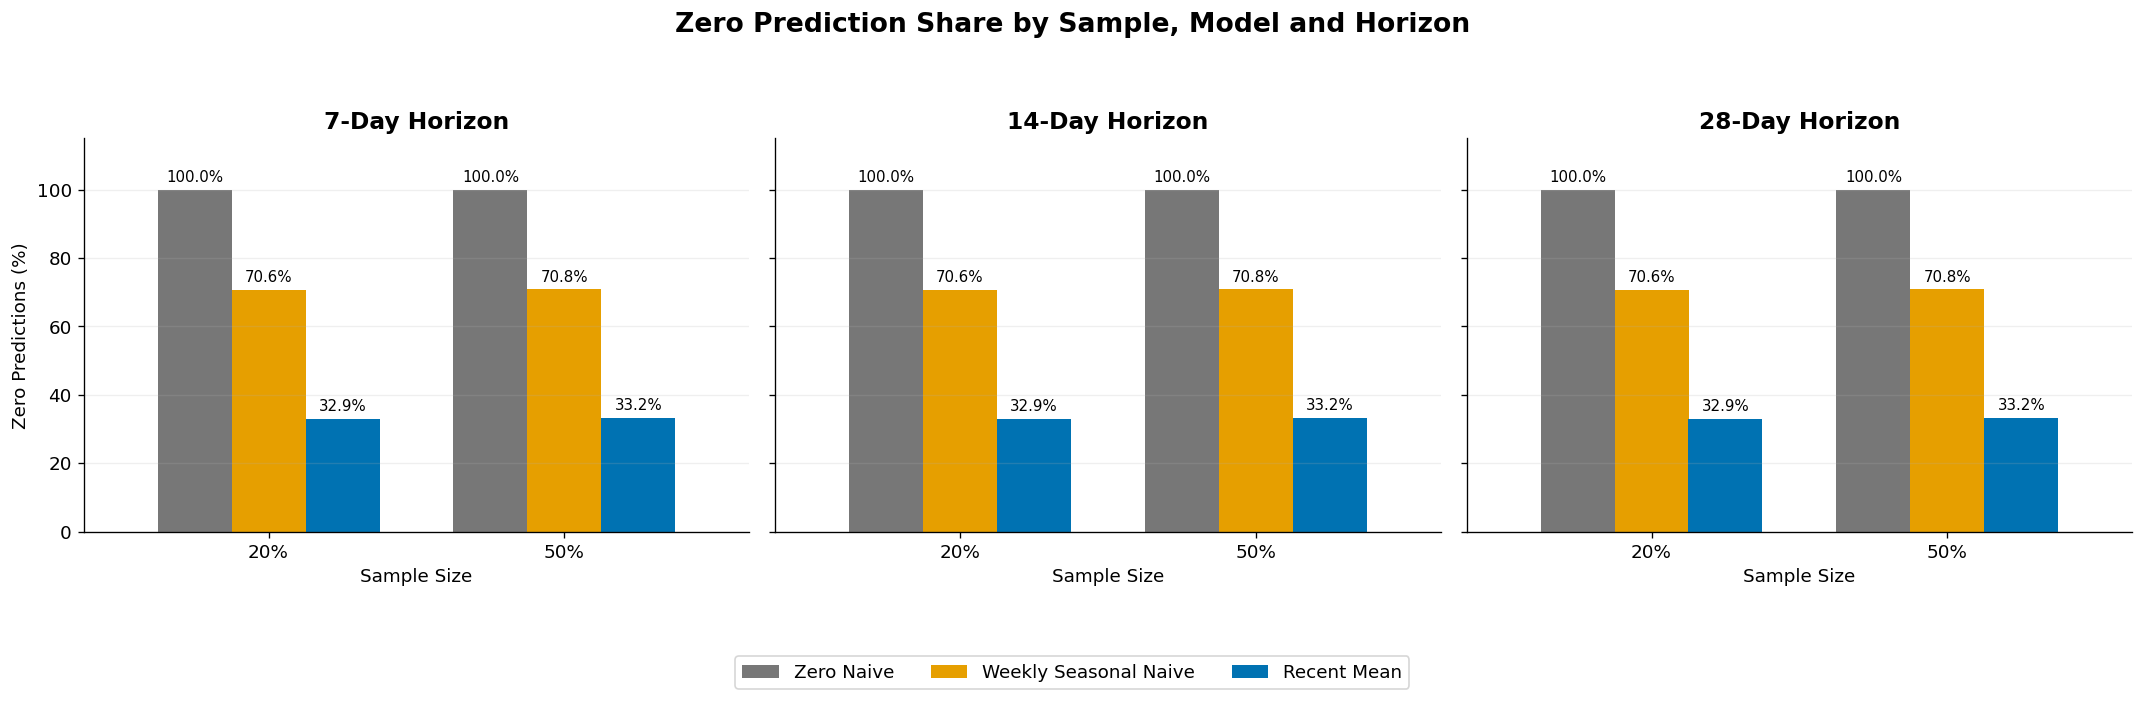

In [ ]:
# Figure 1 — Zero Prediction Share (20% vs 50%, 7/14/28 Days)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

for ax, horizon in zip(axes, HORIZONS):
    data = baseline_summary.query("sample in @SAMPLES and horizon == @horizon")
    pivot = data.pivot(index="sample", columns="model", values="zero_prediction_share").reindex(index=SAMPLES, columns=MODELS) * 100
    pivot.plot(kind="bar", ax=ax, color=[MODEL_COLORS[m] for m in MODELS], width=0.75, legend=False)
    ax.set_title(f"{horizon}-Day Horizon", fontweight="bold")
    ax.set_xlabel("Sample Size")
    ax.set_ylabel("Zero Predictions (%)")
    ax.set_xticklabels(["20%", "50%"], rotation=0)
    ax.set_ylim(0, 115)
    ax.grid(axis="y", alpha=0.2)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

handles, _ = axes[0].get_legend_handles_labels()
fig.legend(handles, [MODEL_LABELS[m] for m in MODELS], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Zero Prediction Share by Sample, Model and Horizon", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0.08, 1, 0.93])
fig.savefig(Forecasting_OUTPUT / "baseline_zero_share_all_horizons.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Figure 1 Findings — Zero Prediction Share Across Horizons

**Observation:** Zero Naive generates 100% zero predictions across all horizons. Weekly Seasonal Naive produces approximately 70.6%–70.8% zero predictions, compared with 32.9%–33.2% for Recent Mean. The proportions remain unchanged across 7-, 14-, and 28-day horizons, with minimal differences between the 20% and 50% samples.

**Interpretation:** Weekly Seasonal Naive preserves the zero-sales pattern of the most recent seven days, whereas Recent Mean distributes the seven-day average evenly across future days. The three horizons are multiples of seven, explaining the identical zero-prediction shares.

**Business Implication:** Different forecasting methods imply different daily replenishment patterns. Weekly Seasonal Naive produces more zero-demand days, while Recent Mean generates smoother forecasts. These differences may affect inventory planning, but zero-prediction share alone does not measure forecasting accuracy.

**Key Takeaway:** Model assumptions have a much stronger influence on predicted demand sparsity than the choice between the 20% and 50% samples.

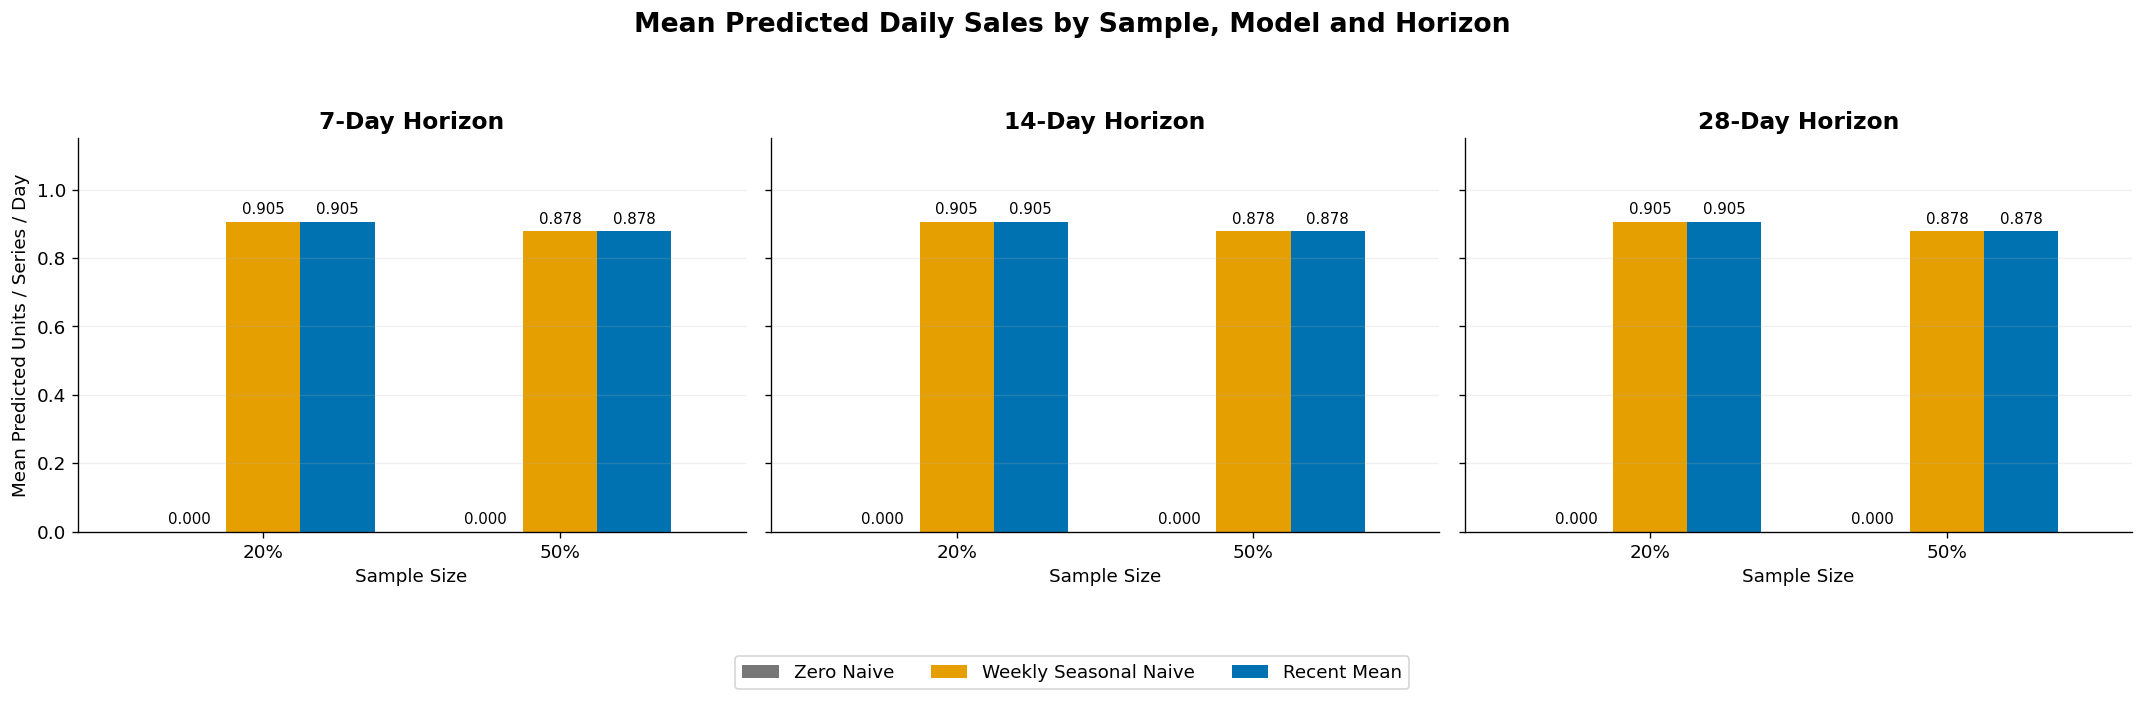

In [ ]:
# Figure 2 — Mean Predicted Daily Sales Across All Horizons
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

for ax, horizon in zip(axes, HORIZONS):
    data = baseline_summary.query("sample in @SAMPLES and horizon == @horizon")
    pivot = data.pivot(index="sample", columns="model", values="mean_prediction").reindex(index=SAMPLES, columns=MODELS)
    pivot.plot(kind="bar", ax=ax, color=[MODEL_COLORS[m] for m in MODELS], width=0.75, legend=False)
    ax.set_title(f"{horizon}-Day Horizon", fontweight="bold")
    ax.set_xlabel("Sample Size")
    ax.set_ylabel("Mean Predicted Units / Series / Day")
    ax.set_xticklabels(["20%", "50%"], rotation=0)
    ax.set_ylim(0, 1.15)
    ax.grid(axis="y", alpha=0.2)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

handles, _ = axes[0].get_legend_handles_labels()
fig.legend(handles, [MODEL_LABELS[m] for m in MODELS], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Mean Predicted Daily Sales by Sample, Model and Horizon", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0.08, 1, 0.93])
fig.savefig(Forecasting_OUTPUT / "baseline_mean_prediction_all_horizons.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Figure 2 Findings — Mean Predicted Daily Sales Across Samples and Horizons

**Observation:** Weekly Seasonal Naive and Recent Mean produce identical mean predicted daily sales across all three forecasting horizons. Both models forecast approximately **0.905 units per series per day for the 20% sample** and **0.878 units for the 50% sample**. Zero Naive consistently predicts zero. The 20% sample has approximately 3.1% higher mean predicted daily sales than the 50% sample.

**Interpretation:** The identical mean predictions across the 7-, 14-, and 28-day horizons result from the models' fixed seven-day historical window and the fact that all three horizons are multiples of seven. The small difference between the 20% and 50% samples reflects differences in their sampled series composition.

**Business Implication:** The similar mean predictions across both samples suggest that expanding the sample from 20% to 50% does not substantially change the average forecast volume per product-store series. However, average predicted sales alone cannot establish forecasting accuracy or sample representativeness.

**Key Takeaway:** **Mean predicted daily sales remain constant across all three horizons, with only a small difference between the 20% and 50% samples.**

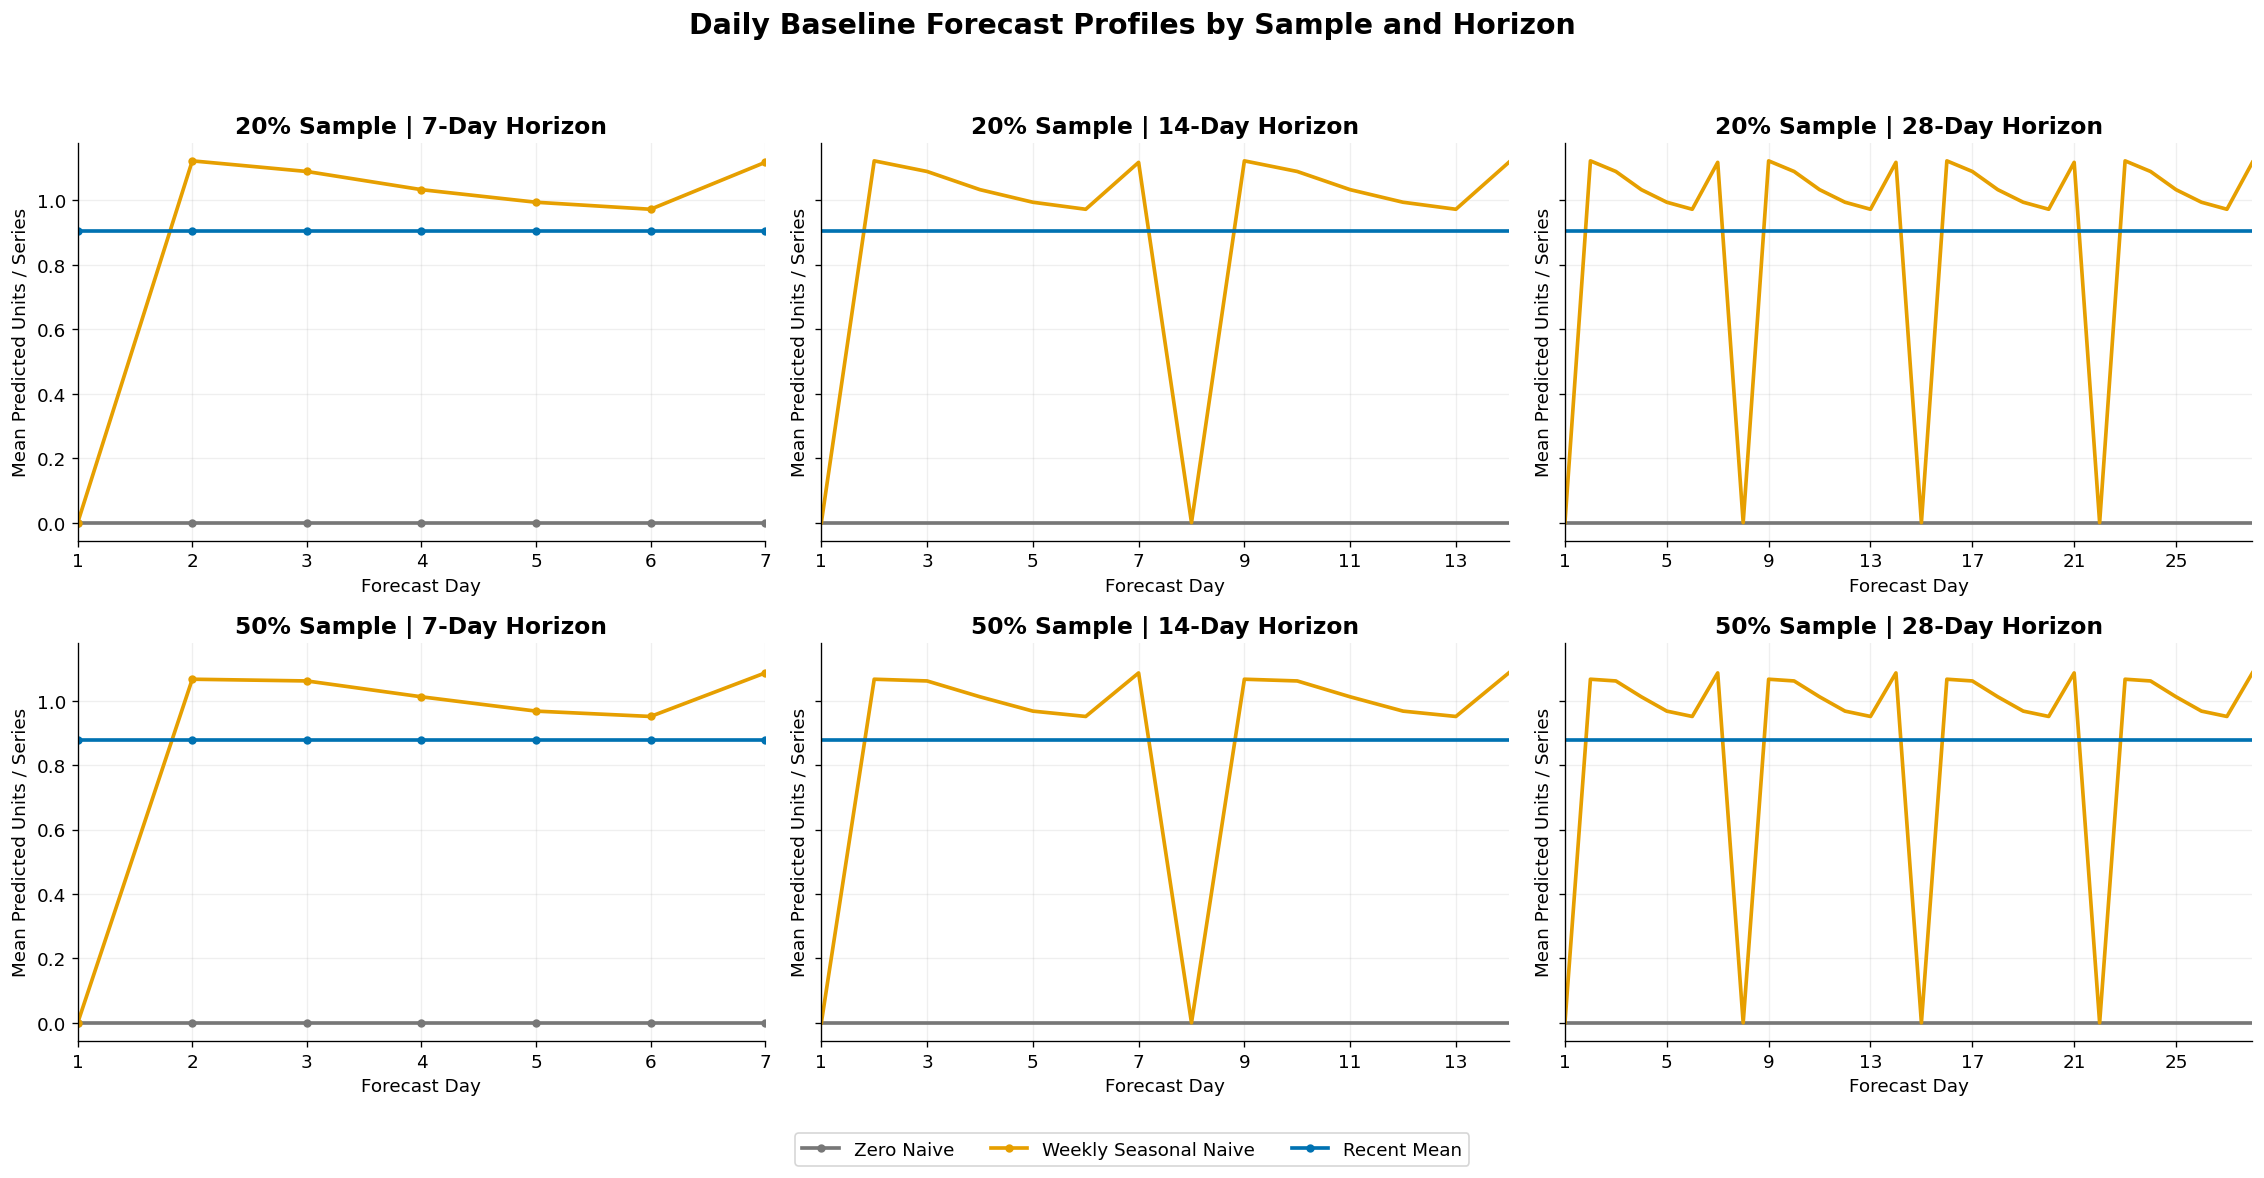

In [ ]:
# Figure 3 — Daily Baseline Forecast Profiles Across All Horizons
fig, axes = plt.subplots(2, 3, figsize=(19, 10), sharey=True)

for i, sample_name in enumerate(SAMPLES):
    for j, horizon in enumerate(HORIZONS):
        ax = axes[i, j]
        for model_name in MODELS:
            forecast = baseline_forecasts[sample_name][horizon][model_name]
            daily_mean = forecast.mean(axis=0)
            ax.plot(np.arange(1, horizon + 1), daily_mean, label=MODEL_LABELS[model_name], color=MODEL_COLORS[model_name], linewidth=2.2, marker="o" if horizon == 7 else None, markersize=4)
        ax.set_title(f"{'20%' if sample_name == 'sample_20' else '50%'} Sample | {horizon}-Day Horizon", fontweight="bold")
        ax.set_xlabel("Forecast Day")
        ax.set_ylabel("Mean Predicted Units / Series")
        ax.set_xlim(1, horizon)
        ax.set_xticks(np.arange(1, horizon + 1, 1 if horizon == 7 else 2 if horizon == 14 else 4))
        ax.grid(alpha=0.2)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.01))
fig.suptitle("Daily Baseline Forecast Profiles by Sample and Horizon", fontsize=17, fontweight="bold")
fig.tight_layout(rect=[0, 0.06, 1, 0.95])
fig.savefig(Forecasting_OUTPUT / "baseline_daily_profiles_all_horizons.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Figure 3 Findings — Daily Baseline Forecast Profiles Across Samples and Horizons

**Observation:** The three baseline models exhibit distinct daily forecasting patterns across both sampling levels and all three horizons. Zero Naive consistently predicts zero demand, while Recent Mean generates constant daily forecasts of approximately 0.905 units per series for the 20% sample and 0.878 for the 50% sample. In contrast, Weekly Seasonal Naive produces a repeating seven-day pattern, with noticeable fluctuations and zero predictions on forecast days 1, 8, 15, and 22. The 20% and 50% samples display similar forecast profiles.

**Interpretation:** These differences reflect the forecasting assumptions of each model. Zero Naive assumes no future sales, Recent Mean maintains a constant estimate based on the most recent seven days, and Weekly Seasonal Naive directly repeats the historical weekly sales pattern. As the forecast horizon increases from 7 to 28 days, the same patterns are extended without introducing additional trends or adjustments. The recurring zero values in Weekly Seasonal Naive reflect the first position of the historical seven-day pattern used for forecasting.

**Business Implication:** The choice of baseline model influences the expected timing and distribution of demand. Weekly Seasonal Naive reflects historical day-to-day variations, whereas Recent Mean produces a more stable daily demand estimate. These different forecast structures may lead to different daily inventory planning requirements, even when average forecast volumes are similar.

**Key Takeaway:** **Weekly Seasonal Naive preserves a repeating seven-day demand pattern, while Recent Mean produces stable daily forecasts. Both samples show similar model behavior across all three forecasting horizons.**

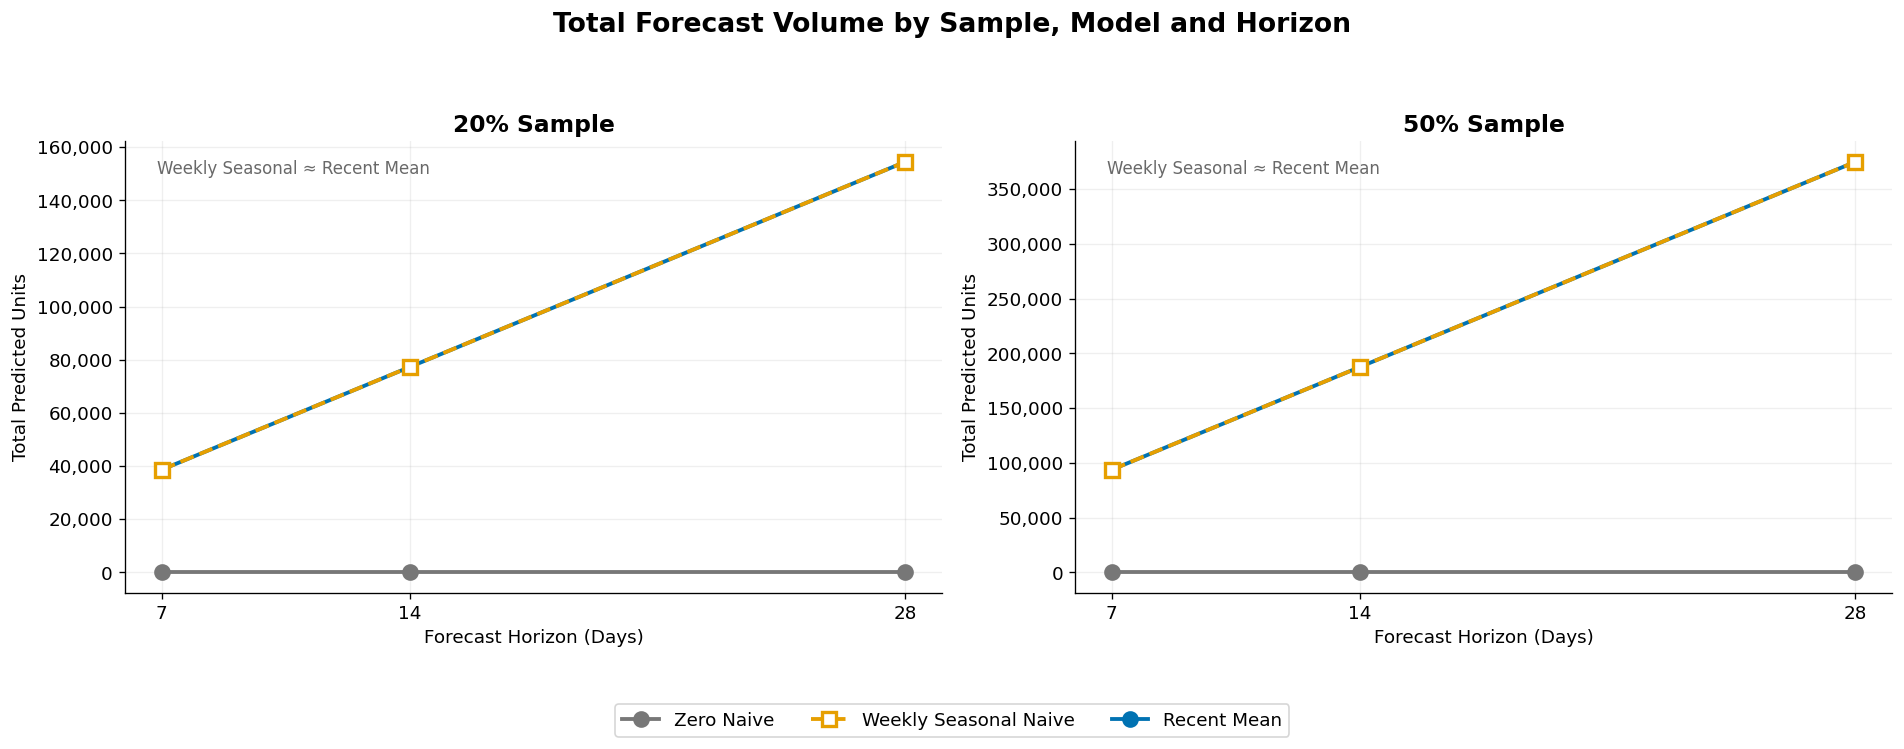

In [ ]:
# Figure 4 — Total Forecast Volume Across Horizons
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, sample_name in zip(axes, SAMPLES):
    data = baseline_summary.query("sample == @sample_name")
    pivot = data.pivot(index="horizon", columns="model", values="total_predicted_units").reindex(index=HORIZONS, columns=MODELS)
    for model_name in MODELS:
        style = {"zero_naive": ("-", "o", 2), "weekly_seasonal_naive": ("--", "s", 4), "recent_mean": ("-", "o", 3)}
        ls, marker, zorder = style[model_name]
        ax.plot(pivot.index, pivot[model_name], label=MODEL_LABELS[model_name], color=MODEL_COLORS[model_name], linestyle=ls, marker=marker, linewidth=2.3, markersize=8, markerfacecolor="white" if model_name == "weekly_seasonal_naive" else MODEL_COLORS[model_name], markeredgewidth=2, zorder=zorder)
    ax.set_title(f"{'20%' if sample_name == 'sample_20' else '50%'} Sample", fontweight="bold")
    ax.set_xlabel("Forecast Horizon (Days)")
    ax.set_ylabel("Total Predicted Units")
    ax.set_xticks(HORIZONS)
    ax.grid(alpha=0.2)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f"{x:,.0f}"))
    ax.text(0.04, 0.96, "Weekly Seasonal ≈ Recent Mean", transform=ax.transAxes, va="top", fontsize=10, color="dimgray")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Total Forecast Volume by Sample, Model and Horizon", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0.07, 1, 0.93])
fig.savefig(Forecasting_OUTPUT / "baseline_total_forecast_volume.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Figure 4 Findings — Total Forecast Volume Across Samples and Horizons

**Observation:** Total predicted sales increase linearly as the forecasting horizon extends from 7 to 28 days. For the 20% sample, Weekly Seasonal Naive and Recent Mean predict 38,617 units over 7 days, 77,234 over 14 days, and 154,468 over 28 days. For the 50% sample, the corresponding totals are 93,685, 187,370, and 374,740 units. Both models produce overlapping forecast-volume lines, while Zero Naive consistently predicts zero demand.

**Interpretation:** The linear growth reflects the fixed seven-day forecasting assumptions used by Weekly Seasonal Naive and Recent Mean. Because both models preserve the same total demand over each seven-day period, extending the horizon proportionally increases their aggregate forecasts. The 50% sample generates higher total predicted sales primarily because it contains more product-store series (15,245 versus 6,098).

**Business Implication:** Total forecast volume helps estimate expected demand quantities over different inventory planning horizons. However, comparisons across samples should account for the number of product-store series, since a larger sample naturally produces greater aggregate demand. Forecast volume alone does not indicate which model is more accurate.

**Key Takeaway:** **Total forecast volume grows proportionally with the forecasting horizon, and both nonzero baseline models produce the same aggregate demand estimates.**

In [ ]:
# Metadata Preparation for Group-Level Analysis
metadata = sales.set_index("id")[["state_id", "cat_id"]]
sample20_metadata = metadata.reindex(sample20_ids)
sample50_metadata = metadata.reindex(sample50_ids)

assert not sample20_metadata.isna().any().any(), "Missing metadata in 20% sample."
assert not sample50_metadata.isna().any().any(), "Missing metadata in 50% sample."
print(f"Metadata Validation: PASSED | 20%: {len(sample20_metadata):,} series | 50%: {len(sample50_metadata):,} series")

Metadata Validation: PASSED | 20%: 6,098 series | 50%: 15,245 series


In [ ]:
# Cross-Sample Forecast Consistency Check
idx20 = {sid: i for i, sid in enumerate(sample20_ids)}
idx50 = {sid: i for i, sid in enumerate(sample50_ids)}
assert set(idx20).issubset(set(idx50)), "20% sample is not nested in 50% sample."

consistency_rows = []

for horizon in HORIZONS:
    for model_name in MODELS:
        forecast20 = baseline_forecasts["sample_20"][horizon][model_name]
        forecast50 = baseline_forecasts["sample_50"][horizon][model_name]
        matched50 = forecast50[[idx50[sid] for sid in sample20_ids]]
        passed = np.allclose(forecast20, matched50, rtol=1e-6, atol=1e-6)
        consistency_rows.append({"Horizon": horizon, "Model": MODEL_LABELS[model_name], "Matched Series": len(sample20_ids), "Status": "PASS" if passed else "FAIL"})

consistency_summary = pd.DataFrame(consistency_rows)
display(consistency_summary)
assert (consistency_summary["Status"] == "PASS").all(), "Cross-sample forecast consistency failed."
print(f"Cross-Sample Consistency: {len(consistency_summary)} / {len(consistency_summary)} checks passed.")

,Horizon,Model,Matched Series,Status
0,7,Zero Naive,6098,PASS
1,7,Weekly Seasonal Naive,6098,PASS
2,7,Recent Mean,6098,PASS
3,14,Zero Naive,6098,PASS
4,14,Weekly Seasonal Naive,6098,PASS
5,14,Recent Mean,6098,PASS
6,28,Zero Naive,6098,PASS
7,28,Weekly Seasonal Naive,6098,PASS
8,28,Recent Mean,6098,PASS


Cross-Sample Consistency: 9 / 9 checks passed.


### Cross-Sample Forecast Consistency — Validation

The 20% sample is fully nested within the 50% sample. Forecasts for all 6,098 shared product-store series were compared across the three baseline models and the 7-, 14-, and 28-day horizons.

All nine consistency checks passed, confirming that shared series produce matching forecasts regardless of sample size. This validates the alignment of series identifiers and forecast outputs across the two samples.

In this section, we generated three baseline forecasting models: Zero Naive, Weekly Seasonal Naive, and Recent Mean, using 20% and 50% samples across three forecasting horizons: 7, 14, and 28 days.

We found three key insights.

First, the models handle zero demand differently. Zero Naive always predicts zero sales, while Weekly Seasonal Naive generates around 71% zero predictions, compared with approximately 33% for Recent Mean.

Second, Weekly Seasonal Naive and Recent Mean produce the same average predicted daily sales, but their daily forecast patterns are different. Weekly Seasonal Naive repeats the previous seven-day sales pattern, while Recent Mean produces a constant daily forecast.

Third, the 20% and 50% samples show similar forecasting characteristics across all three horizons. Total forecast volume also increases proportionally as the horizon extends from 7 to 28 days.

The main takeaway is that even when two models predict the same total sales volume, they can distribute demand differently across days. This matters for Walmart because daily demand patterns can influence replenishment scheduling and inventory planning.

At this stage, we are examining forecast behavior rather than accuracy. In the next section, we use rolling-origin evaluation and metrics such as WAPE, MAE, and RMSE to determine which baseline performs better.

# 7.Rolling-Origin Validation

In [ ]:
# Rolling-Origin Backtesting Function
STEP = 7
def rolling_origin_backtest(sales_matrix, day_cols, train_length, horizons=(7, 14, 28), step=7, recent_mean_window=7, season_length=7):
    """Expanding-window backtesting with no test-period leakage."""
    sales_matrix = validate_history(sales_matrix, min_history=max(recent_mean_window, season_length))
    n_series, n_days = sales_matrix.shape

    if len(day_cols) != n_days: raise ValueError("Day columns do not match sales matrix.")
    if not (0 < train_length < n_days): raise ValueError("Invalid training length.")
    if not isinstance(step, (int, np.integer)) or isinstance(step, (bool, np.bool_)) or step <= 0: raise ValueError("Step must be a positive integer.")

    results = []
    first_origin_idx = train_length - 1

    for horizon in horizons:
        validate_horizon(horizon)
        origin_idx = first_origin_idx

        while origin_idx + horizon < n_days:
            history = sales_matrix[:, :origin_idx + 1]
            future_start = origin_idx + 1
            future_end = future_start + horizon
            actual = sales_matrix[:, future_start:future_end]

            assert history.shape[1] == origin_idx + 1
            assert future_start == history.shape[1]
            assert future_start >= train_length
            assert future_end <= n_days
            assert actual.shape == (n_series, horizon)

            forecasts = generate_baselines(history=history, horizon=horizon, recent_mean_window=recent_mean_window, season_length=season_length)

            for model_name, forecast in forecasts.items():
                assert forecast.shape == actual.shape
                errors = forecast.astype(np.float64) - actual.astype(np.float64)
                sum_abs_error = float(np.abs(errors).sum())
                sum_sq_error = float(np.square(errors).sum())
                sum_actual = float(actual.sum(dtype=np.float64))
                n_obs = actual.size
                mae = sum_abs_error / n_obs
                rmse = np.sqrt(sum_sq_error / n_obs)
                wape = sum_abs_error / sum_actual * 100 if sum_actual > 0 else np.nan

                results.append({"origin_day": day_cols[origin_idx], "forecast_start": day_cols[future_start], "forecast_end": day_cols[future_end - 1], "horizon": horizon, "model": model_name, "n_series": n_series, "n_obs": n_obs, "sum_abs_error": sum_abs_error, "sum_sq_error": sum_sq_error, "sum_actual": sum_actual, "MAE": mae, "RMSE": rmse, "WAPE_pct": wape})

            origin_idx += step

    return pd.DataFrame(results)

In [ ]:
# Prepare Backtesting Matrices
sample20_tv = get_sales_split(sales=sales, sample_ids=sample_20_ids, period_cols=train_val_days)
sample50_tv = get_sales_split(sales=sales, sample_ids=sample_50["id"], period_cols=train_val_days)

sample20_matrix = sample20_tv[train_val_days].to_numpy(dtype=np.float32)
sample50_matrix = sample50_tv[train_val_days].to_numpy(dtype=np.float32)

sample_matrices = {"prototype": prototype_matrix, "sample_20": sample20_matrix, "sample_50": sample50_matrix}
expected_sizes = {"prototype": 100, "sample_20": 6098, "sample_50": 15245}

assert set(sample_20["id"]).issubset(set(sample_50["id"]))

for sample_name, matrix in sample_matrices.items():
    assert matrix.shape == (expected_sizes[sample_name], len(train_val_days)), f"Invalid matrix: {sample_name}"

matrix_summary = pd.DataFrame([{"Sample": name, "Series": matrix.shape[0], "Days": matrix.shape[1], "Status": "PASS"} for name, matrix in sample_matrices.items()])
display(matrix_summary)

,Sample,Series,Days,Status
0,prototype,100,1798,PASS
1,sample_20,6098,1798,PASS
2,sample_50,15245,1798,PASS


In [ ]:
# Unified Rolling-Origin Validation Function
def validate_backtest(results, sample_name, expected_series, horizons=HORIZONS, step=STEP):
    expected_models = {"zero_naive", "weekly_seasonal_naive", "recent_mean"}
    expected_origins = {h: len(range(len(train_days) - 1, len(train_val_days) - h, step)) for h in horizons}
    expected_rows = sum(expected_origins.values()) * len(expected_models)

    assert len(results) == expected_rows, f"{sample_name}: unexpected model runs."
    assert set(results["model"]) == expected_models
    assert set(results["horizon"]) == set(horizons)
    assert (results["n_series"] == expected_series).all()
    assert (results["n_obs"] == results["n_series"] * results["horizon"]).all()
    assert (results.groupby(["horizon", "origin_day"])["model"].nunique() == len(expected_models)).all()

    for horizon, expected in expected_origins.items():
        subset = results[results["horizon"] == horizon]
        assert subset["origin_day"].nunique() == expected
        assert set(subset["origin_day"]) == set(train_val_days[len(train_days) - 1:len(train_val_days) - horizon:step])

    assert np.isfinite(results[["MAE", "RMSE"]].to_numpy()).all()
    assert (results[["MAE", "RMSE", "sum_abs_error", "sum_sq_error", "sum_actual"]] >= 0).all().all()
    assert np.isfinite(results.loc[results["sum_actual"] > 0, "WAPE_pct"]).all()
    assert (results.loc[results["sum_actual"] > 0, "WAPE_pct"] >= 0).all()
    assert results.loc[results["sum_actual"] == 0, "WAPE_pct"].isna().all()

    assert results["origin_day"].iloc[0] == train_days[-1]
    assert set(results["forecast_start"]).issubset(set(val_days))
    assert set(results["forecast_end"]).issubset(set(val_days))

    return {"Sample": sample_name, "Series": expected_series, "Origins (7/14/28)": " / ".join(str(expected_origins[h]) for h in horizons), "Model Runs": len(results), "Status": "PASS"}

In [ ]:
# Run and Validate All Samples
backtest_results_all = {}
validation_rows = []

for sample_name, matrix in sample_matrices.items():
    results = rolling_origin_backtest(sales_matrix=matrix, day_cols=train_val_days, train_length=len(train_days), horizons=HORIZONS, step=STEP, recent_mean_window=RECENT_MEAN_WINDOW, season_length=SEASON_LENGTH)
    backtest_results_all[sample_name] = results
    validation_rows.append(validate_backtest(results, sample_name, matrix.shape[0]))

backtest_results = backtest_results_all["prototype"]
backtest_results_20 = backtest_results_all["sample_20"]
backtest_results_50 = backtest_results_all["sample_50"]

backtest_validation_summary = pd.DataFrame(validation_rows)
display(backtest_validation_summary)
print("Rolling-Origin Validation: ALL PASSED")

,Sample,Series,Origins (7/14/28),Model Runs,Status
0,prototype,100,52 / 51 / 49,456,PASS
1,sample_20,6098,52 / 51 / 49,456,PASS
2,sample_50,15245,52 / 51 / 49,456,PASS


Rolling-Origin Validation: ALL PASSED


In [ ]:
sample_matrices = {"prototype": prototype_matrix, "sample_20": sample20_matrix, "sample_50": sample50_matrix}

In [ ]:
# Export Rolling-Origin Backtesting Results
export_names = {"prototype": "rolling_origin_metrics_prototype.csv", "sample_20": "rolling_origin_metrics_20.csv", "sample_50": "rolling_origin_metrics_50.csv"}

for sample_name, results in backtest_results_all.items():
    output_path = Forecasting_OUTPUT / export_names[sample_name]
    results.to_csv(output_path, index=False)
    print(f"Saved: {output_path.name} | {len(results)} rows")

Saved: rolling_origin_metrics_prototype.csv | 456 rows
Saved: rolling_origin_metrics_20.csv | 456 rows
Saved: rolling_origin_metrics_50.csv | 456 rows



### **Findings — Prototype, 20%, and 50% Sample Backtesting Validation**

The expanding-window rolling-origin backtesting pipeline was successfully validated on three sample sizes: the 100-series prototype, the 20% stratified sample (6,098 series), and the 50% stratified sample (15,245 series).

All three samples completed **456 model evaluations** across three forecasting horizons (7, 14, and 28 days) and three baseline models (Zero Naive, Weekly Seasonal Naive, and Recent Mean). The 20% sample was also confirmed to be fully nested within the 50% sample.

All validation checks passed, including sample size, model coverage, expected forecast origins, finite and non-negative error metrics, and forecast dates remaining within the validation period. The same forecasting and evaluation pipeline was applied consistently across all three sample sizes without changing the underlying methodology.

The backtesting results were exported separately for each sample size to support reproducibility, model comparison, and downstream RAG/Streamlit integration.

**Key takeaway:** The forecasting pipeline successfully scales from 100 to 15,245 series while maintaining consistent evaluation procedures. However, passing these validation checks confirms the integrity of the backtesting process, not forecasting accuracy. The next step is to compare aggregated MAE, RMSE, WAPE, Forecast Bias, and Forecast Value Added (FVA) across models, horizons, and sample sizes, followed by probabilistic forecasting evaluation using prediction intervals.

# 8.Horizon Evaluation

### **100 series Sample Train / Validation / Test**

In [ ]:
#Aggregate evaluation metrics
evaluation_summary = (
    backtest_results.groupby(["horizon", "model"],as_index=False)
    .agg(
        n_origins=("origin_day", "nunique"),
        n_observations=("n_obs", "sum"),
        total_abs_error=("sum_abs_error", "sum"),
        total_sq_error=("sum_sq_error", "sum"),
        total_actual=("sum_actual", "sum")
    )
)

# Pooled MAE
evaluation_summary["MAE"] = (
    evaluation_summary["total_abs_error"]
    / evaluation_summary["n_observations"]
)

# Pooled RMSE
evaluation_summary["RMSE"] = np.sqrt(
    evaluation_summary["total_sq_error"]
    / evaluation_summary["n_observations"]
)

# Pooled WAPE
evaluation_summary["WAPE_pct"] = np.where(
    evaluation_summary["total_actual"] > 0,
    evaluation_summary["total_abs_error"]
    / evaluation_summary["total_actual"]
    * 100,
    np.nan
)

# Show the most useful columns
evaluation_table = evaluation_summary[["horizon","model","n_origins","n_observations","MAE","RMSE","WAPE_pct"]].copy()
display(evaluation_table.round(4))

,horizon,model,n_origins,n_observations,MAE,RMSE,WAPE_pct
0,7,recent_mean,52,36400,0.8128,1.7240,95.0249
1,7,weekly_seasonal_naive,52,36400,0.9504,2.2163,111.1097
2,7,zero_naive,52,36400,0.8554,2.2929,100.0000
3,14,recent_mean,51,71400,0.8249,1.7706,96.0766
4,14,weekly_seasonal_naive,51,71400,0.9605,2.2501,111.8689
5,14,zero_naive,51,71400,0.8586,2.2972,100.0000
6,28,recent_mean,49,137200,0.8390,1.8184,97.3810
7,28,weekly_seasonal_naive,49,137200,0.9698,2.2852,112.5572
8,28,zero_naive,49,137200,0.8616,2.2998,100.0000


In [ ]:
#Rank baseline models by horizon
# Rank models within each horizon
# Lower WAPE is better
ranked_models = evaluation_table.sort_values(["horizon", "WAPE_pct"],ascending=[True, True]).copy()
ranked_models["rank"] = (ranked_models.groupby("horizon").cumcount()+ 1)
display(ranked_models[["horizon","rank","model","MAE","RMSE","WAPE_pct"]].round(4))

,horizon,rank,model,MAE,RMSE,WAPE_pct
0,7,1,recent_mean,0.8128,1.7240,95.0249
2,7,2,zero_naive,0.8554,2.2929,100.0000
1,7,3,weekly_seasonal_naive,0.9504,2.2163,111.1097
3,14,1,recent_mean,0.8249,1.7706,96.0766
5,14,2,zero_naive,0.8586,2.2972,100.0000
4,14,3,weekly_seasonal_naive,0.9605,2.2501,111.8689
6,28,1,recent_mean,0.8390,1.8184,97.3810
8,28,2,zero_naive,0.8616,2.2998,100.0000
7,28,3,weekly_seasonal_naive,0.9698,2.2852,112.5572


In [ ]:
#Identify best baseline per horizon
# Select the lowest-WAPE baseline for each horizon
best_baselines = (ranked_models.loc[ranked_models["rank"] == 1].copy())
print("Best baseline by horizon:")
display(best_baselines[["horizon", "model", "WAPE_pct"]].round(4))

Best baseline by horizon:


,horizon,model,WAPE_pct
0,7,recent_mean,95.0249
3,14,recent_mean,96.0766
6,28,recent_mean,97.3810


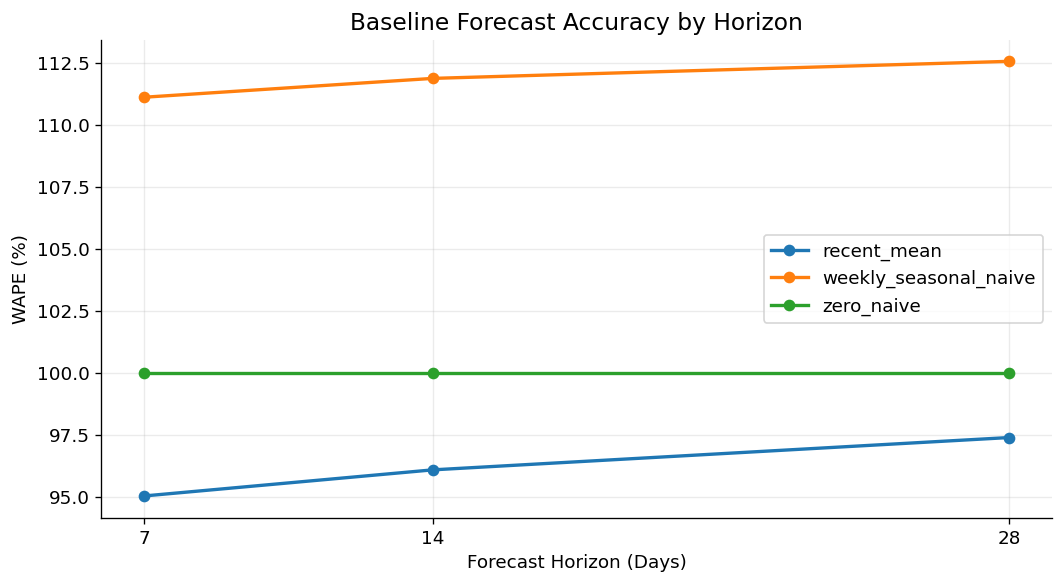

In [ ]:
#Visualize model comparison
# Compare WAPE across horizons
fig, ax = plt.subplots(figsize=(9, 5))
for model_name, group in evaluation_table.groupby("model"):
    group = group.sort_values("horizon")
    ax.plot(group["horizon"],group["WAPE_pct"],marker="o",linewidth=2,label=model_name)
ax.set_title("Baseline Forecast Accuracy by Horizon")
ax.set_xlabel("Forecast Horizon (Days)")
ax.set_ylabel("WAPE (%)")
ax.set_xticks(HORIZONS)
ax.legend()
ax.grid(alpha=0.25)
save_chart()

In [ ]:
#Save evaluation outputs
evaluation_table.to_csv(Forecasting_OUTPUT / "baseline_evaluation_metrics.csv",index=False)
ranked_models.to_csv(Forecasting_OUTPUT / "baseline_model_rankings.csv",index=False)
best_baselines.to_csv(Forecasting_OUTPUT / "best_baseline_by_horizon.csv",index=False)
print("Evaluation outputs saved to:", Forecasting_OUTPUT)

Evaluation outputs saved to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs


###**Preliminary Findings — 100-Series Prototype**

**Scope:** The initial evaluation was conducted on a 100-series prototype using rolling-origin validation across 7-, 14-, and 28-day forecasting horizons. Three baseline models were compared: Zero Naive, Weekly Seasonal Naive, and Recent Mean.

**Key Findings**

Recent Mean performed best across all three forecasting horizons. Its WAPE increased from 95.02% for the 7-day horizon to 96.08% for 14 days and 97.38% for 28 days.

Weekly Seasonal Naive underperformed the other baselines. Its WAPE ranged from 111.11% to 112.56%, suggesting that simply repeating the previous week's sales pattern was ineffective for this prototype.

Forecasting errors remained high across all models. Even the best-performing baseline had WAPE above 95%, indicating substantial room for improvement.

Zero-demand predictions were common. Weekly Seasonal Naive generated approximately 76.29% zero predictions, compared with 36.00% for Recent Mean in the prediction summary. This suggests that sparse or intermittent demand may be an important factor to investigate.

**Limitations**

These findings are preliminary and based on a small 100-series prototype designed primarily to validate the forecasting pipeline. The prototype is not sufficient to establish representative forecasting performance across the full M5 dataset. Differences across forecasting horizons may also reflect differences in evaluation windows.

**Next Steps**

Expand the evaluation to the 20% stratified sample (6,098 series).

Analyze forecasting errors by category, state, and demand pattern.

Investigate the impact of zero sales and intermittent demand.

Use the expanded evaluation to assess baseline suitability for inventory planning.

###**20% Sample Train / Validation / Test**

---



In [ ]:
# Prepare chronological splits for the 20% sample

sample20_train = get_sales_split(sales, sample_20_ids, train_days)
sample20_val = get_sales_split(sales, sample_20_ids, val_days)
sample20_test = get_sales_split(sales, sample_20_ids, test_days)
print("Train:", sample20_train.shape)
print("Validation:", sample20_val.shape)
print("Test:", sample20_test.shape)

Train: (6098, 1439)
Validation: (6098, 371)
Test: (6098, 149)


In [ ]:
### 20% Sample Horizon Evaluation
# Aggregate evaluation metrics for the 20% sample

evaluation_20 = (
    backtest_results_20
    .groupby(["horizon", "model"], as_index=False)
    .agg(
        n_origins=("origin_day", "nunique"),
        n_observations=("n_obs", "sum"),
        sum_abs_error=("sum_abs_error", "sum"),
        sum_sq_error=("sum_sq_error", "sum"),
        sum_actual=("sum_actual", "sum")
    )
)

evaluation_20["MAE"] = (
    evaluation_20["sum_abs_error"]
    / evaluation_20["n_observations"]
)

evaluation_20["RMSE"] = np.sqrt(
    evaluation_20["sum_sq_error"]
    / evaluation_20["n_observations"]
)

evaluation_20["WAPE_pct"] = np.where(
    evaluation_20["sum_actual"] > 0,
    evaluation_20["sum_abs_error"]
    / evaluation_20["sum_actual"] * 100,
    np.nan
)

evaluation_20 = evaluation_20[
    ["horizon", "model", "n_origins",
     "n_observations", "MAE", "RMSE", "WAPE_pct"]
].sort_values(["horizon", "WAPE_pct"])

display(evaluation_20.round(4))

,horizon,model,n_origins,n_observations,MAE,RMSE,WAPE_pct
0,7,recent_mean,52,2219672,0.9722,2.3214,76.4770
1,7,weekly_seasonal_naive,52,2219672,1.1433,2.8827,89.9398
2,7,zero_naive,52,2219672,1.2712,3.8636,100.0000
3,14,recent_mean,51,4353972,0.9952,2.3942,78.0601
4,14,weekly_seasonal_naive,51,4353972,1.1645,2.9483,91.3447
5,14,zero_naive,51,4353972,1.2749,3.8689,100.0000
6,28,recent_mean,49,8366456,1.0230,2.4859,80.0777
7,28,weekly_seasonal_naive,49,8366456,1.1881,3.0163,93.0013
8,28,zero_naive,49,8366456,1.2775,3.8713,100.0000


In [ ]:
# Rank baseline models by horizon — 20% sample
# Lower WAPE is better

ranked_models_20 = (
    evaluation_20
    .sort_values(
        ["horizon", "WAPE_pct"],
        ascending=[True, True]
    )
    .copy()
)

ranked_models_20["rank"] = (
    ranked_models_20.groupby("horizon").cumcount() + 1
)

display(
    ranked_models_20[
        ["horizon", "rank", "model", "MAE", "RMSE", "WAPE_pct"]
    ].round(4)
)

,horizon,rank,model,MAE,RMSE,WAPE_pct
0,7,1,recent_mean,0.9722,2.3214,76.4770
1,7,2,weekly_seasonal_naive,1.1433,2.8827,89.9398
2,7,3,zero_naive,1.2712,3.8636,100.0000
3,14,1,recent_mean,0.9952,2.3942,78.0601
4,14,2,weekly_seasonal_naive,1.1645,2.9483,91.3447
5,14,3,zero_naive,1.2749,3.8689,100.0000
6,28,1,recent_mean,1.0230,2.4859,80.0777
7,28,2,weekly_seasonal_naive,1.1881,3.0163,93.0013
8,28,3,zero_naive,1.2775,3.8713,100.0000


In [ ]:
# Identify best baseline per horizon — 20% sample
best_baselines_20 = ranked_models_20.loc[
    ranked_models_20["rank"] == 1
].copy()

print("Best baseline by horizon — 20% sample:")
display(
    best_baselines_20[
        ["horizon", "model", "MAE", "RMSE", "WAPE_pct"]
    ].round(4)
)

Best baseline by horizon — 20% sample:


,horizon,model,MAE,RMSE,WAPE_pct
0,7,recent_mean,0.9722,2.3214,76.4770
3,14,recent_mean,0.9952,2.3942,78.0601
6,28,recent_mean,1.0230,2.4859,80.0777


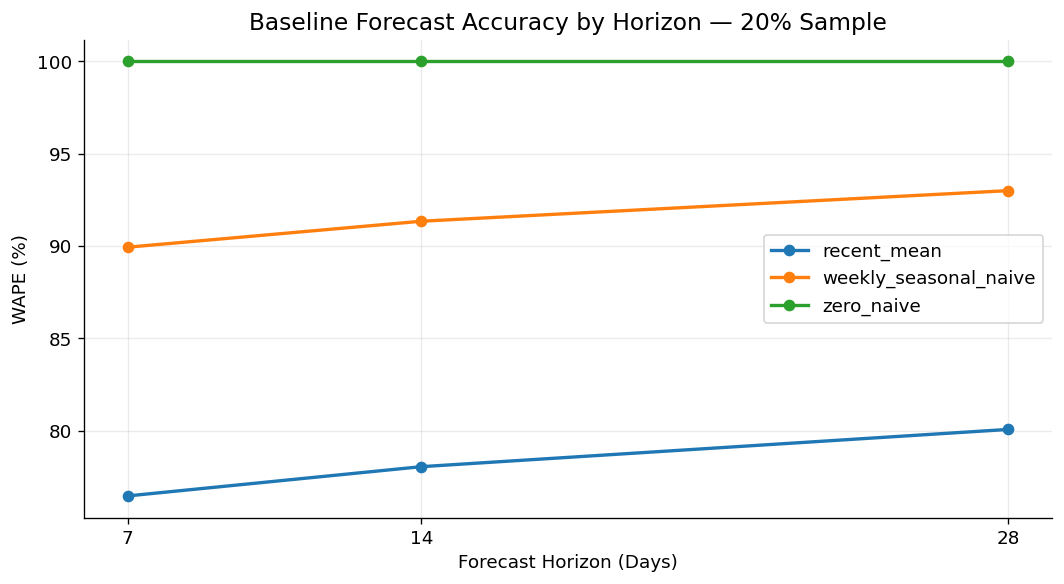

In [ ]:
# Visualize model comparison — 20% sample
# Compare WAPE across forecasting horizons
fig, ax = plt.subplots(figsize=(9, 5))
for model_name, group in evaluation_20.groupby("model"):
    group = group.sort_values("horizon")
    ax.plot(group["horizon"],group["WAPE_pct"],marker="o",linewidth=2,label=model_name)
ax.set_title("Baseline Forecast Accuracy by Horizon — 20% Sample")
ax.set_xlabel("Forecast Horizon (Days)")
ax.set_ylabel("WAPE (%)")
ax.set_xticks(HORIZONS)
ax.legend()
ax.grid(alpha=0.25)

save_chart()

In [ ]:
# Save 20% sample evaluation outputs
evaluation_20.to_csv(Forecasting_OUTPUT / "baseline_evaluation_metrics_20.csv",index=False)
ranked_models_20.to_csv(Forecasting_OUTPUT / "baseline_model_rankings_20.csv",index=False)
best_baselines_20.to_csv(Forecasting_OUTPUT / "best_baseline_by_horizon_20.csv",index=False)
print("20% sample evaluation outputs saved to:", Forecasting_OUTPUT)

20% sample evaluation outputs saved to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs


In [ ]:
# Aggregate evaluation metrics for the 50% sample
evaluation_50 = backtest_results_50.groupby(["horizon","model"],as_index=False).agg(n_origins=("origin_day","nunique"),n_observations=("n_obs","sum"),total_abs_error=("sum_abs_error","sum"),total_sq_error=("sum_sq_error","sum"),total_actual=("sum_actual","sum"))

evaluation_50["MAE"] = evaluation_50["total_abs_error"] / evaluation_50["n_observations"]
evaluation_50["RMSE"] = np.sqrt(evaluation_50["total_sq_error"] / evaluation_50["n_observations"])
evaluation_50["WAPE_pct"] = np.where(evaluation_50["total_actual"] > 0,evaluation_50["total_abs_error"] / evaluation_50["total_actual"] * 100,np.nan)

evaluation_50 = evaluation_50[["horizon","model","n_origins","n_observations","MAE","RMSE","WAPE_pct"]].sort_values(["horizon","WAPE_pct"])
display(evaluation_50.round(4))

,horizon,model,n_origins,n_observations,MAE,RMSE,WAPE_pct
0,7,recent_mean,52,5549180,0.9543,2.2226,77.5216
1,7,weekly_seasonal_naive,52,5549180,1.1217,2.7529,91.1185
2,7,zero_naive,52,5549180,1.2310,3.6717,100.0000
3,14,recent_mean,51,10884930,0.9763,2.2949,79.0587
4,14,weekly_seasonal_naive,51,10884930,1.1412,2.8161,92.4116
5,14,zero_naive,51,10884930,1.2349,3.6775,100.0000
6,28,recent_mean,49,20916140,1.0030,2.3811,81.0121
7,28,weekly_seasonal_naive,49,20916140,1.1640,2.8823,94.0158
8,28,zero_naive,49,20916140,1.2381,3.6820,100.0000


In [ ]:
# Rank 50% baseline models
ranked_models_50 = evaluation_50.sort_values(["horizon","WAPE_pct"]).copy()
ranked_models_50["rank"] = ranked_models_50.groupby("horizon").cumcount() + 1
best_baselines_50 = ranked_models_50[ranked_models_50["rank"] == 1].copy()

display(ranked_models_50[["horizon","rank","model","MAE","RMSE","WAPE_pct"]].round(4))

,horizon,rank,model,MAE,RMSE,WAPE_pct
0,7,1,recent_mean,0.9543,2.2226,77.5216
1,7,2,weekly_seasonal_naive,1.1217,2.7529,91.1185
2,7,3,zero_naive,1.2310,3.6717,100.0000
3,14,1,recent_mean,0.9763,2.2949,79.0587
4,14,2,weekly_seasonal_naive,1.1412,2.8161,92.4116
5,14,3,zero_naive,1.2349,3.6775,100.0000
6,28,1,recent_mean,1.0030,2.3811,81.0121
7,28,2,weekly_seasonal_naive,1.1640,2.8823,94.0158
8,28,3,zero_naive,1.2381,3.6820,100.0000


In [ ]:
# Compare sample sizes using identical evaluation methodology
comparison_20_50 = pd.concat([evaluation_20.assign(sample="20%",n_series=6098),evaluation_50.assign(sample="50%",n_series=15245)],ignore_index=True)

display(comparison_20_50[["sample","n_series","horizon","model","MAE","RMSE","WAPE_pct"]].sort_values(["horizon","model","sample"]).round(4))

,sample,n_series,horizon,model,MAE,RMSE,WAPE_pct
0,20%,6098,7,recent_mean,0.9722,2.3214,76.4770
9,50%,15245,7,recent_mean,0.9543,2.2226,77.5216
1,20%,6098,7,weekly_seasonal_naive,1.1433,2.8827,89.9398
10,50%,15245,7,weekly_seasonal_naive,1.1217,2.7529,91.1185
2,20%,6098,7,zero_naive,1.2712,3.8636,100.0000
11,50%,15245,7,zero_naive,1.2310,3.6717,100.0000
3,20%,6098,14,recent_mean,0.9952,2.3942,78.0601
12,50%,15245,14,recent_mean,0.9763,2.2949,79.0587
4,20%,6098,14,weekly_seasonal_naive,1.1645,2.9483,91.3447
13,50%,15245,14,weekly_seasonal_naive,1.1412,2.8161,92.4116


In [ ]:
# Calculate FVA relative to Weekly Seasonal Naive
kpi_fva = pd.concat([evaluation_table.assign(sample="prototype"),evaluation_20.assign(sample="20%"),evaluation_50.assign(sample="50%")],ignore_index=True)

reference = kpi_fva[kpi_fva["model"] == "weekly_seasonal_naive"][["sample","horizon","WAPE_pct"]].rename(columns={"WAPE_pct":"reference_WAPE_pct"})
kpi_fva = kpi_fva.merge(reference,on=["sample","horizon"],how="left",validate="many_to_one")
kpi_fva["FVA_pct"] = np.where(kpi_fva["reference_WAPE_pct"] > 0,(kpi_fva["reference_WAPE_pct"] - kpi_fva["WAPE_pct"]) / kpi_fva["reference_WAPE_pct"] * 100,np.nan)

display(kpi_fva[["sample","horizon","model","WAPE_pct","reference_WAPE_pct","FVA_pct"]].sort_values(["sample","horizon","FVA_pct"],ascending=[True,True,False]).round(4))

,sample,horizon,model,WAPE_pct,reference_WAPE_pct,FVA_pct
9,20%,7,recent_mean,76.4770,89.9398,14.9687
10,20%,7,weekly_seasonal_naive,89.9398,89.9398,0.0000
11,20%,7,zero_naive,100.0000,89.9398,-11.1855
12,20%,14,recent_mean,78.0601,91.3447,14.5433
13,20%,14,weekly_seasonal_naive,91.3447,91.3447,0.0000
14,20%,14,zero_naive,100.0000,91.3447,-9.4755
15,20%,28,recent_mean,80.0777,93.0013,13.8961
16,20%,28,weekly_seasonal_naive,93.0013,93.0013,0.0000
17,20%,28,zero_naive,100.0000,93.0013,-7.5254
18,50%,7,recent_mean,77.5216,91.1185,14.9222


In [ ]:
# Export evaluation and FVA outputs
evaluation_50.to_csv(Forecasting_OUTPUT / "baseline_evaluation_metrics_50.csv",index=False)
ranked_models_50.to_csv(Forecasting_OUTPUT / "baseline_model_rankings_50.csv",index=False)
best_baselines_50.to_csv(Forecasting_OUTPUT / "best_baseline_by_horizon_50.csv",index=False)
comparison_20_50.to_csv(Forecasting_OUTPUT / "sample_comparison_20_50.csv",index=False)
kpi_fva.to_csv(Forecasting_OUTPUT / "forecast_value_added_kpi.csv",index=False)

print("50% evaluation, sample comparison, and FVA exported successfully.")

50% evaluation, sample comparison, and FVA exported successfully.


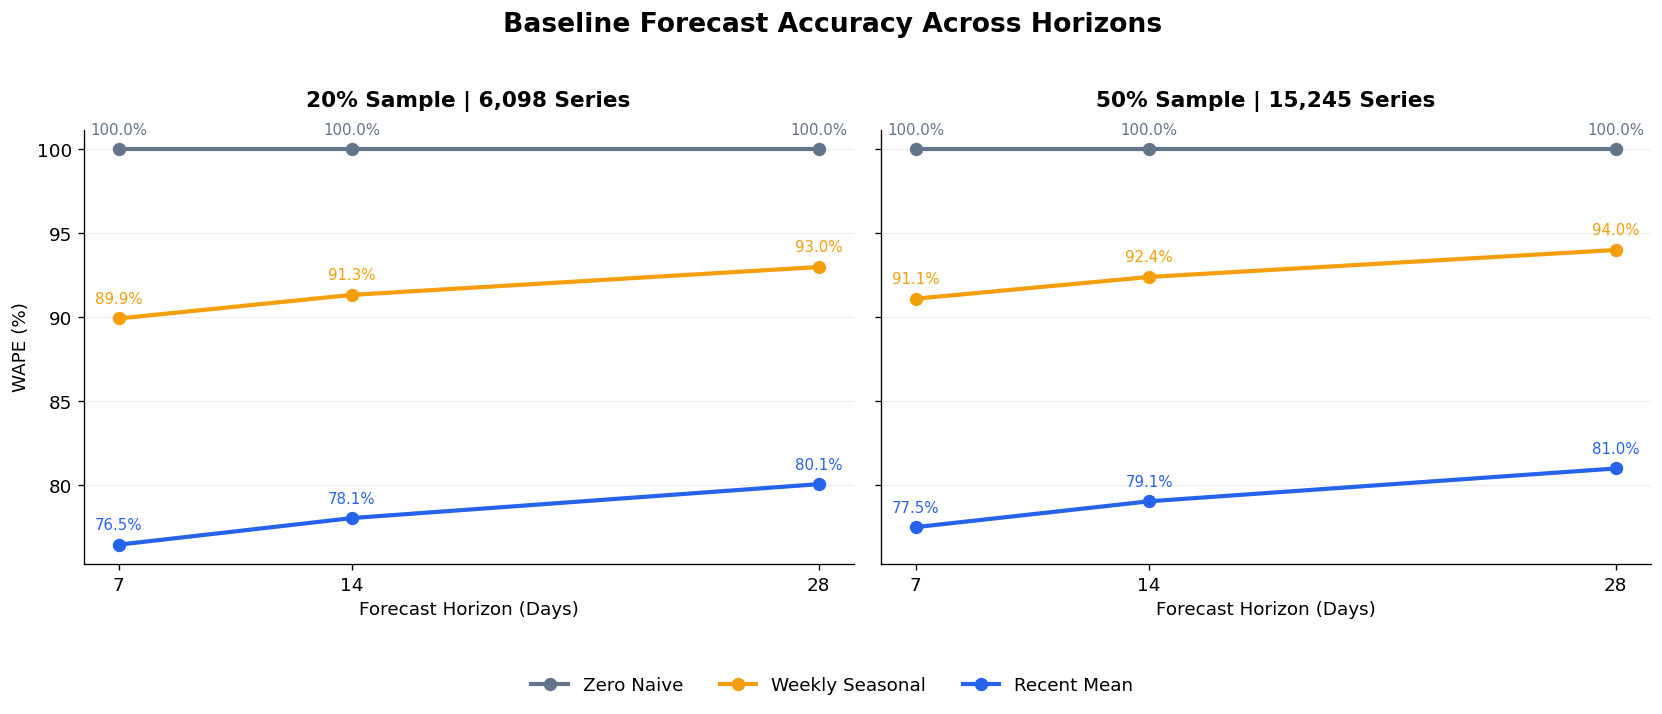

In [ ]:
# Figure 5 — Baseline WAPE by Horizon: 20% vs. 50%
model_order = ["zero_naive", "weekly_seasonal_naive", "recent_mean"]
model_labels = {"zero_naive": "Zero Naive", "weekly_seasonal_naive": "Weekly Seasonal", "recent_mean": "Recent Mean"}
model_colors = {"zero_naive": "#64748B", "weekly_seasonal_naive": "#F59E0B", "recent_mean": "#2563EB"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

for ax, (sample_name, df, n_series) in zip(axes, [("20% Sample", evaluation_20, 6098), ("50% Sample", evaluation_50, 15245)]):
    for model in model_order:
        group = df[df["model"] == model].sort_values("horizon")
        ax.plot(group["horizon"], group["WAPE_pct"], marker="o", markersize=7, linewidth=2.5, color=model_colors[model], label=model_labels[model])
        for x, y in zip(group["horizon"], group["WAPE_pct"]):
            ax.annotate(f"{y:.1f}%", (x, y), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9, color=model_colors[model])
    ax.set_title(f"{sample_name} | {n_series:,} Series", fontsize=13, fontweight="bold", pad=14)
    ax.set_xlabel("Forecast Horizon (Days)")
    ax.set_xticks(HORIZONS)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("WAPE (%)")
fig.suptitle("Baseline Forecast Accuracy Across Horizons", fontsize=16, fontweight="bold", y=1.02)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=3, frameon=False)
fig.tight_layout(rect=[0, 0.07, 1, 1])
fig.savefig(Forecasting_OUTPUT / "figure5_baseline_wape_by_horizon.png", dpi=300, bbox_inches="tight")
plt.show()

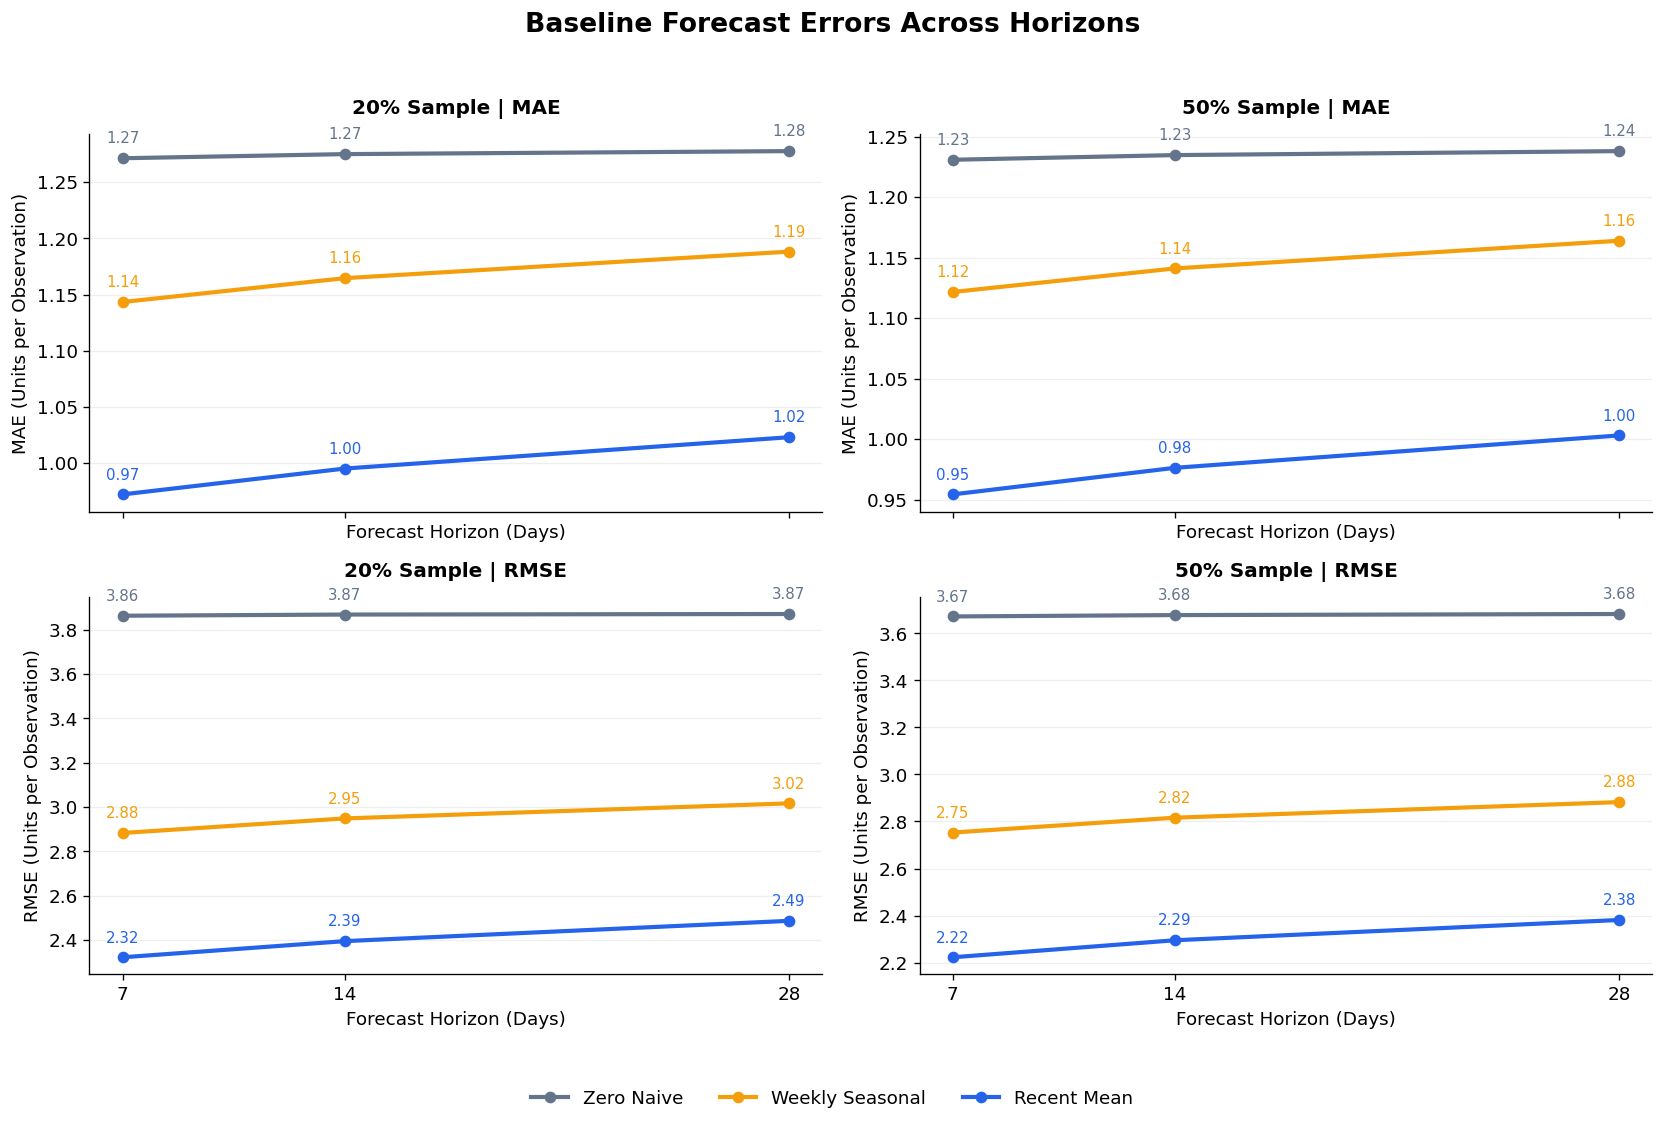

In [ ]:
# Figure 6 — MAE and RMSE by Horizon: 20% vs. 50%
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)

for col, (sample_name, df, n_series) in enumerate([("20% Sample", evaluation_20, 6098), ("50% Sample", evaluation_50, 15245)]):
    for row, metric in enumerate(["MAE", "RMSE"]):
        ax = axes[row, col]
        for model in model_order:
            group = df[df["model"] == model].sort_values("horizon")
            ax.plot(group["horizon"], group[metric], marker="o", markersize=6, linewidth=2.5, color=model_colors[model], label=model_labels[model])
            for x, y in zip(group["horizon"], group[metric]):
                ax.annotate(f"{y:.2f}", (x, y), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9, color=model_colors[model])
        ax.set_title(f"{sample_name} | {metric}", fontsize=12, fontweight="bold", pad=12)
        ax.set_xticks(HORIZONS)
        ax.set_xlabel("Forecast Horizon (Days)")
        ax.set_ylabel(f"{metric} (Units per Observation)")
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Baseline Forecast Errors Across Horizons", fontsize=16, fontweight="bold", y=1.02)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.01), ncol=3, frameon=False)
fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig(Forecasting_OUTPUT / "figure6_baseline_mae_rmse_by_horizon.png", dpi=300, bbox_inches="tight")
plt.show()

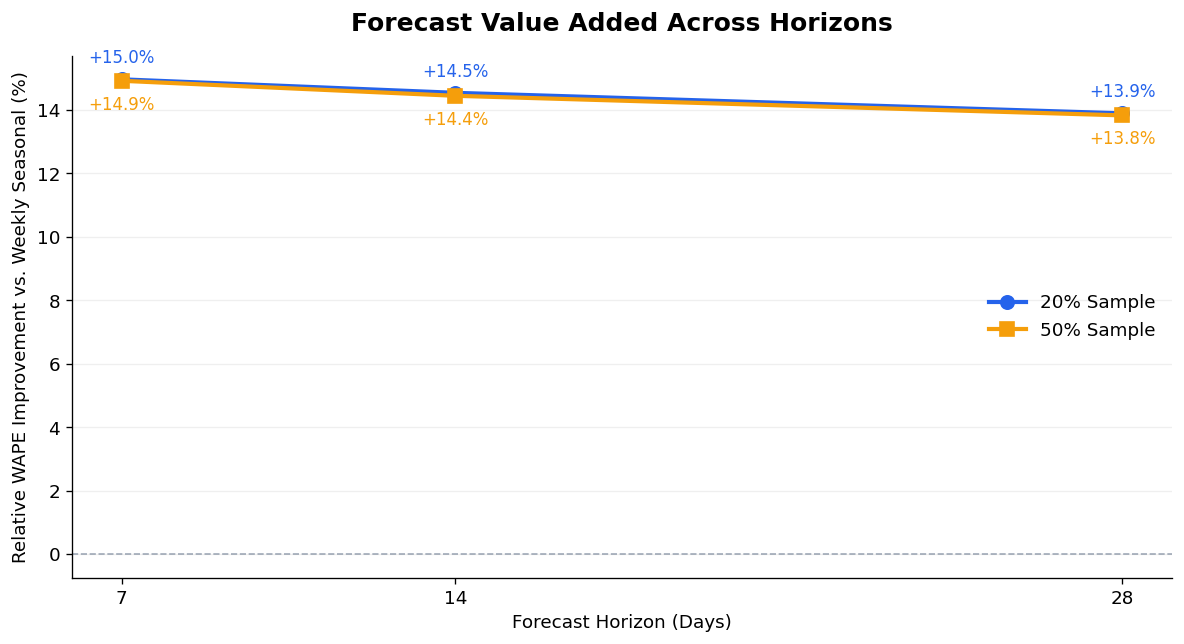

In [ ]:
# Figure 7 — Forecast Value Added: Recent Mean vs. Weekly Seasonal
fig, ax = plt.subplots(figsize=(10, 5.5))

for sample_name, df, color, marker in [("20% Sample", evaluation_20, "#2563EB", "o"), ("50% Sample", evaluation_50, "#F59E0B", "s")]:
    pivot = df.pivot(index="horizon", columns="model", values="WAPE_pct").sort_index()
    fva = (pivot["weekly_seasonal_naive"] - pivot["recent_mean"]) / pivot["weekly_seasonal_naive"] * 100
    ax.plot(fva.index, fva.values, marker=marker, markersize=8, linewidth=2.5, color=color, label=sample_name)
    for x, y in zip(fva.index, fva.values):
        ax.annotate(f"{y:+.1f}%", (x, y), xytext=(0, 10 if sample_name == "20% Sample" else -17), textcoords="offset points", ha="center", fontsize=10, color=color)

ax.axhline(0, color="#64748B", linestyle="--", linewidth=1, alpha=0.6)
ax.set_title("Forecast Value Added Across Horizons", fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Forecast Horizon (Days)")
ax.set_ylabel("Relative WAPE Improvement vs. Weekly Seasonal (%)")
ax.set_xticks(HORIZONS)
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure7_forecast_value_added.png", dpi=300, bbox_inches="tight")
plt.show()

## Findings — Baseline Forecast Evaluation, Sample Stability, and FVA

### 1. Evaluation Overview

Three baseline models—**Zero Naive, Weekly Seasonal Naive, and Recent Mean**—were evaluated using expanding-window rolling-origin validation across **7-, 14-, and 28-day horizons**.

The evaluation covered the **100-series prototype, 20% sample (6,098 series), and 50% sample (15,245 series)**, with 456 model evaluations per sample. Pooled MAE, RMSE, and WAPE were calculated using the 2015 validation period, while the 2016 test period remained untouched.

### 2. Model Performance and Sample Stability

**Recent Mean consistently achieved the lowest WAPE, MAE, and RMSE** across all horizons and sample sizes.

| Sample | 7-Day WAPE | 14-Day WAPE | 28-Day WAPE |
|---|---:|---:|---:|
| Prototype | 95.02% | 96.08% | 97.38% |
| 20% Sample | 76.48% | 78.06% | 80.08% |
| 50% Sample | 77.52% | 79.06% | 81.01% |

On the 50% sample, Weekly Seasonal Naive achieved WAPE of 91.12%–94.02%, while Zero Naive remained at 100%.

Model rankings were consistent between the 20% and 50% samples. Recent Mean WAPE differed by approximately **0.93–1.04 percentage points**, indicating relatively stable performance across these samples.

WAPE increased with longer forecast horizons, although differences in rolling-origin evaluation windows may also contribute to this pattern.

### 3. Forecast Value Added (FVA)

Compared with Weekly Seasonal Naive, Recent Mean achieved positive relative WAPE improvement across all horizons.

| Sample | 7-Day FVA | 14-Day FVA | 28-Day FVA |
|---|---:|---:|---:|
| 20% Sample | +14.97% | +14.54% | +13.90% |
| 50% Sample | +14.92% | +14.45% | +13.83% |

**Recent Mean reduced WAPE by approximately 14%–15% relative to Weekly Seasonal Naive**, with slightly smaller improvements at longer horizons.

### 4. Business Implications and Next Steps

**Recent Mean is the preferred baseline benchmark** for subsequent forecasting comparisons, including TimeCopilot.

However, WAPE remains relatively high, highlighting challenges associated with sparse and intermittent demand. Forecast accuracy improvements alone do not demonstrate reductions in inventory costs or stockouts.

Further analysis will focus on **Forecast Bias, State × Category errors, demand characteristics, and P10/P90 prediction interval reliability**, followed by comparisons with more advanced forecasting models.

The **2016 test period remains reserved for final out-of-sample evaluation**.

**Key Takeaway:** Recent Mean provides the strongest and most consistent baseline across the evaluated horizons and sample sizes, establishing a measurable benchmark for future forecasting improvements and inventory decision support.

# 9. Error Analysis

In [ ]:
#Prepare metadata for the 20% sample
series_ids_20 = sample20_tv["id"].tolist()
metadata_20 = (sample20_tv[["id", "state_id", "cat_id", "store_id"]].copy().reset_index(drop=True))
# Validate alignment
assert len(metadata_20) == sample20_matrix.shape[0] == 6098
assert metadata_20["id"].tolist() == series_ids_20
assert metadata_20["id"].is_unique
print("20% sample metadata alignment: PASSED")
display(metadata_20.head())

# Count series by state and category
group_counts_20 = (metadata_20.groupby(["state_id", "cat_id"], observed=True).size().reset_index(name="n_series"))
display(group_counts_20)

20% sample metadata alignment: PASSED


,id,state_id,cat_id,store_id
0,HOBBIES_1_003_CA_1_evaluation,CA,HOBBIES,CA_1
1,HOBBIES_1_009_CA_1_evaluation,CA,HOBBIES,CA_1
2,HOBBIES_1_014_CA_1_evaluation,CA,HOBBIES,CA_1
3,HOBBIES_1_020_CA_1_evaluation,CA,HOBBIES,CA_1
4,HOBBIES_1_031_CA_1_evaluation,CA,HOBBIES,CA_1


,state_id,cat_id,n_series
0,CA,FOODS,1150
1,CA,HOBBIES,452
2,CA,HOUSEHOLD,838
3,TX,FOODS,862
4,TX,HOBBIES,339
5,TX,HOUSEHOLD,628
6,WI,FOODS,862
7,WI,HOBBIES,339
8,WI,HOUSEHOLD,628


In [ ]:
# Prepare metadata for the 50% sample
series_ids_50 = sample50_tv["id"].tolist()
metadata_50 = sample50_tv[["id", "state_id", "cat_id", "store_id"]].copy().reset_index(drop=True)

assert len(metadata_50) == sample50_matrix.shape[0] == 15245
assert metadata_50["id"].tolist() == series_ids_50
assert metadata_50["id"].is_unique
assert set(metadata_20["id"]).issubset(set(metadata_50["id"]))

group_counts_50 = metadata_50.groupby(["state_id", "cat_id"], observed=True).size().reset_index(name="n_series")
print("50% sample metadata alignment: PASSED")
display(group_counts_50)

50% sample metadata alignment: PASSED


,state_id,cat_id,n_series
0,CA,FOODS,2874
1,CA,HOBBIES,1130
2,CA,HOUSEHOLD,2094
3,TX,FOODS,2156
4,TX,HOBBIES,848
5,TX,HOUSEHOLD,1571
6,WI,FOODS,2155
7,WI,HOBBIES,847
8,WI,HOUSEHOLD,1570


In [ ]:
import inspect
print("Baseline function:")
print(inspect.signature(generate_baselines))
print("\nBacktesting function:")
print(inspect.signature(rolling_origin_backtest))
print("\nData dimensions:")
print("sample20_matrix:", sample20_matrix.shape)
print("Train days:", len(train_days))
print("Validation days:", len(val_days))

Baseline function:
(history, horizon, recent_mean_window=7, season_length=7)

Backtesting function:
(sales_matrix, day_cols, train_length, horizons=(7, 14, 28), step=7, recent_mean_window=7, season_length=7)

Data dimensions:
sample20_matrix: (6098, 1798)
Train days: 1433
Validation days: 365


In [ ]:
# Reusable State × Category Error Analysis
def analyze_group_errors(matrix, metadata):
    results = []

    for (state, category), group in metadata.groupby(["state_id", "cat_id"], observed=True):
        group_matrix = matrix[group.index.to_numpy()]

        group_backtest = rolling_origin_backtest(
            sales_matrix=group_matrix, day_cols=train_val_days, train_length=len(train_days),
            horizons=HORIZONS, step=STEP, recent_mean_window=RECENT_MEAN_WINDOW, season_length=SEASON_LENGTH
        )

        summary = group_backtest.groupby(["horizon", "model"], as_index=False).agg(
            n_origins=("origin_day", "nunique"), n_observations=("n_obs", "sum"),
            sum_abs_error=("sum_abs_error", "sum"), sum_sq_error=("sum_sq_error", "sum"),
            sum_actual=("sum_actual", "sum")
        )

        summary["MAE"] = summary["sum_abs_error"] / summary["n_observations"]
        summary["RMSE"] = np.sqrt(summary["sum_sq_error"] / summary["n_observations"])
        summary["WAPE_pct"] = np.where(summary["sum_actual"] > 0, 100 * summary["sum_abs_error"] / summary["sum_actual"], np.nan)

        summary["state_id"], summary["cat_id"], summary["n_series"] = state, category, len(group)
        results.append(summary)

    result = pd.concat(results, ignore_index=True)
    return result[["state_id", "cat_id", "n_series", "horizon", "model", "n_origins", "n_observations",
                   "sum_abs_error", "sum_sq_error", "sum_actual", "MAE", "RMSE", "WAPE_pct"]]


# Run identical analysis on both samples
group_error_20 = analyze_group_errors(sample20_matrix, metadata_20)
group_error_50 = analyze_group_errors(sample50_matrix, metadata_50)

assert len(group_error_20) == 81
assert len(group_error_50) == 81

print("20% rows:", len(group_error_20))
print("50% rows:", len(group_error_50))

display(group_error_20.head())
display(group_error_50.head())

20% rows: 81
50% rows: 81


,state_id,cat_id,n_series,horizon,model,n_origins,n_observations,sum_abs_error,sum_sq_error,sum_actual,MAE,RMSE,WAPE_pct
0,CA,FOODS,1150,7,recent_mean,52,418600,5.247743e+05,3.083307e+06,737438.0,1.253641,2.713993,71.161818
1,CA,FOODS,1150,7,weekly_seasonal_naive,52,418600,6.221280e+05,4.682684e+06,737438.0,1.486211,3.344628,84.363431
2,CA,FOODS,1150,7,zero_naive,52,418600,7.374380e+05,8.546494e+06,737438.0,1.761677,4.518501,100.000000
3,CA,FOODS,1150,14,recent_mean,51,821100,1.055390e+06,6.481353e+06,1450382.0,1.285337,2.809537,72.766367
4,CA,FOODS,1150,14,weekly_seasonal_naive,51,821100,1.244026e+06,9.666948e+06,1450382.0,1.515072,3.431205,85.772300


,state_id,cat_id,n_series,horizon,model,n_origins,n_observations,sum_abs_error,sum_sq_error,sum_actual,MAE,RMSE,WAPE_pct
0,CA,FOODS,2874,7,recent_mean,52,1046136,1.274140e+06,6.845416e+06,1798585.0,1.217949,2.558031,70.841237
1,CA,FOODS,2874,7,weekly_seasonal_naive,52,1046136,1.505627e+06,1.022229e+07,1798585.0,1.439227,3.125935,83.711751
2,CA,FOODS,2874,7,zero_naive,52,1046136,1.798585e+06,2.167359e+07,1798585.0,1.719265,4.551676,100.000000
3,CA,FOODS,2874,14,recent_mean,51,2052036,2.559643e+06,1.424429e+07,3538101.0,1.247367,2.634681,72.345100
4,CA,FOODS,2874,14,weekly_seasonal_naive,51,2052036,3.006435e+06,2.086691e+07,3538101.0,1.465099,3.188868,84.973125


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
# Reconcile grouped and overall metrics
def reconcile_group_errors(group_errors, overall):
    reconciled = group_errors.groupby(["horizon", "model"], as_index=False).agg(
        sum_abs_error=("sum_abs_error", "sum"), sum_sq_error=("sum_sq_error", "sum"),
        sum_actual=("sum_actual", "sum"), n_observations=("n_observations", "sum")
    )

    reconciled["MAE"] = reconciled["sum_abs_error"] / reconciled["n_observations"]
    reconciled["RMSE"] = np.sqrt(reconciled["sum_sq_error"] / reconciled["n_observations"])
    reconciled["WAPE_pct"] = 100 * reconciled["sum_abs_error"] / reconciled["sum_actual"]

    comparison = reconciled.merge(overall[["horizon", "model", "MAE", "RMSE", "WAPE_pct"]],
                                  on=["horizon", "model"], suffixes=("_grouped", "_overall"), validate="one_to_one")

    assert len(comparison) == 9
    for metric in ["MAE", "RMSE", "WAPE_pct"]:
        assert np.allclose(comparison[f"{metric}_grouped"], comparison[f"{metric}_overall"],
                           rtol=1e-5, atol=1e-5), f"{metric} reconciliation failed"

    return comparison

reconciliation_20 = reconcile_group_errors(group_error_20, evaluation_20)
reconciliation_50 = reconcile_group_errors(group_error_50, evaluation_50)

print("20% Reconciliation: PASSED")
print("50% Reconciliation: PASSED")

20% Reconciliation: PASSED
50% Reconciliation: PASSED


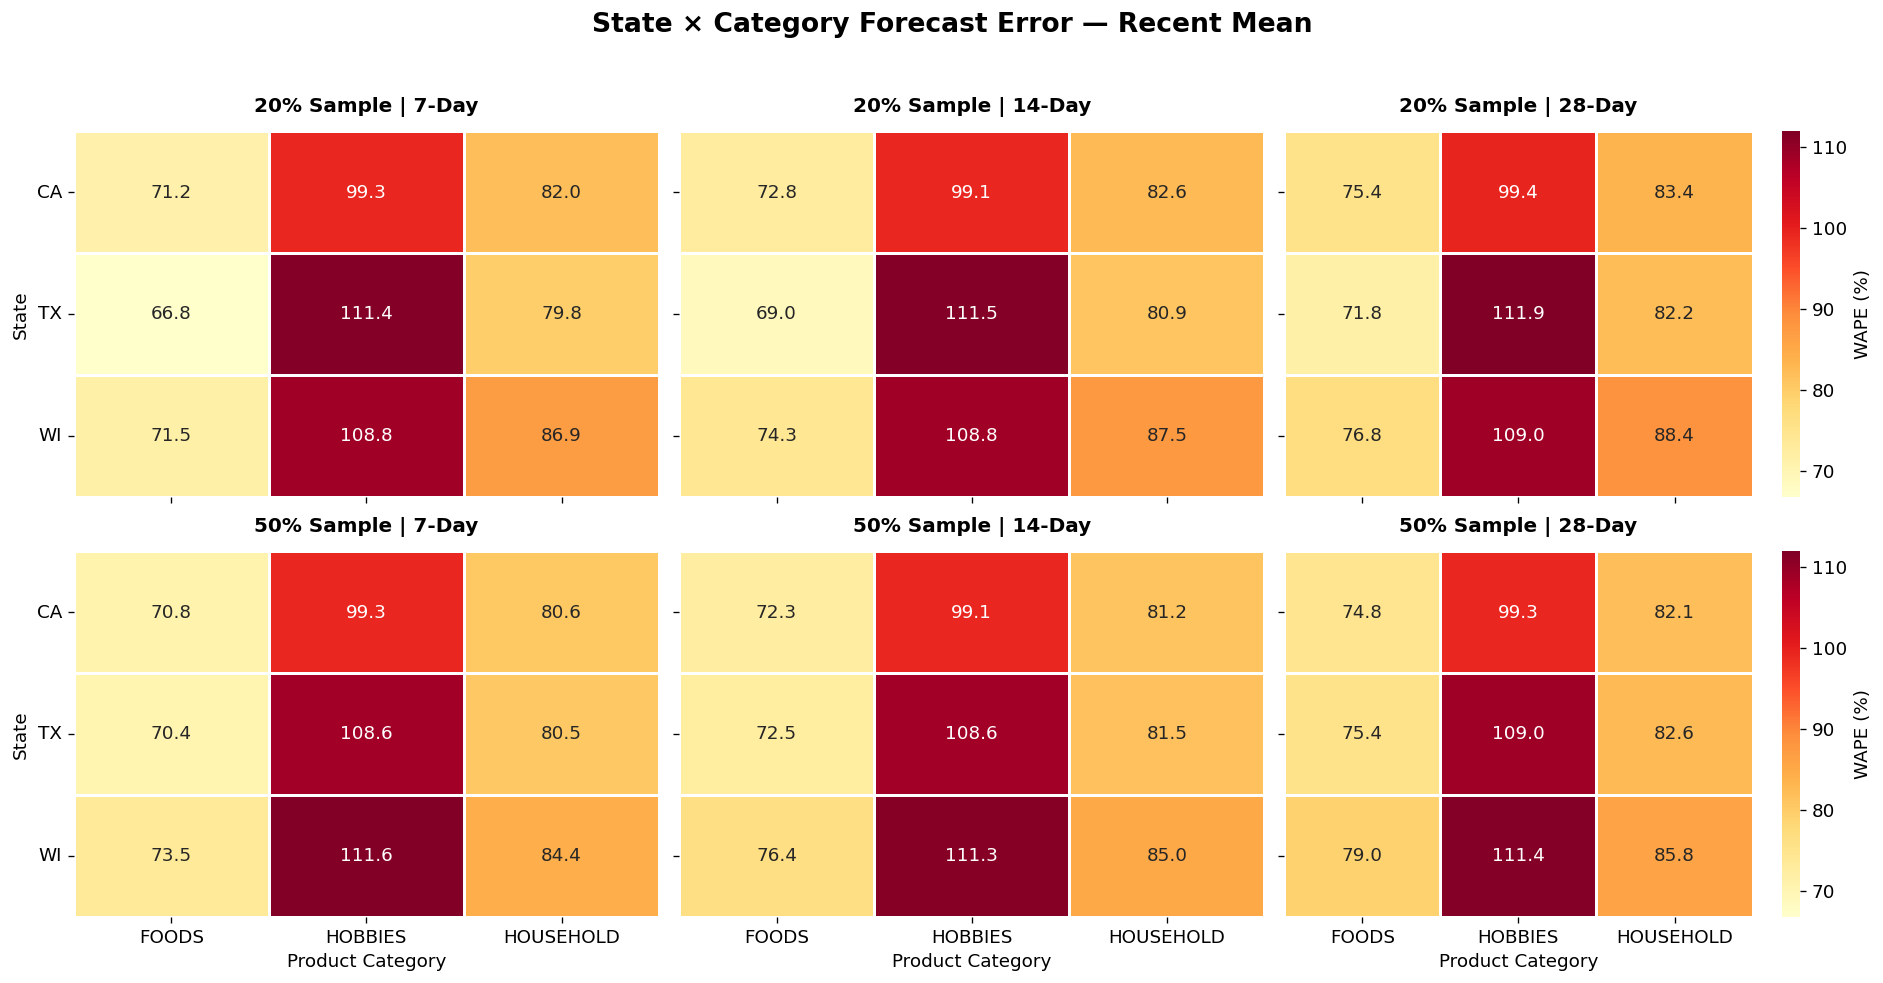

In [ ]:
# Figure 8 — State × Category WAPE Across Horizons
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey=True)
samples = [("20% Sample", group_error_20), ("50% Sample", group_error_50)]
states = ["CA", "TX", "WI"]
categories = ["FOODS", "HOBBIES", "HOUSEHOLD"]

all_wape = pd.concat([group_error_20, group_error_50], ignore_index=True)
all_wape = all_wape.loc[all_wape["model"] == "recent_mean", "WAPE_pct"]
vmin, vmax = all_wape.min(), all_wape.max()

for row, (sample_name, df) in enumerate(samples):
    for col, horizon in enumerate(HORIZONS):
        selected = df[(df["model"] == "recent_mean") & (df["horizon"] == horizon)]
        heatmap_data = selected.pivot(index="state_id", columns="cat_id", values="WAPE_pct").reindex(index=states, columns=categories)

        ax = axes[row, col]
        sns.heatmap(heatmap_data, ax=ax, annot=True, fmt=".1f", cmap="YlOrRd", vmin=vmin, vmax=vmax, linewidths=0.7, linecolor="white", cbar=(col == 2), cbar_kws={"label": "WAPE (%)"})
        ax.set_title(f"{sample_name} | {horizon}-Day", fontsize=12, fontweight="bold", pad=12)
        ax.set_xlabel("Product Category" if row == 1 else "")
        ax.set_ylabel("State" if col == 0 else "")
        ax.tick_params(axis="x", rotation=0)
        ax.tick_params(axis="y", rotation=0)

fig.suptitle("State × Category Forecast Error — Recent Mean", fontsize=16, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure8_state_category_wape_all_horizons.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#Compare 20% vs 50% robustness
group_20_7 = group_error_20.query("model == 'recent_mean' and horizon == 7")[["state_id", "cat_id", "WAPE_pct"]].rename(columns={"WAPE_pct": "WAPE_20"})
group_50_7 = group_error_50.query("model == 'recent_mean' and horizon == 7")[["state_id", "cat_id", "n_series", "WAPE_pct"]].rename(columns={"WAPE_pct": "WAPE_50"})

group_comparison = group_20_7.merge(group_50_7, on=["state_id", "cat_id"], validate="one_to_one")
group_comparison["WAPE_diff_pp"] = group_comparison["WAPE_50"] - group_comparison["WAPE_20"]

assert len(group_comparison) == 9

display(group_comparison.sort_values(["state_id", "cat_id"]).round(2))
print("Maximum absolute WAPE difference:", round(group_comparison["WAPE_diff_pp"].abs().max(), 2), "percentage points")

,state_id,cat_id,WAPE_20,n_series,WAPE_50,WAPE_diff_pp
0,CA,FOODS,71.16,2874,70.84,-0.32
1,CA,HOBBIES,99.33,1130,99.26,-0.07
2,CA,HOUSEHOLD,82.03,2094,80.61,-1.42
3,TX,FOODS,66.85,2156,70.40,3.55
4,TX,HOBBIES,111.39,848,108.56,-2.82
5,TX,HOUSEHOLD,79.76,1571,80.52,0.75
6,WI,FOODS,71.53,2155,73.49,1.96
7,WI,HOBBIES,108.82,847,111.64,2.81
8,WI,HOUSEHOLD,86.93,1570,84.42,-2.51


Maximum absolute WAPE difference: 3.55 percentage points


In [ ]:
#Export Error Analysis results
group_error_20.to_csv(
    Forecasting_OUTPUT / "group_error_analysis_20.csv",
    index=False
)
group_error_50.to_csv(
    Forecasting_OUTPUT / "group_error_analysis_50.csv",
    index=False
)
group_comparison.to_csv(
    Forecasting_OUTPUT / "state_category_comparison_20_50.csv",
    index=False
)
print("Section 11 Error Analysis exported successfully.")

Section 11 Error Analysis exported successfully.


### Interim Findings — State × Category Error Analysis and Sample Robustness

The State × Category error analysis was conducted on both the 20% (6,098 series) and 50% (15,245 series) stratified samples using identical rolling-origin backtesting procedures.

**Key Findings**

1. **Consistent forecast difficulty across categories:** For the 7-day Recent Mean baseline, FOODS consistently achieved the lowest WAPE across all three states, followed by HOUSEHOLD, while HOBBIES exhibited the highest WAPE in both samples.

2. **Stable results across sample sizes:** The category-level error patterns remained consistent between the 20% and 50% samples. Across the nine State × Category groups, the maximum absolute WAPE difference was 3.55 percentage points (TX FOODS).

3. **Validated error aggregation:** Both samples passed reconciliation checks, confirming that State × Category error aggregates reproduce the overall MAE, RMSE, and WAPE metrics for all three baseline models and forecasting horizons (7, 14, and 28 days).

**Business Implications**

The consistent difficulty of forecasting HOBBIES suggests that forecasting approaches may need to account for category-specific demand characteristics. However, high relative forecast error does not necessarily imply the largest aggregate business impact.

**Limitations and Next Steps**

Because the 20% sample is nested within the 50% sample, this comparison provides descriptive robustness evidence rather than an independent statistical significance test. Further analysis of zero-sales frequency, absolute error contribution, and forecast bias will help explain the observed differences and identify business priorities.

### Recent Mean (7-Day)

Recent Mean consistently achieved the lowest WAPE, MAE, and RMSE among the evaluated baselines, while the 7-day horizon represents a relevant short-term forecasting scenario for weekly inventory planning.

This focused analysis examines demand sparsity, forecast error concentration, and category-level differences across both the 20% and 50% samples. The objective is to identify where the strongest baseline still struggles and which product categories may warrant further forecasting improvements.

**Scope:** Findings from these diagnostic analyses apply specifically to the 7-day Recent Mean baseline and should not be generalized to other models or forecasting horizons without additional evaluation.

In [ ]:
#Demand Pattern Analysis (Training Data Only)

def analyze_demand_patterns(matrix, metadata):
    train_matrix = matrix[:, :len(train_days)]
    result = metadata.copy()

    result["zero_sales_rate"] = (train_matrix == 0).mean(axis=1)
    result["avg_daily_sales"] = train_matrix.mean(axis=1)

    summary = result.groupby(["state_id", "cat_id"], observed=True).agg(
        n_series=("id", "size"), avg_zero_sales_rate=("zero_sales_rate", "mean"),
        avg_daily_sales=("avg_daily_sales", "mean")
    ).reset_index()

    summary["zero_sales_pct"] = summary["avg_zero_sales_rate"] * 100
    return result, summary


metadata_20, demand_pattern_20 = analyze_demand_patterns(sample20_matrix, metadata_20)
metadata_50, demand_pattern_50 = analyze_demand_patterns(sample50_matrix, metadata_50)

assert len(metadata_20) == 6098 and len(metadata_50) == 15245
assert len(demand_pattern_20) == len(demand_pattern_50) == 9

print("Demand Pattern Analysis — 20% Sample")
display(demand_pattern_20[["state_id", "cat_id", "n_series", "zero_sales_pct", "avg_daily_sales"]].round(2))

print("Demand Pattern Analysis — 50% Sample")
display(demand_pattern_50[["state_id", "cat_id", "n_series", "zero_sales_pct", "avg_daily_sales"]].round(2))

Demand Pattern Analysis — 20% Sample


,state_id,cat_id,n_series,zero_sales_pct,avg_daily_sales
0,CA,FOODS,1150,63.04,1.71
1,CA,HOBBIES,452,77.30,0.68
2,CA,HOUSEHOLD,838,71.71,0.70
3,TX,FOODS,862,65.38,1.76
4,TX,HOBBIES,339,79.84,0.46
5,TX,HOUSEHOLD,628,74.90,0.69
6,WI,FOODS,862,65.01,1.58
7,WI,HOBBIES,339,80.17,0.47
8,WI,HOUSEHOLD,628,77.17,0.55


Demand Pattern Analysis — 50% Sample


,state_id,cat_id,n_series,zero_sales_pct,avg_daily_sales
0,CA,FOODS,2874,63.92,1.61
1,CA,HOBBIES,1130,77.48,0.65
2,CA,HOUSEHOLD,2094,72.03,0.73
3,TX,FOODS,2156,65.54,1.54
4,TX,HOBBIES,848,79.90,0.46
5,TX,HOUSEHOLD,1571,74.07,0.72
6,WI,FOODS,2155,66.23,1.50
7,WI,HOBBIES,847,80.95,0.45
8,WI,HOUSEHOLD,1570,77.37,0.57


20% Sample — Zero-Sales vs. WAPE Correlation: 0.903


,state_id,cat_id,zero_sales_pct,avg_daily_sales,WAPE_pct
0,CA,FOODS,63.04,1.71,71.16
1,CA,HOBBIES,77.30,0.68,99.33
2,CA,HOUSEHOLD,71.71,0.70,82.03
3,TX,FOODS,65.38,1.76,66.85
4,TX,HOBBIES,79.84,0.46,111.39
5,TX,HOUSEHOLD,74.90,0.69,79.76
6,WI,FOODS,65.01,1.58,71.53
7,WI,HOBBIES,80.17,0.47,108.82
8,WI,HOUSEHOLD,77.17,0.55,86.93


50% Sample — Zero-Sales vs. WAPE Correlation: 0.908


,state_id,cat_id,zero_sales_pct,avg_daily_sales,WAPE_pct
0,CA,FOODS,63.92,1.61,70.84
1,CA,HOBBIES,77.48,0.65,99.26
2,CA,HOUSEHOLD,72.03,0.73,80.61
3,TX,FOODS,65.54,1.54,70.40
4,TX,HOBBIES,79.90,0.46,108.56
5,TX,HOUSEHOLD,74.07,0.72,80.52
6,WI,FOODS,66.23,1.50,73.49
7,WI,HOBBIES,80.95,0.45,111.64
8,WI,HOUSEHOLD,77.37,0.57,84.42


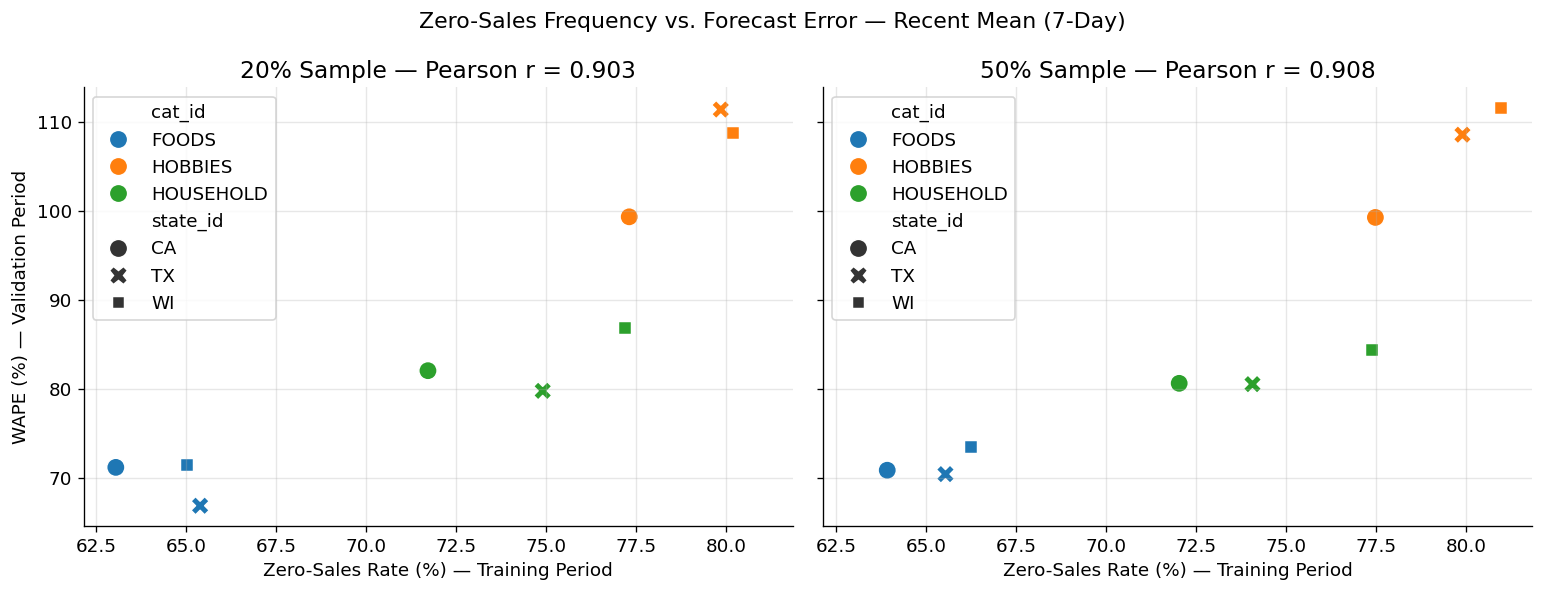

In [ ]:
# Zero-Sales Rate vs. Forecast Error

def analyze_demand_error(demand_pattern, group_errors, sample_label):
    wape_7d = group_errors.query("model == 'recent_mean' and horizon == 7")[["state_id", "cat_id", "WAPE_pct"]]
    result = demand_pattern.merge(wape_7d, on=["state_id", "cat_id"], validate="one_to_one")
    correlation = result["zero_sales_pct"].corr(result["WAPE_pct"])

    print(f"{sample_label}% Sample — Zero-Sales vs. WAPE Correlation: {correlation:.3f}")
    display(result[["state_id", "cat_id", "zero_sales_pct", "avg_daily_sales", "WAPE_pct"]].round(2))
    return result, correlation

demand_error_20, correlation_20 = analyze_demand_error(demand_pattern_20, group_error_20, "20")
demand_error_50, correlation_50 = analyze_demand_error(demand_pattern_50, group_error_50, "50")

# Compare both samples visually
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

for ax, data, label, corr in zip(axes, [demand_error_20, demand_error_50], ["20%", "50%"], [correlation_20, correlation_50]):
    sns.scatterplot(data=data, x="zero_sales_pct", y="WAPE_pct", hue="cat_id", style="state_id", s=120, ax=ax)
    ax.set_title(f"{label} Sample — Pearson r = {corr:.3f}")
    ax.set_xlabel("Zero-Sales Rate (%) — Training Period")
    ax.set_ylabel("WAPE (%) — Validation Period")
    ax.grid(alpha=0.3)

plt.suptitle("Zero-Sales Frequency vs. Forecast Error — Recent Mean (7-Day)")
plt.tight_layout()
plt.savefig(Forecasting_OUTPUT / "zero_sales_vs_wape_20_50.png", dpi=300, bbox_inches="tight")
plt.show()

### Interim Findings — Demand Patterns and Forecast Error

**Key Findings**

1. **Strong positive correlation:** Training-period zero-sales frequency was strongly associated with validation-period WAPE for the 7-day Recent Mean baseline. Pearson correlations were **0.903 for the 20% sample** and **0.908 for the 50% sample**, indicating consistent group-level patterns across both samples.

2. **HOBBIES showed the sparsest demand and highest forecasting errors.** Zero-sales rates ranged from 77.30%–80.17% in the 20% sample and 77.48%–80.95% in the 50% sample. HOBBIES also consistently exhibited the highest WAPE across all three states.

3. **FOODS showed relatively more frequent sales and lower forecasting errors.** Both samples demonstrated lower zero-sales rates and lower WAPE for FOODS than for HOUSEHOLD and HOBBIES.

**Business Implications**

The findings suggest that demand sparsity is an important characteristic to consider when evaluating forecasting methods. Products with frequent zero-sales days may benefit from further investigation of intermittent-demand forecasting approaches.

The consistency between the 20% and 50% samples provides descriptive evidence that the observed group-level relationship is not unique to the smaller sample.

**Limitations**

The correlations are based on only nine aggregated State × Category groups per sample and do not establish causation or confirm the relationship at the individual-series level. The samples are nested rather than independent. Additionally, zero recorded sales should not be interpreted as confirmed stockouts.

In [ ]:
# Error Contribution Analysis — All Models, Horizons and Samples

def analyze_error_contribution(group_errors):
    detail = group_errors.copy()
    detail["error_share_pct"] = 100 * detail["sum_abs_error"] / detail.groupby(["model", "horizon"])["sum_abs_error"].transform("sum")
    category = detail.groupby(["model", "horizon", "cat_id"], as_index=False).agg(n_series=("n_series", "sum"), sum_abs_error=("sum_abs_error", "sum"), sum_actual=("sum_actual", "sum"))
    category["error_share_pct"] = 100 * category["sum_abs_error"] / category.groupby(["model", "horizon"])["sum_abs_error"].transform("sum")
    category["WAPE_pct"] = np.where(category["sum_actual"] > 0, 100 * category["sum_abs_error"] / category["sum_actual"], np.nan)
    assert np.allclose(category.groupby(["model", "horizon"])["error_share_pct"].sum(), 100)
    return detail, category

error_contribution_20, category_contribution_20 = analyze_error_contribution(group_error_20)
error_contribution_50, category_contribution_50 = analyze_error_contribution(group_error_50)

for label, df in [("20%", category_contribution_20), ("50%", category_contribution_50)]:
    print(f"{label} Sample — Error Contribution by Model, Horizon and Category")
    display(df[["model", "horizon", "cat_id", "n_series", "WAPE_pct", "error_share_pct"]].round(2))

20% Sample — Error Contribution by Model, Horizon and Category


,model,horizon,cat_id,n_series,WAPE_pct,error_share_pct
0,recent_mean,7,FOODS,2874,69.99,60.67
1,recent_mean,7,HOBBIES,1130,104.74,13.89
2,recent_mean,7,HOUSEHOLD,2094,82.56,25.44
3,recent_mean,14,FOODS,2874,72.12,61.24
4,recent_mean,14,HOBBIES,1130,104.66,13.59
5,recent_mean,14,HOUSEHOLD,2094,83.32,25.18
6,recent_mean,28,FOODS,2874,74.76,61.81
7,recent_mean,28,HOBBIES,1130,104.95,13.28
8,recent_mean,28,HOUSEHOLD,2094,84.29,24.91
9,weekly_seasonal_naive,7,FOODS,2874,82.86,61.08


50% Sample — Error Contribution by Model, Horizon and Category


,model,horizon,cat_id,n_series,WAPE_pct,error_share_pct
0,recent_mean,7,FOODS,7185,71.56,59.39
1,recent_mean,7,HOBBIES,2825,104.71,13.96
2,recent_mean,7,HOUSEHOLD,5235,81.58,26.66
3,recent_mean,14,FOODS,7185,73.68,59.95
4,recent_mean,14,HOBBIES,2825,104.58,13.66
5,recent_mean,14,HOUSEHOLD,5235,82.30,26.39
6,recent_mean,28,FOODS,7185,76.30,60.52
7,recent_mean,28,HOBBIES,2825,104.82,13.36
8,recent_mean,28,HOUSEHOLD,5235,83.25,26.12
9,weekly_seasonal_naive,7,FOODS,7185,84.61,59.74


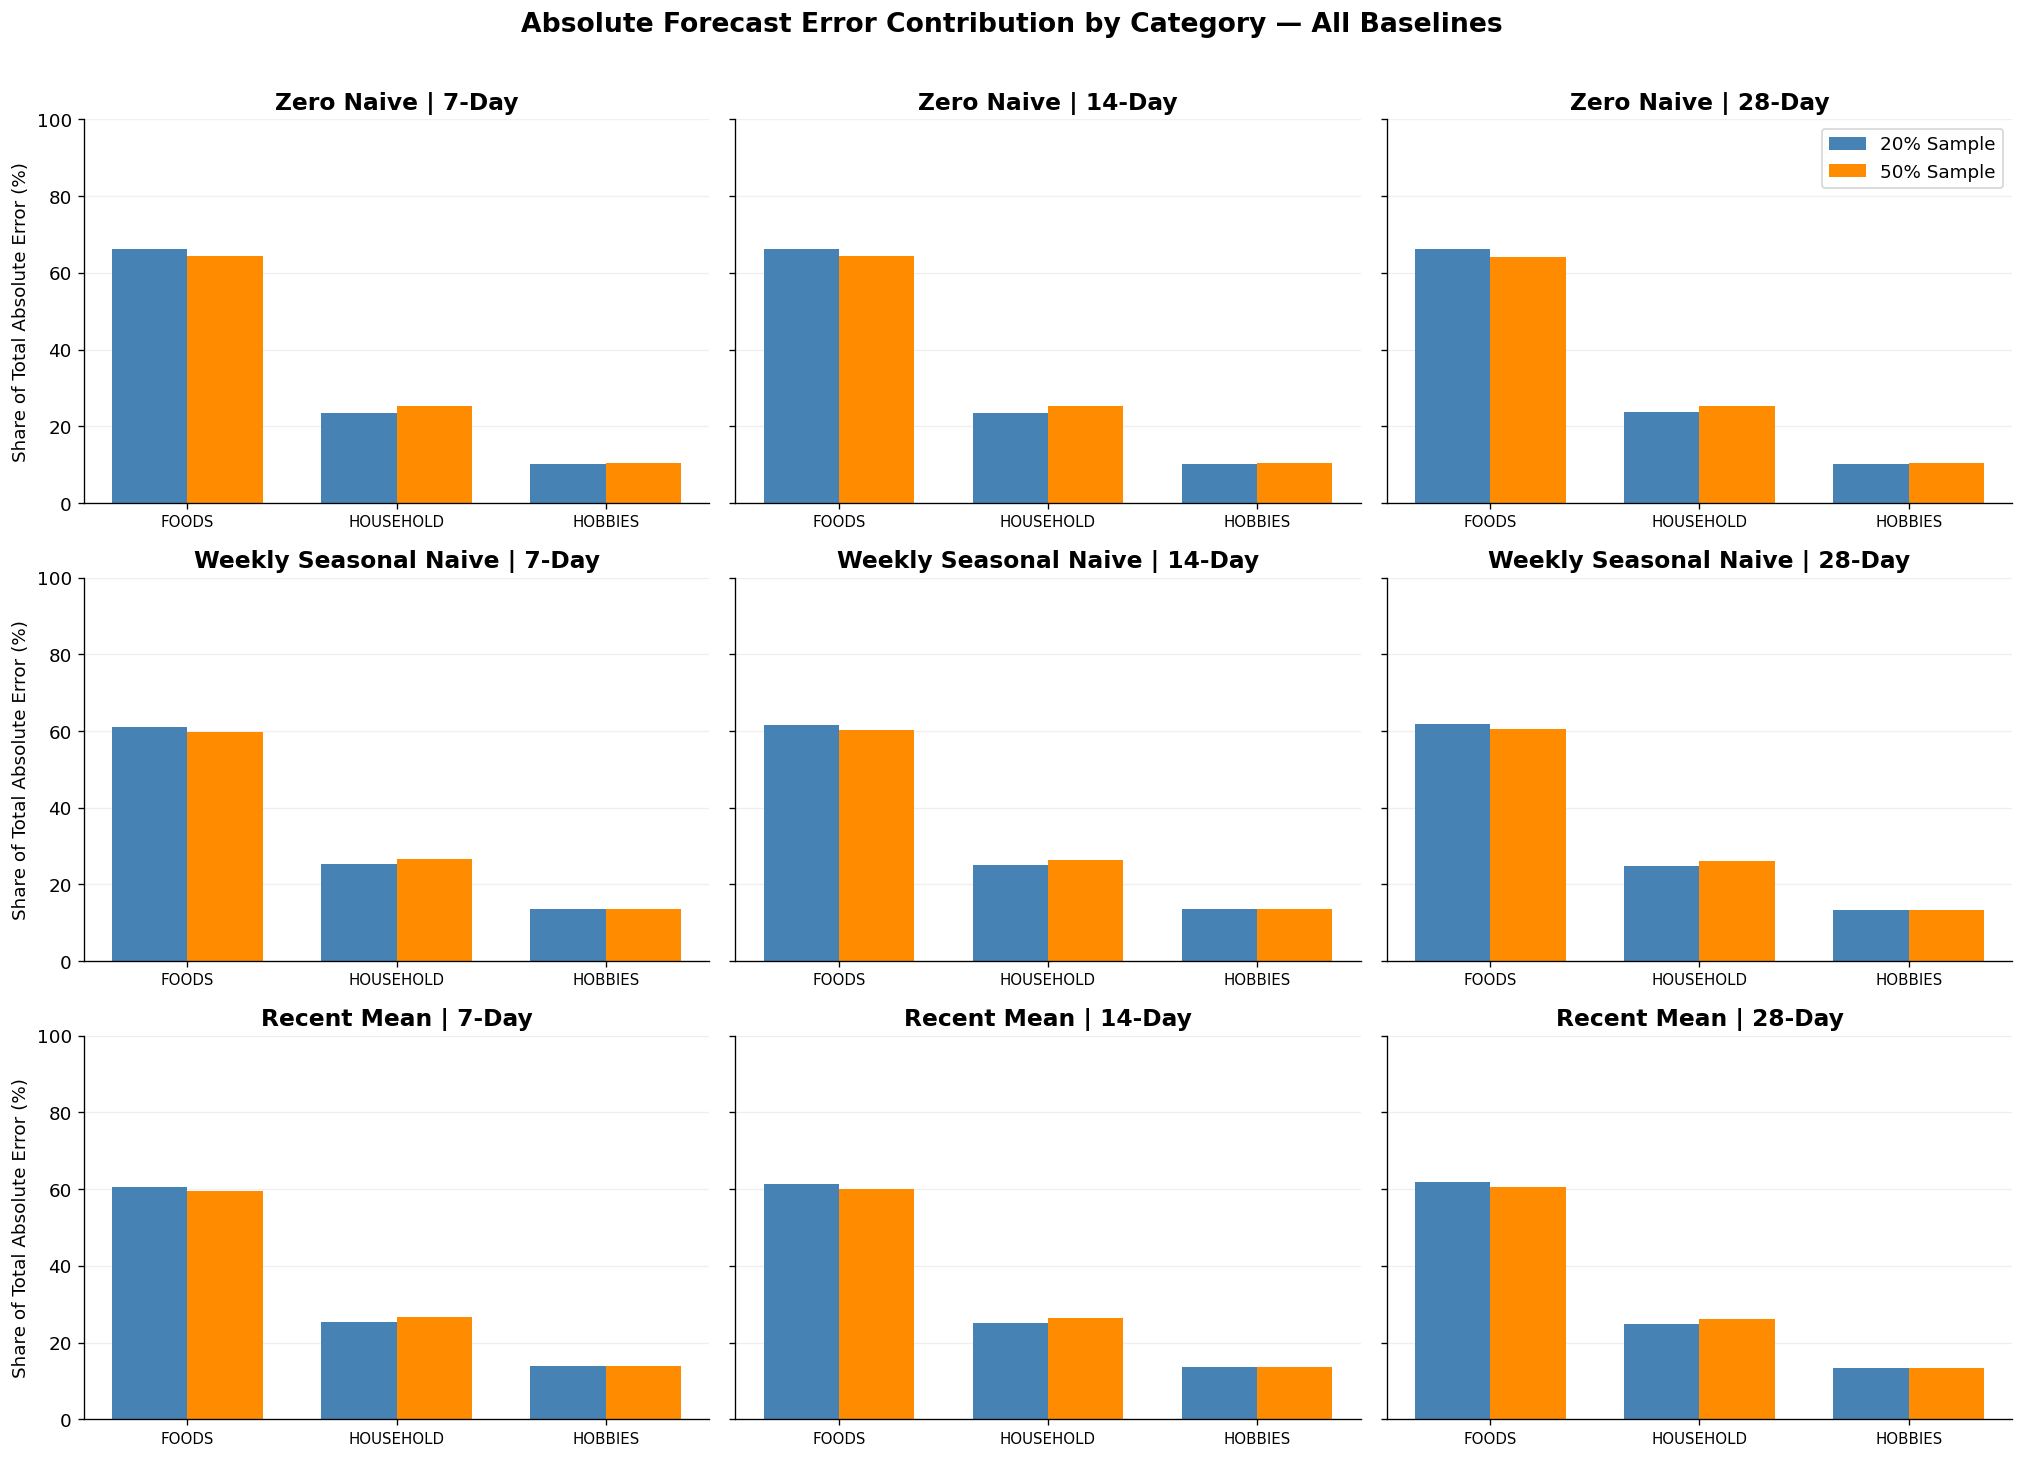

In [ ]:
# Figure 9 — Error Contribution Across All Models and Horizons

fig, axes = plt.subplots(3, 3, figsize=(17, 12), sharey=True)
models = ["zero_naive", "weekly_seasonal_naive", "recent_mean"]
categories = ["FOODS", "HOUSEHOLD", "HOBBIES"]
x, width = np.arange(len(categories)), 0.36

for i, model in enumerate(models):
    for j, horizon in enumerate(HORIZONS):
        ax = axes[i, j]
        for offset, (label, df, color) in enumerate([("20% Sample", category_contribution_20, "steelblue"), ("50% Sample", category_contribution_50, "darkorange")]):
            selected = df[(df["model"] == model) & (df["horizon"] == horizon)].set_index("cat_id").reindex(categories)
            ax.bar(x + (offset - 0.5) * width, selected["error_share_pct"], width, label=label, color=color)
        ax.set_title(f"{model.replace('_', ' ').title()} | {horizon}-Day", fontweight="bold")
        ax.set_xticks(x)
        ax.set_xticklabels(categories, fontsize=9)
        ax.set_ylim(0, 100)
        ax.set_ylabel("Share of Total Absolute Error (%)" if j == 0 else "")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        if i == 0 and j == 2: ax.legend()

fig.suptitle("Absolute Forecast Error Contribution by Category — All Baselines", fontsize=16, fontweight="bold", y=1.01)
fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure9_error_contribution_all_models_horizons.png", dpi=300, bbox_inches="tight")
plt.show()

### Interim Findings — Error Contribution Analysis

**Key Findings**

1. **FOODS contributed the largest share of total absolute forecasting error**, accounting for 60.67% in the 20% sample and 59.39% in the 50% sample, despite having the lowest category-level WAPE.

2. **HOBBIES exhibited the highest relative forecasting error**, with WAPE values of 104.74% and 104.71%, but contributed only 13.89% and 13.96% of total absolute error in the respective samples.

3. **HOUSEHOLD represented an intermediate category**, contributing 25.44% and 26.66% of total absolute error in the 20% and 50% samples, respectively.

4. **The error contribution ranking remained stable across both samples.** CA–FOODS was the largest individual State × Category contributor, accounting for 24.32% and 24.06% of total absolute error.

**Business Implications**

The findings highlight two distinct forecasting priorities:

- **Aggregate error reduction:** FOODS is a potential priority because it accounts for the majority of total absolute forecasting error.
- **Sparse-demand forecasting:** HOBBIES warrants further investigation because of its high relative forecasting error and frequent zero-sales days.

These priorities reflect forecasting performance rather than measured financial impact. Inventory costs, stockout information, and product values would be required to quantify operational or financial benefits.

**Robustness and Limitations**

The consistency between the nested 20% and 50% samples supports the stability of the descriptive findings. However, the results do not establish that improving forecasts for a particular category will necessarily generate the largest inventory cost savings.

#10.Forecast Bias Analysis (20% & 50% Samples)

In [ ]:
def analyze_forecast_bias(matrix):
    results = []
    train_length, n_days = len(train_days), matrix.shape[1]

    for horizon in [7, 14, 28]:
        for origin in range(train_length, n_days - horizon + 1, 7):
            history, actual = matrix[:, :origin], matrix[:, origin:origin + horizon]
            forecasts = generate_baselines(history, horizon=horizon)

            for model, forecast in forecasts.items():
                assert forecast.shape == actual.shape
                results.append({
                    "horizon": horizon, "model": model,
                    "sum_signed_error": (forecast - actual).sum(dtype=np.float64),
                    "sum_actual": actual.sum(dtype=np.float64), "n_obs": actual.size
                })

    backtest = pd.DataFrame(results)
    summary = backtest.groupby(["horizon", "model"], as_index=False).agg(
        sum_signed_error=("sum_signed_error", "sum"),
        sum_actual=("sum_actual", "sum"), n_observations=("n_obs", "sum")
    )

    summary["ME"] = summary["sum_signed_error"] / summary["n_observations"]
    summary["Bias_pct"] = np.where(summary["sum_actual"] > 0, 100 * summary["sum_signed_error"] / summary["sum_actual"], np.nan)
    summary["Direction"] = np.where(summary["ME"] > 0, "Overforecast", np.where(summary["ME"] < 0, "Underforecast", "Neutral"))

    assert len(summary) == 9
    assert backtest.groupby(["horizon", "model"]).size().tolist() == [52, 52, 52, 51, 51, 51, 49, 49, 49]
    return backtest, summary


bias_backtest_20, bias_summary_20 = analyze_forecast_bias(sample20_matrix)
bias_backtest_50, bias_summary_50 = analyze_forecast_bias(sample50_matrix)

print("20% Sample — Forecast Bias")
display(bias_summary_20[["horizon", "model", "ME", "Bias_pct", "Direction"]].round(2))

print("50% Sample — Forecast Bias")
display(bias_summary_50[["horizon", "model", "ME", "Bias_pct", "Direction"]].round(2))

20% Sample — Forecast Bias


,horizon,model,ME,Bias_pct,Direction
0,7,recent_mean,-0.00,-0.13,Underforecast
1,7,weekly_seasonal_naive,-0.00,-0.13,Underforecast
2,7,zero_naive,-1.27,-100.00,Underforecast
3,14,recent_mean,-0.01,-0.48,Underforecast
4,14,weekly_seasonal_naive,-0.01,-0.48,Underforecast
5,14,zero_naive,-1.27,-100.00,Underforecast
6,28,recent_mean,-0.01,-0.86,Underforecast
7,28,weekly_seasonal_naive,-0.01,-0.86,Underforecast
8,28,zero_naive,-1.28,-100.00,Underforecast


50% Sample — Forecast Bias


,horizon,model,ME,Bias_pct,Direction
0,7,recent_mean,-0.00,-0.11,Underforecast
1,7,weekly_seasonal_naive,-0.00,-0.11,Underforecast
2,7,zero_naive,-1.23,-100.00,Underforecast
3,14,recent_mean,-0.01,-0.46,Underforecast
4,14,weekly_seasonal_naive,-0.01,-0.46,Underforecast
5,14,zero_naive,-1.23,-100.00,Underforecast
6,28,recent_mean,-0.01,-0.83,Underforecast
7,28,weekly_seasonal_naive,-0.01,-0.83,Underforecast
8,28,zero_naive,-1.24,-100.00,Underforecast


In [ ]:
# Validate Forecast Bias Against Existing Group Error Analysis

def validate_forecast_bias(bias_summary, group_errors):
    actual_totals = group_errors.groupby(["horizon", "model"], as_index=False).agg(sum_actual=("sum_actual", "sum"))

    check = bias_summary.merge(actual_totals, on=["horizon", "model"],
                               suffixes=("_bias", "_evaluation"), validate="one_to_one")

    assert len(check) == 9
    assert np.allclose(check["sum_actual_bias"], check["sum_actual_evaluation"], rtol=1e-8, atol=1e-5)
    return check

bias_check_20 = validate_forecast_bias(bias_summary_20, group_error_20)
bias_check_50 = validate_forecast_bias(bias_summary_50, group_error_50)

print("20% Forecast Bias Validation: PASSED")
print("50% Forecast Bias Validation: PASSED")

20% Forecast Bias Validation: PASSED
50% Forecast Bias Validation: PASSED


,horizon,Bias_20,Bias_50,Bias_diff_pp
0,7,-0.128,-0.111,0.017
1,14,-0.483,-0.457,0.026
2,28,-0.856,-0.830,0.026


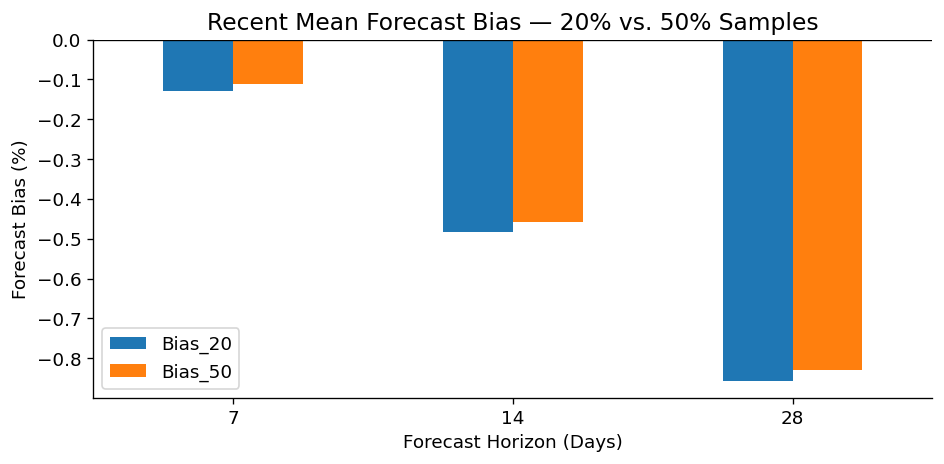

In [ ]:
# Compare Recent Mean Bias Across Samples

bias_20 = bias_summary_20.query("model == 'recent_mean'")[["horizon", "Bias_pct"]].rename(columns={"Bias_pct": "Bias_20"})
bias_50 = bias_summary_50.query("model == 'recent_mean'")[["horizon", "Bias_pct"]].rename(columns={"Bias_pct": "Bias_50"})

bias_comparison = bias_20.merge(bias_50, on="horizon", validate="one_to_one")
bias_comparison["Bias_diff_pp"] = bias_comparison["Bias_50"] - bias_comparison["Bias_20"]

display(bias_comparison.round(3))

ax = bias_comparison.set_index("horizon")[["Bias_20", "Bias_50"]].plot(kind="bar", figsize=(8, 4), rot=0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Recent Mean Forecast Bias — 20% vs. 50% Samples")
ax.set_xlabel("Forecast Horizon (Days)")
ax.set_ylabel("Forecast Bias (%)")
plt.tight_layout()
plt.savefig(Forecasting_OUTPUT / "forecast_bias_comparison_20_50.png", dpi=300, bbox_inches="tight")
plt.show()

### Interim Findings — Forecast Bias Analysis

**Key Findings**

1. **Recent Mean exhibited a small negative aggregate forecast bias across all horizons.** Bias values were -0.128%, -0.483%, and -0.856% for the 20% sample, compared with -0.111%, -0.457%, and -0.830% for the 50% sample at the 7-, 14-, and 28-day horizons, respectively.

2. **The direction and magnitude of forecast bias were consistent across both samples.** The maximum absolute difference was only 0.026 percentage points, supporting the descriptive robustness of the findings.

3. **Underforecasting became more pronounced at longer horizons.** However, the relatively small aggregate bias does not imply high forecasting accuracy, as substantial absolute forecasting errors remain.

**Business Implications**

Forecast evaluation should consider both absolute error metrics (MAE, RMSE, WAPE) and directional bias. Small aggregate bias may conceal offsetting overforecasts and underforecasts across individual products, stores, and categories.

Although underforecasting may increase potential inventory-planning risks, actual stockout exposure cannot be quantified without inventory availability and replenishment data.

**Next Step**

Examine forecast bias by State × Category to determine whether the small aggregate bias masks systematic differences across product groups and geographic regions.

In [ ]:
# State × Category Forecast Bias (20% & 50%)
def analyze_group_bias(matrix, metadata, horizon=7):
    results = []
    train_length, n_days = len(train_days), matrix.shape[1]

    for (state, category), group in metadata.groupby(["state_id", "cat_id"], observed=True):
        group_matrix = matrix[group.index.to_numpy()]
        signed_error, actual_total, n_obs = 0.0, 0.0, 0

        for origin in range(train_length, n_days - horizon + 1, 7):
            history = group_matrix[:, :origin]
            actual = group_matrix[:, origin:origin + horizon]
            forecast = generate_baselines(history, horizon=horizon)["recent_mean"]

            signed_error += (forecast - actual).sum(dtype=np.float64)
            actual_total += actual.sum(dtype=np.float64)
            n_obs += actual.size

        results.append({"state_id": state, "cat_id": category, "n_series": len(group),
                        "sum_signed_error": signed_error, "sum_actual": actual_total, "n_observations": n_obs})

    result = pd.DataFrame(results)
    result["Bias_pct"] = np.where(result["sum_actual"] > 0, 100 * result["sum_signed_error"] / result["sum_actual"], np.nan)
    result["Direction"] = np.where(result["Bias_pct"] > 0, "Overforecast", np.where(result["Bias_pct"] < 0, "Underforecast", "Neutral"))
    return result


group_bias_20 = analyze_group_bias(sample20_matrix, metadata_20)
group_bias_50 = analyze_group_bias(sample50_matrix, metadata_50)

assert len(group_bias_20) == len(group_bias_50) == 9

for group_bias, bias_summary in [(group_bias_20, bias_summary_20), (group_bias_50, bias_summary_50)]:
    expected = bias_summary.query("horizon == 7 and model == 'recent_mean'").iloc[0]
    assert np.isclose(group_bias["sum_signed_error"].sum(), expected["sum_signed_error"], atol=1e-3)
    assert np.isclose(group_bias["sum_actual"].sum(), expected["sum_actual"], atol=1e-3)

print("State × Category Bias Reconciliation: PASSED")

print("20% Sample")
display(group_bias_20[["state_id", "cat_id", "n_series", "Bias_pct", "Direction"]].round(3))

print("50% Sample")
display(group_bias_50[["state_id", "cat_id", "n_series", "Bias_pct", "Direction"]].round(3))

State × Category Bias Reconciliation: PASSED
20% Sample


,state_id,cat_id,n_series,Bias_pct,Direction
0,CA,FOODS,1150,-0.117,Underforecast
1,CA,HOBBIES,452,-0.528,Underforecast
2,CA,HOUSEHOLD,838,-0.167,Underforecast
3,TX,FOODS,862,0.007,Overforecast
4,TX,HOBBIES,339,0.018,Overforecast
5,TX,HOUSEHOLD,628,-0.337,Underforecast
6,WI,FOODS,862,-0.118,Underforecast
7,WI,HOBBIES,339,-0.019,Underforecast
8,WI,HOUSEHOLD,628,-0.097,Underforecast


50% Sample


,state_id,cat_id,n_series,Bias_pct,Direction
0,CA,FOODS,2874,-0.104,Underforecast
1,CA,HOBBIES,1130,-0.426,Underforecast
2,CA,HOUSEHOLD,2094,-0.182,Underforecast
3,TX,FOODS,2156,0.010,Overforecast
4,TX,HOBBIES,848,-0.105,Underforecast
5,TX,HOUSEHOLD,1571,-0.314,Underforecast
6,WI,FOODS,2155,-0.039,Underforecast
7,WI,HOBBIES,847,-0.096,Underforecast
8,WI,HOUSEHOLD,1570,-0.099,Underforecast


In [ ]:
#Compare State × Category Bias Across Samples

bias_group_20 = group_bias_20[["state_id", "cat_id", "Bias_pct"]].rename(columns={"Bias_pct": "Bias_20"})
bias_group_50 = group_bias_50[["state_id", "cat_id", "Bias_pct"]].rename(columns={"Bias_pct": "Bias_50"})

group_bias_comparison = bias_group_20.merge(bias_group_50, on=["state_id", "cat_id"], validate="one_to_one")
group_bias_comparison["Bias_diff_pp"] = group_bias_comparison["Bias_50"] - group_bias_comparison["Bias_20"]

assert len(group_bias_comparison) == 9

display(group_bias_comparison.sort_values(["state_id", "cat_id"]).round(3))
print("Maximum absolute group bias difference:", round(group_bias_comparison["Bias_diff_pp"].abs().max(), 3), "percentage points")

,state_id,cat_id,Bias_20,Bias_50,Bias_diff_pp
0,CA,FOODS,-0.117,-0.104,0.013
1,CA,HOBBIES,-0.528,-0.426,0.102
2,CA,HOUSEHOLD,-0.167,-0.182,-0.015
3,TX,FOODS,0.007,0.010,0.003
4,TX,HOBBIES,0.018,-0.105,-0.122
5,TX,HOUSEHOLD,-0.337,-0.314,0.023
6,WI,FOODS,-0.118,-0.039,0.079
7,WI,HOBBIES,-0.019,-0.096,-0.077
8,WI,HOUSEHOLD,-0.097,-0.099,-0.002


Maximum absolute group bias difference: 0.122 percentage points


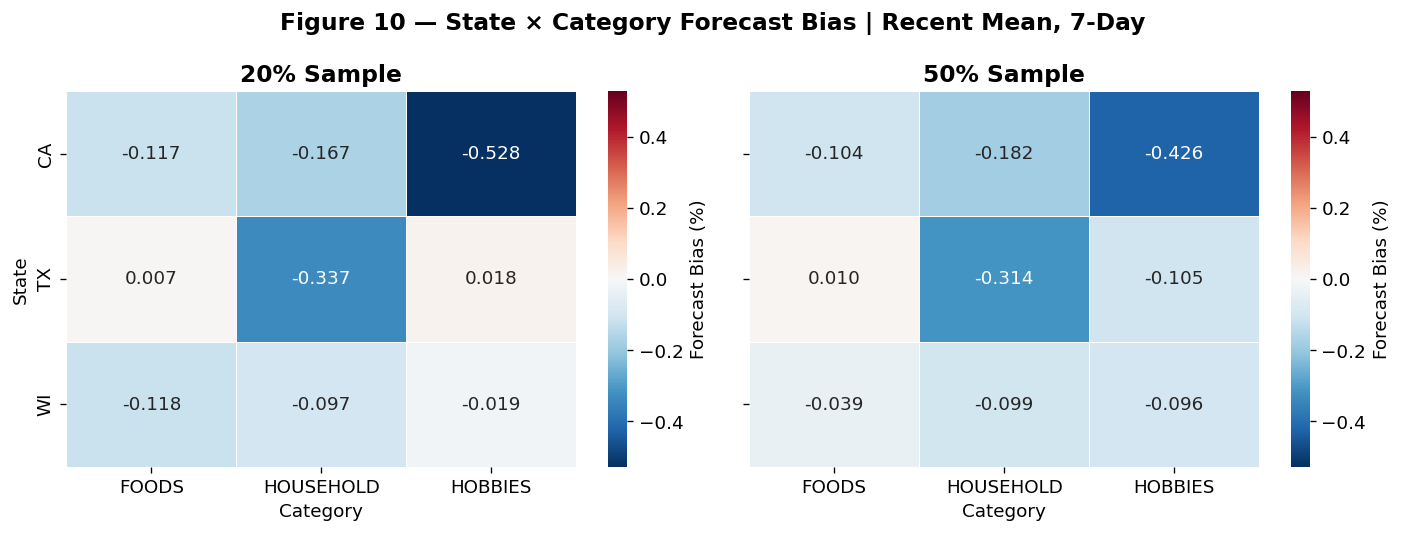

In [ ]:
# Figure 10 — State × Category Forecast Bias Heatmap (Recent Mean, 7-Day)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
samples = [("20% Sample", group_bias_20), ("50% Sample", group_bias_50)]
limit = max(df["Bias_pct"].abs().max() for _, df in samples)

for ax, (label, df) in zip(axes, samples):
    pivot = df.pivot(index="state_id", columns="cat_id", values="Bias_pct").reindex(index=["CA", "TX", "WI"], columns=["FOODS", "HOUSEHOLD", "HOBBIES"])
    sns.heatmap(pivot, ax=ax, annot=True, fmt=".3f", cmap="RdBu_r", center=0, vmin=-limit, vmax=limit, linewidths=0.5, linecolor="white", cbar=True, cbar_kws={"label": "Forecast Bias (%)"})
    ax.set_title(label, fontweight="bold")
    ax.set_xlabel("Category")
    ax.set_ylabel("State" if ax == axes[0] else "")

fig.suptitle("Figure 10 — State × Category Forecast Bias | Recent Mean, 7-Day", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure10_state_category_forecast_bias.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#Export Forecast Bias Results

bias_summary_20.to_csv(Forecasting_OUTPUT / "forecast_bias_summary_20.csv", index=False)
bias_summary_50.to_csv(Forecasting_OUTPUT / "forecast_bias_summary_50.csv", index=False)
bias_comparison.to_csv(Forecasting_OUTPUT / "forecast_bias_comparison_20_50.csv", index=False)

group_bias_20.to_csv(Forecasting_OUTPUT / "state_category_bias_20.csv", index=False)
group_bias_50.to_csv(Forecasting_OUTPUT / "state_category_bias_50.csv", index=False)
group_bias_comparison.to_csv(Forecasting_OUTPUT / "state_category_bias_comparison_20_50.csv", index=False)

print("Forecast Bias Analysis exported successfully.")

Forecast Bias Analysis exported successfully.


### Interim Findings — State × Category Forecast Bias

**Key Findings**

1. The Recent Mean baseline exhibited small directional bias at the State × Category level for the 7-day horizon, with most groups showing slight underforecasting across both samples.

2. CA–HOBBIES showed the largest negative bias, at -0.528% in the 20% sample and -0.426% in the 50% sample.

3. TX–FOODS exhibited marginal positive bias in both samples (+0.007% and +0.010%). TX–HOBBIES changed from slightly positive to slightly negative bias, although both values remained close to zero.

4. Overall, the direction and magnitude of group-level bias were broadly consistent across samples, with minor differences in near-zero estimates.The maximum absolute difference in group-level bias between the two samples was 0.122 percentage points (TX–HOBBIES), indicating limited sensitivity of the aggregated bias estimates to the sample expansion.

**Business Implications**

Small group-level aggregate bias does not guarantee accurate forecasts for individual item-store series. Positive and negative errors can offset one another, even when WAPE remains high.

Forecast accuracy, directional bias, and demand intermittency should therefore be evaluated together when identifying forecasting improvement opportunities. These results do not establish actual inventory shortages or excess stock.

**Next Step**

Investigate demand characteristics at the individual series level, including demand-volume quantiles and intermittent-demand categories, to determine whether forecasting difficulty varies systematically across demand patterns.

#11. Demand Segmentation Evaluation：Demand Quantile、Demand Type

In [ ]:
# Demand Quantile Classification (Training Data Only)
def classify_demand_quantiles(matrix, metadata):
    result = metadata[["id", "state_id", "cat_id", "store_id"]].copy().reset_index(drop=True)
    train_matrix = matrix[:, :len(train_days)]

    assert len(result) == train_matrix.shape[0]
    result["avg_daily_sales"] = train_matrix.mean(axis=1)
    result["zero_sales_rate"] = (train_matrix == 0).mean(axis=1)
    result["Demand_Quantile"] = pd.qcut(
        result["avg_daily_sales"].rank(method="first"),
        q=3, labels=["Low", "Medium", "High"]
    )

    assert result["Demand_Quantile"].notna().all()
    return result

demand_quantile_20 = classify_demand_quantiles(sample20_matrix, metadata_20)
demand_quantile_50 = classify_demand_quantiles(sample50_matrix, metadata_50)

print("20% Sample — Demand Quantiles")
display(demand_quantile_20.groupby("Demand_Quantile", observed=True).agg(
    n_series=("id", "size"),
    min_daily_sales=("avg_daily_sales", "min"),
    median_daily_sales=("avg_daily_sales", "median"),
    max_daily_sales=("avg_daily_sales", "max")
).round(3))

print("50% Sample — Demand Quantiles")
display(demand_quantile_50.groupby("Demand_Quantile", observed=True).agg(
    n_series=("id", "size"),
    min_daily_sales=("avg_daily_sales", "min"),
    median_daily_sales=("avg_daily_sales", "median"),
    max_daily_sales=("avg_daily_sales", "max")
).round(3))

assert len(demand_quantile_20) == 6098
assert len(demand_quantile_50) == 15245
assert set(demand_quantile_20["id"]).issubset(set(demand_quantile_50["id"]))

print("Demand Quantile Classification: PASSED")

20% Sample — Demand Quantiles


,n_series,min_daily_sales,median_daily_sales,max_daily_sales
Demand_Quantile,,,,
Low,2033,0.000,0.073,0.194000
Medium,2032,0.194,0.378,0.724000
High,2033,0.725,1.544,104.419998


50% Sample — Demand Quantiles


,n_series,min_daily_sales,median_daily_sales,max_daily_sales
Demand_Quantile,,,,
Low,5082,0.000,0.075,0.193000
Medium,5081,0.193,0.373,0.713000
High,5082,0.714,1.510,104.419998


Demand Quantile Classification: PASSED


In [ ]:
#Apply Common Demand Quantile Thresholds
q1, q2 = demand_quantile_50["avg_daily_sales"].quantile([1/3, 2/3])
def apply_common_quantiles(df):
    result = df.copy()
    result["Demand_Quantile"] = pd.cut(
        result["avg_daily_sales"],
        bins=[-np.inf, q1, q2, np.inf],
        labels=["Low", "Medium", "High"],
        include_lowest=True
    )
    return result

demand_quantile_20 = apply_common_quantiles(demand_quantile_20)
demand_quantile_50 = apply_common_quantiles(demand_quantile_50)

assert demand_quantile_20["Demand_Quantile"].notna().all()
assert demand_quantile_50["Demand_Quantile"].notna().all()

check = demand_quantile_20[["id", "Demand_Quantile"]].merge(
    demand_quantile_50[["id", "Demand_Quantile"]],
    on="id", suffixes=("_20", "_50"), validate="one_to_one"
)
assert (check["Demand_Quantile_20"] == check["Demand_Quantile_50"]).all()

print(f"Common thresholds: {q1:.4f}, {q2:.4f}")
print("Common Demand Quantile Classification: PASSED")
display(pd.DataFrame({
    "20% Sample": demand_quantile_20["Demand_Quantile"].value_counts().sort_index(),
    "50% Sample": demand_quantile_50["Demand_Quantile"].value_counts().sort_index()
}))

Common thresholds: 0.1926, 0.7137
Common Demand Quantile Classification: PASSED


,20% Sample,50% Sample
Demand_Quantile,,
Low,2025,5083
Medium,2013,5080
High,2060,5082


In [ ]:
#Demand Quantile vs. Forecast Error (20% & 50%)
def analyze_quantile_errors(matrix, quantile_df):
    results = []
    for demand_group, group in quantile_df.groupby("Demand_Quantile", observed=True):
        group_matrix = matrix[group.index.to_numpy()]
        bt = rolling_origin_backtest(
            sales_matrix=group_matrix, day_cols=train_val_days,
            train_length=len(train_days), horizons=(7,), step=STEP,
            recent_mean_window=RECENT_MEAN_WINDOW, season_length=SEASON_LENGTH
        )
        selected = bt.query("model == 'recent_mean'")
        results.append({
            "Demand_Quantile": demand_group, "n_series": len(group),
            "sum_abs_error": selected["sum_abs_error"].sum(),
            "sum_sq_error": selected["sum_sq_error"].sum(),
            "sum_actual": selected["sum_actual"].sum(),
            "n_observations": selected["n_obs"].sum()
        })

    result = pd.DataFrame(results)
    result["MAE"] = result["sum_abs_error"] / result["n_observations"]
    result["RMSE"] = np.sqrt(result["sum_sq_error"] / result["n_observations"])
    result["WAPE_pct"] = np.where(result["sum_actual"] > 0, 100 * result["sum_abs_error"] / result["sum_actual"], np.nan)
    result["error_share_pct"] = 100 * result["sum_abs_error"] / result["sum_abs_error"].sum()
    return result.sort_values("Demand_Quantile").reset_index(drop=True)


quantile_error_20 = analyze_quantile_errors(sample20_matrix, demand_quantile_20)
quantile_error_50 = analyze_quantile_errors(sample50_matrix, demand_quantile_50)

for result, group_errors in [(quantile_error_20, group_error_20), (quantile_error_50, group_error_50)]:
    overall = group_errors.query("horizon == 7 and model == 'recent_mean'")
    assert len(result) == 3
    assert np.isclose(result["sum_abs_error"].sum(), overall["sum_abs_error"].sum(), rtol=1e-8)
    assert np.isclose(result["sum_actual"].sum(), overall["sum_actual"].sum(), rtol=1e-8)

print("Demand Quantile Error Reconciliation: PASSED")
print("20% Sample")
display(quantile_error_20[["Demand_Quantile", "n_series", "MAE", "RMSE", "WAPE_pct", "error_share_pct"]].round(2))
print("50% Sample")
display(quantile_error_50[["Demand_Quantile", "n_series", "MAE", "RMSE", "WAPE_pct", "error_share_pct"]].round(2))

Demand Quantile Error Reconciliation: PASSED
20% Sample


,Demand_Quantile,n_series,MAE,RMSE,WAPE_pct,error_share_pct
0,High,2060,1.82,3.75,65.31,63.17
1,Low,2025,0.43,0.86,113.32,14.59
2,Medium,2013,0.66,1.08,105.12,22.24


50% Sample


,Demand_Quantile,n_series,MAE,RMSE,WAPE_pct,error_share_pct
0,High,5082,1.79,3.59,66.03,62.42
1,Low,5083,0.42,0.86,116.81,14.65
2,Medium,5080,0.66,1.09,104.56,22.94


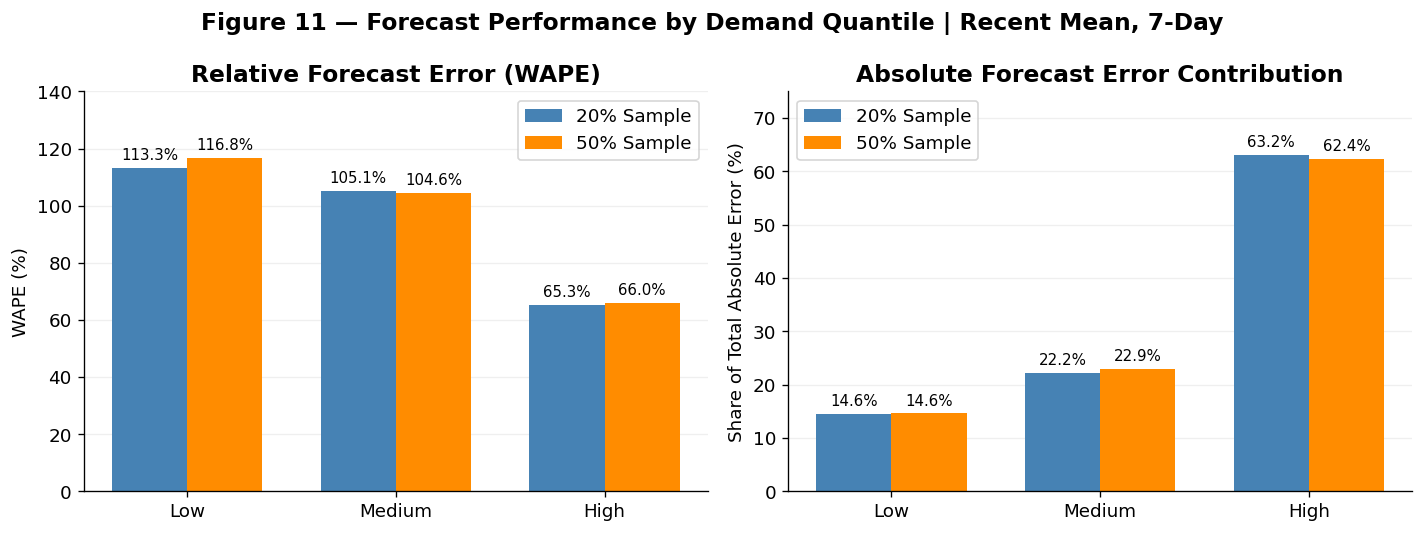

In [ ]:
# Figure 11 — Forecast Accuracy and Error Contribution by Demand Quantile

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
groups = ["Low", "Medium", "High"]
x, width = np.arange(len(groups)), 0.36

for ax, metric, title, ylabel in zip(axes, ["WAPE_pct", "error_share_pct"], ["Relative Forecast Error (WAPE)", "Absolute Forecast Error Contribution"], ["WAPE (%)", "Share of Total Absolute Error (%)"]):
    for offset, (label, df, color) in enumerate([("20% Sample", quantile_error_20, "steelblue"), ("50% Sample", quantile_error_50, "darkorange")]):
        values = df.set_index("Demand_Quantile").reindex(groups)[metric]
        bars = ax.bar(x + (offset - 0.5) * width, values, width, label=label, color=color)
        ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
    ax.set_title(title, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(groups)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 140 if metric == "WAPE_pct" else 75)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend()

fig.suptitle("Figure 11 — Forecast Performance by Demand Quantile | Recent Mean, 7-Day", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure11_demand_quantile_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

### Interim Findings — Demand Quantile Analysis

**Key Findings**

1. **Low-demand series exhibited the highest relative forecasting errors.** WAPE was 113.32% in the 20% sample and 116.81% in the 50% sample, indicating substantial forecasting difficulty relative to observed sales volume.

2. **High-demand series contributed the largest share of total absolute forecasting error.** Despite achieving the lowest WAPE (65.31% and 66.03%), these series accounted for 63.17% and 62.42% of total absolute error in the respective samples.

3. **Medium-demand series showed intermediate error contributions**, accounting for 22.24% and 22.94% of total absolute error, with WAPE exceeding 100% in both samples.

4. **The findings were directionally consistent across the nested 20% and 50% samples.** Both samples exhibited the same ranking in relative forecasting error and absolute error contribution.

**Business Implications**

The analysis identifies two complementary priorities:

- **Improving relative forecasting accuracy:** Low-demand series warrant further investigation because their WAPE exceeds 100%.
- **Reducing total absolute forecasting error:** High-demand series may offer greater opportunities for reducing aggregate forecasting error because they contribute more than 62% of it.

These results concern forecast accuracy and error volume, not measured inventory costs or financial losses.

**Next Step**

Classify individual item-store series by demand intermittency and variability using training-period data to determine whether different demand patterns explain the observed forecasting differences.

In [ ]:
#Demand Type Classification (Training Data Only)
import numpy as np
import pandas as pd
ADI_CUT, CV2_CUT = 1.32, 0.49
def classify_demand_types(train_matrix, metadata):
    x = np.asarray(train_matrix, dtype=np.float64)
    n_series, n_days = x.shape
    positive = x > 0
    n_sales_days = positive.sum(axis=1)
    has_sales = n_sales_days > 0
    first_sale = np.where(has_sales, positive.argmax(axis=1), n_days)
    adi = np.full(n_series, np.nan)
    adi[has_sales] = (n_days - first_sale[has_sales]) / n_sales_days[has_sales]
    mean = np.divide(x.sum(axis=1), n_sales_days, out=np.zeros(n_series), where=has_sales)
    var = np.maximum(np.divide((x ** 2).sum(axis=1), n_sales_days, out=np.zeros(n_series), where=has_sales) - mean ** 2, 0)
    cv2 = np.divide(var, mean ** 2, out=np.full(n_series, np.nan), where=mean > 0)
    demand_type = np.select([~has_sales, (adi < ADI_CUT) & (cv2 < CV2_CUT), (adi < ADI_CUT) & (cv2 >= CV2_CUT), (adi >= ADI_CUT) & (cv2 < CV2_CUT)], ["No sales", "Smooth", "Erratic", "Intermittent"], default="Lumpy")
    result = metadata.copy().reset_index(drop=True)
    result["ADI"], result["CV2"], result["Demand_Type"] = adi, cv2, demand_type
    return result

demand_type_20 = classify_demand_types(sample20_matrix[:, :len(train_days)], metadata_20)
demand_type_50 = classify_demand_types(sample50_matrix[:, :len(train_days)], metadata_50)

assert len(demand_type_20) == 6098 and len(demand_type_50) == 15245
assert demand_type_20["id"].tolist() == metadata_20["id"].tolist()
assert demand_type_50["id"].tolist() == metadata_50["id"].tolist()

print("Demand Type Classification: PASSED")
for label, df in [("20%", demand_type_20), ("50%", demand_type_50)]:
    print(f"\n{label} Sample")
    display(df["Demand_Type"].value_counts(normalize=True).mul(100).round(2).rename("Series Share (%)").to_frame())

Demand Type Classification: PASSED

20% Sample


,Series Share (%)
Demand_Type,
Intermittent,70.25
Lumpy,16.83
Smooth,6.81
No sales,3.23
Erratic,2.89



50% Sample


,Series Share (%)
Demand_Type,
Intermittent,70.32
Lumpy,16.96
Smooth,6.70
No sales,3.23
Erratic,2.79


In [ ]:
#Forecast Error by Demand Type (20% vs. 50%)
def evaluate_demand_types(matrix, metadata):
    results = []
    for dtype, group in metadata.groupby("Demand_Type", observed=True):
        group_matrix = matrix[group.index.to_numpy()]
        bt = rolling_origin_backtest(group_matrix, [f"d_{i+1}" for i in range(matrix.shape[1])], len(train_days), horizons=(7,), step=7)
        row = bt.query("model == 'recent_mean' and horizon == 7")
        sae, sse, actual = row["sum_abs_error"].sum(), row["sum_sq_error"].sum(), row["sum_actual"].sum()
        obs_col = "n_obs" if "n_obs" in row.columns else "n_observations"
        n_obs = row[obs_col].sum()
        results.append({"Demand_Type": dtype, "n_series": len(group), "sum_abs_error": sae, "sum_sq_error": sse, "sum_actual": actual, "n_observations": n_obs})
    df = pd.DataFrame(results)
    df["MAE"] = df["sum_abs_error"] / df["n_observations"]
    df["RMSE"] = np.sqrt(df["sum_sq_error"] / df["n_observations"])
    df["WAPE_pct"] = np.where(df["sum_actual"] > 0, 100 * df["sum_abs_error"] / df["sum_actual"], np.nan)
    df["error_share_pct"] = 100 * df["sum_abs_error"] / df["sum_abs_error"].sum()
    return df.sort_values("error_share_pct", ascending=False).reset_index(drop=True)

demand_error_20 = evaluate_demand_types(sample20_matrix, demand_type_20)
demand_error_50 = evaluate_demand_types(sample50_matrix, demand_type_50)

for label, df, evaluation in [("20%", demand_error_20, evaluation_20), ("50%", demand_error_50, evaluation_50)]:
    print(f"\n{label} Sample — Forecast Error by Demand Type")
    display(df[["Demand_Type", "n_series", "MAE", "RMSE", "WAPE_pct", "error_share_pct"]].round(2))
    assert np.isclose(df["error_share_pct"].sum(), 100)
    assert df["n_series"].sum() == (6098 if label == "20%" else 15245)
    overall = evaluation.query("model == 'recent_mean' and horizon == 7").iloc[0]
    pooled_wape = 100 * df["sum_abs_error"].sum() / df["sum_actual"].sum()
    assert np.isclose(pooled_wape, overall["WAPE_pct"], atol=1e-3)
    print(f"{label} Sample — WAPE Reconciliation: PASSED")

print("\nDemand Type Forecast Evaluation: PASSED")


20% Sample — Forecast Error by Demand Type


,Demand_Type,n_series,MAE,RMSE,WAPE_pct,error_share_pct
0,Intermittent,4284,0.64,1.30,94.63,45.98
1,Lumpy,1026,1.48,3.36,86.85,25.58
2,Smooth,415,2.42,4.27,48.83,16.96
3,Erratic,176,3.17,5.91,60.21,9.41
4,No sales,197,0.62,1.28,87.89,2.07


20% Sample — WAPE Reconciliation: PASSED

50% Sample — Forecast Error by Demand Type


,Demand_Type,n_series,MAE,RMSE,WAPE_pct,error_share_pct
0,Intermittent,10720,0.63,1.29,94.91,46.79
1,Lumpy,2585,1.41,3.18,88.14,25.10
2,Smooth,1021,2.44,4.20,49.67,17.14
3,Erratic,426,3.10,5.44,61.57,9.06
4,No sales,493,0.56,1.17,95.41,1.91


50% Sample — WAPE Reconciliation: PASSED

Demand Type Forecast Evaluation: PASSED


,Demand_Type,WAPE_20,Error_Share_20,WAPE_50,Error_Share_50,WAPE_diff_pp,Error_Share_diff_pp
0,Intermittent,94.63,45.98,94.91,46.79,0.28,0.81
1,Lumpy,86.85,25.58,88.14,25.10,1.29,-0.48
2,Smooth,48.83,16.96,49.67,17.14,0.84,0.18
3,Erratic,60.21,9.41,61.57,9.06,1.36,-0.35
4,No sales,87.89,2.07,95.41,1.91,7.51,-0.15


Demand Type Robustness Check: PASSED


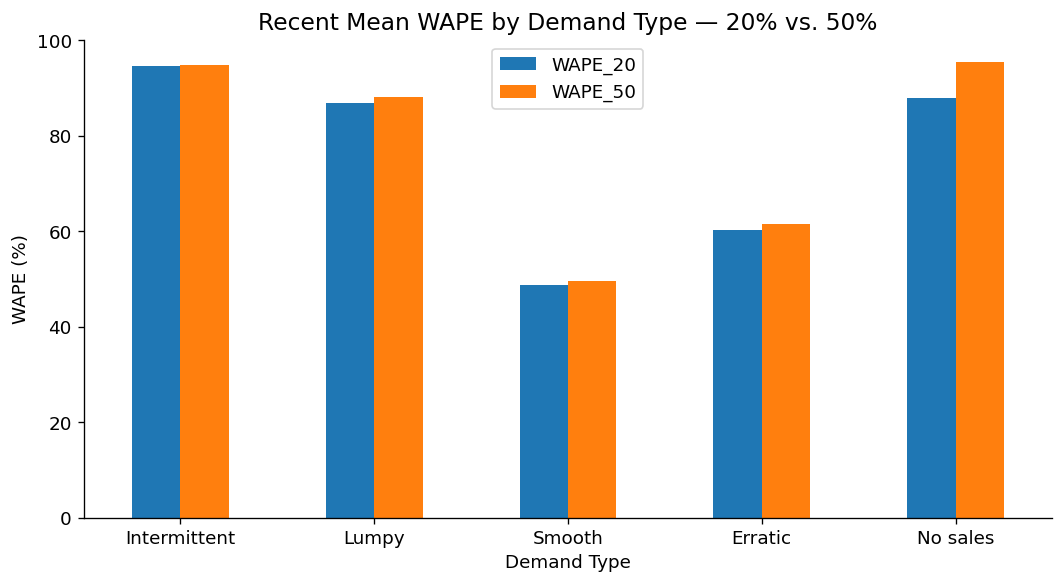

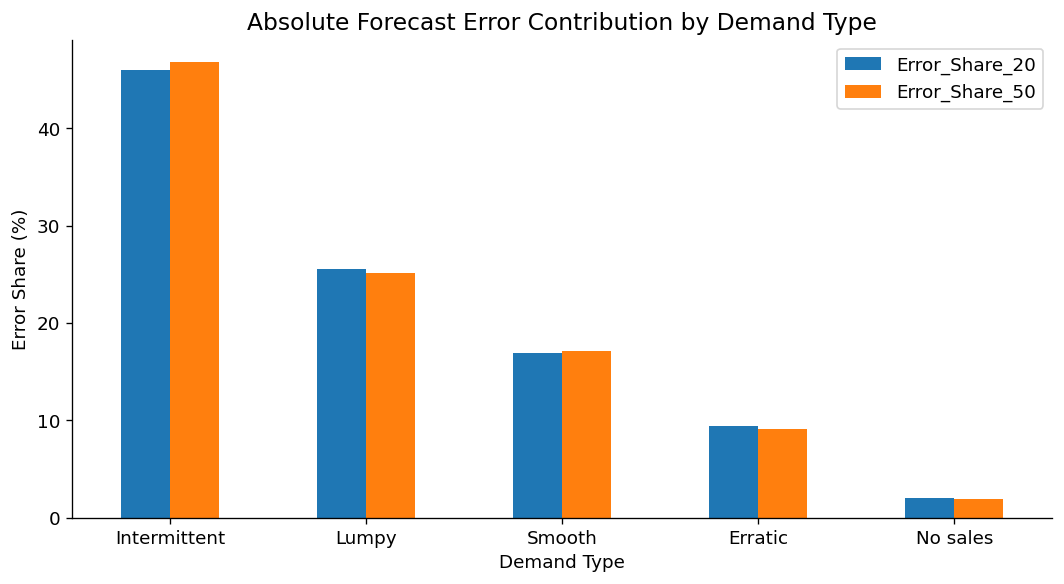

Demand Type Evaluation Results: EXPORTED


In [ ]:
# Demand Type Robustness Check (20% vs. 50%)
cols = ["Demand_Type", "WAPE_pct", "error_share_pct"]
compare_20 = demand_error_20[cols].rename(columns={"WAPE_pct":"WAPE_20", "error_share_pct":"Error_Share_20"})
compare_50 = demand_error_50[cols].rename(columns={"WAPE_pct":"WAPE_50", "error_share_pct":"Error_Share_50"})
demand_type_comparison = compare_20.merge(compare_50, on="Demand_Type", validate="one_to_one")
demand_type_comparison["WAPE_diff_pp"] = demand_type_comparison["WAPE_50"] - demand_type_comparison["WAPE_20"]
demand_type_comparison["Error_Share_diff_pp"] = demand_type_comparison["Error_Share_50"] - demand_type_comparison["Error_Share_20"]

display(demand_type_comparison.round(2))
assert len(demand_type_comparison) == 5
assert np.isclose(demand_type_comparison["Error_Share_diff_pp"].sum(), 0, atol=1e-6)
print("Demand Type Robustness Check: PASSED")

ax = demand_type_comparison.set_index("Demand_Type")[["WAPE_20", "WAPE_50"]].plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Recent Mean WAPE by Demand Type — 20% vs. 50%")
ax.set_xlabel("Demand Type")
ax.set_ylabel("WAPE (%)")
plt.tight_layout()
plt.savefig(Forecasting_OUTPUT / "demand_type_wape_comparison_20_50.png", dpi=300, bbox_inches="tight")
plt.show()

ax = demand_type_comparison.set_index("Demand_Type")[["Error_Share_20", "Error_Share_50"]].plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Absolute Forecast Error Contribution by Demand Type")
ax.set_xlabel("Demand Type")
ax.set_ylabel("Error Share (%)")
plt.tight_layout()
plt.savefig(Forecasting_OUTPUT / "demand_type_error_share_20_50.png", dpi=300, bbox_inches="tight")
plt.show()

demand_error_20.to_csv(Forecasting_OUTPUT / "demand_type_evaluation_20.csv", index=False)
demand_error_50.to_csv(Forecasting_OUTPUT / "demand_type_evaluation_50.csv", index=False)
demand_type_comparison.to_csv(Forecasting_OUTPUT / "demand_type_comparison_20_50.csv", index=False)
print("Demand Type Evaluation Results: EXPORTED")

### Interim Findings — Forecast Performance by Demand Type

**Objective:** Evaluate whether forecast accuracy and absolute error contribution differ across demand types, using the 7-day Recent Mean baseline and rolling-origin validation.

**Key Findings**

1. **Intermittent demand is the largest contributor to forecasting error.** It accounts for 45.98% of total absolute error in the 20% sample and 46.79% in the 50% sample, with WAPE values of 94.63% and 94.91%, respectively.

2. **Intermittent and Lumpy demand together account for most forecasting errors.** Their combined absolute error contributions are 71.56% (20%) and 71.89% (50%), suggesting that these demand patterns are important targets for future model improvements.

3. **Smooth demand is the most accurately forecasted segment.** Its WAPE is 48.83% in the 20% sample and 49.67% in the 50% sample, substantially lower than the other demand types.

4. **The major findings are consistent across sample sizes.** WAPE differences between the 20% and 50% samples are within 1.36 percentage points for Intermittent, Lumpy, Smooth, and Erratic demand. The No-sales group shows a larger difference of 7.51 percentage points.

**Business Implications**

- Prioritize evaluating alternative forecasting methods for Intermittent and Lumpy demand.
- Use demand-type segmentation to identify where the current baseline performs poorly and where the largest absolute errors occur.
- Maintain separate accuracy and error-contribution metrics when prioritizing forecasting improvements.

**Limitations:** Demand types are classified using training data only. The results are descriptive, based on nested samples and a 7-day Recent Mean baseline; they do not establish causal relationships or demonstrate that alternative models would improve accuracy. Forecast errors cannot be directly translated into stockouts, inventory costs, or service-level outcomes without additional operational data.


20% SAMPLE — RECONCILIATION PASSED


,Demand_Type,n_series,Bias_pct,WAPE_pct
0,Erratic,176,-0.208,60.210
1,Intermittent,4284,-0.188,94.632
2,Lumpy,1026,-0.159,86.847
3,No sales,197,-2.365,87.894
4,Smooth,415,0.168,48.834



50% SAMPLE — RECONCILIATION PASSED


,Demand_Type,n_series,Bias_pct,WAPE_pct
0,Erratic,426,-0.201,61.571
1,Intermittent,10720,-0.163,94.913
2,Lumpy,2585,-0.127,88.140
3,No sales,493,-2.401,95.406
4,Smooth,1021,0.147,49.673


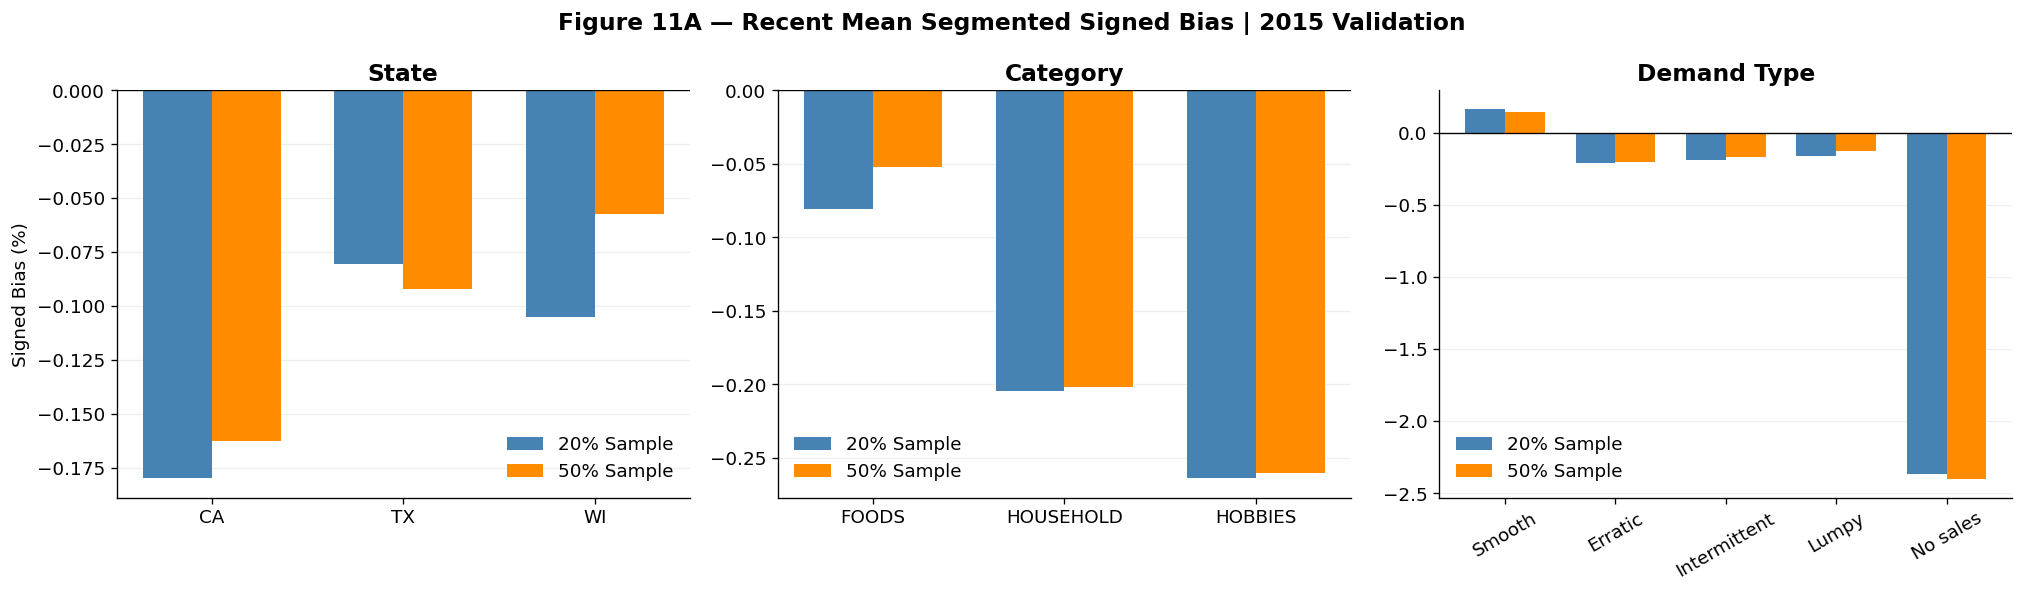


20% — TOP 10 UNDERFORECASTED SERIES


,id,actual_units,signed_error,Bias_pct,WAPE_pct
2591,FOODS_3_681_WI_3_evaluation,9588.0,-403.0,-4.20,44.28
3370,HOBBIES_1_254_CA_3_evaluation,3780.0,-113.0,-2.99,82.26
2248,FOODS_3_499_CA_2_evaluation,4007.0,-112.0,-2.80,48.61
4663,HOUSEHOLD_1_339_TX_2_evaluation,2518.0,-106.0,-4.21,55.43
3072,HOBBIES_1_103_CA_3_evaluation,2244.0,-100.0,-4.46,92.36
4819,HOUSEHOLD_1_418_TX_2_evaluation,1971.0,-96.0,-4.87,69.59
1921,FOODS_3_329_CA_2_evaluation,1447.0,-92.0,-6.36,107.30
1812,FOODS_3_282_TX_3_evaluation,3384.0,-90.0,-2.66,50.62
1113,FOODS_2_347_CA_2_evaluation,1401.0,-85.0,-6.07,67.61
4540,HOUSEHOLD_1_277_TX_2_evaluation,2264.0,-85.0,-3.75,52.67


20% — TOP 10 OVERFORECASTED SERIES


,id,actual_units,signed_error,Bias_pct,WAPE_pct
2462,FOODS_3_607_CA_3_evaluation,9946.0,119.0,1.20,41.55
183,FOODS_1_082_WI_2_evaluation,3751.0,99.0,2.64,55.28
1352,FOODS_3_069_TX_3_evaluation,573.0,99.0,17.28,124.83
2135,FOODS_3_444_CA_1_evaluation,2728.0,94.0,3.45,49.17
2721,FOODS_3_752_CA_3_evaluation,6877.0,85.0,1.24,73.62
1989,FOODS_3_362_TX_2_evaluation,4026.0,76.0,1.89,39.86
4354,HOUSEHOLD_1_179_CA_3_evaluation,5764.0,71.0,1.23,39.31
2414,FOODS_3_580_WI_3_evaluation,2583.0,60.0,2.32,83.08
4355,HOUSEHOLD_1_179_TX_1_evaluation,3509.0,59.0,1.68,56.74
4640,HOUSEHOLD_1_327_CA_3_evaluation,5051.0,59.0,1.17,47.17



50% — TOP 10 UNDERFORECASTED SERIES


,id,actual_units,signed_error,Bias_pct,WAPE_pct
6487,FOODS_3_681_WI_3_evaluation,9588.0,-403.0,-4.20,44.28
12170,HOUSEHOLD_1_447_TX_2_evaluation,3655.0,-167.0,-4.57,37.65
1359,FOODS_2_050_TX_2_evaluation,1405.0,-148.0,-10.53,103.49
3494,FOODS_3_086_TX_3_evaluation,3729.0,-131.0,-3.51,58.92
7944,HOBBIES_1_158_TX_3_evaluation,5848.0,-128.0,-2.19,33.60
8432,HOBBIES_1_254_CA_3_evaluation,3780.0,-113.0,-2.99,82.26
5577,FOODS_3_499_CA_2_evaluation,4007.0,-112.0,-2.80,48.61
12224,HOUSEHOLD_1_459_TX_2_evaluation,3045.0,-108.0,-3.55,49.20
11668,HOUSEHOLD_1_339_TX_2_evaluation,2518.0,-106.0,-4.21,55.43
3491,FOODS_3_086_CA_3_evaluation,5373.0,-102.0,-1.90,49.07


50% — TOP 10 OVERFORECASTED SERIES


,id,actual_units,signed_error,Bias_pct,WAPE_pct
4486,FOODS_3_282_CA_3_evaluation,11634.0,355.0,3.05,38.83
5575,FOODS_3_498_WI_2_evaluation,7340.0,202.0,2.75,98.84
3410,FOODS_3_069_CA_3_evaluation,607.0,177.0,29.16,142.69
3560,FOODS_3_099_TX_2_evaluation,5404.0,159.0,2.94,31.69
5300,FOODS_3_444_TX_2_evaluation,3943.0,122.0,3.09,50.02
272,FOODS_1_055_CA_3_evaluation,1635.0,120.0,7.34,64.38
6123,FOODS_3_607_CA_3_evaluation,9946.0,119.0,1.20,41.55
4899,FOODS_3_362_CA_3_evaluation,7192.0,108.0,1.50,40.65
431,FOODS_1_082_WI_2_evaluation,3751.0,99.0,2.64,55.28
3411,FOODS_3_069_TX_3_evaluation,573.0,99.0,17.28,124.83


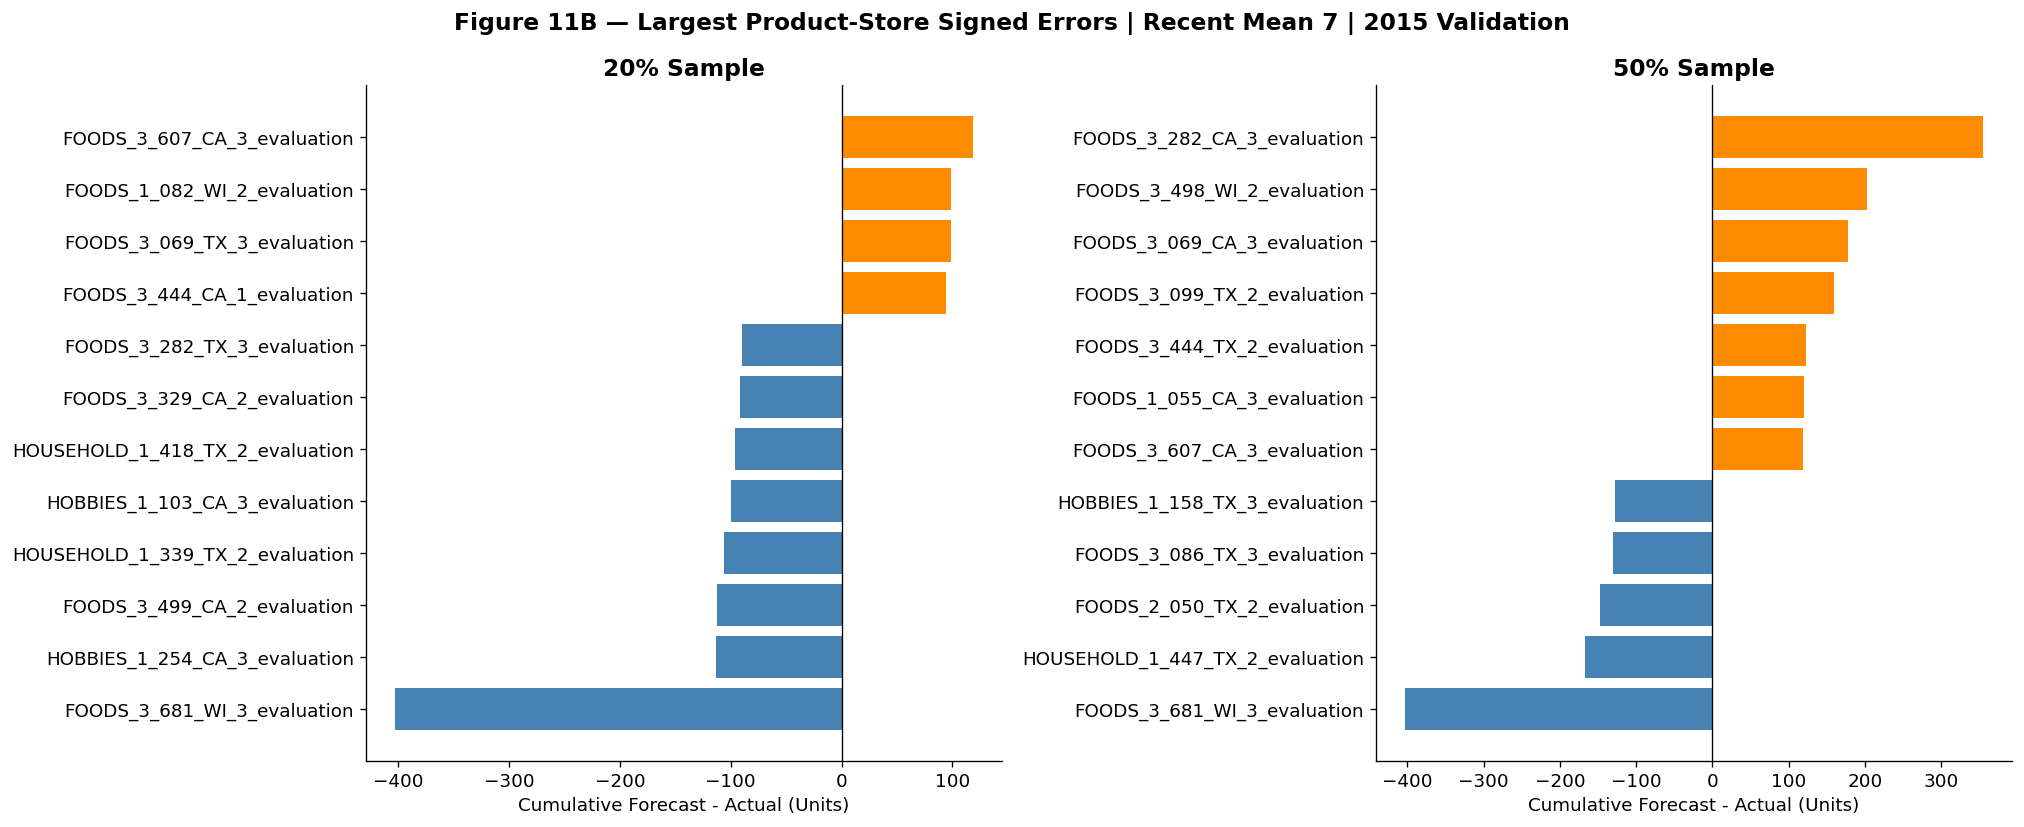


SIGNED BIAS ANALYSIS: PASSED | 2 figures and 10 CSV files exported
Original Forecasting matrices, time splits remain unchanged.


In [ ]:

# 11A — Recent Mean Segmented Signed Bias Analysis
# Objective: Evaluate Signed Bias by State, Category, Demand Type, Item, and Product-Store.
# Scope: 2015 Validation | 20% and 50% Samples | Recent Mean 7 | 7-Day Horizon.

def run_bias_diagnostics():
    import numpy as np, pandas as pd, matplotlib.pyplot as plt
    from pathlib import Path

    # STEP 1 — Reuse existing samples, metadata, and demand-type classifications.
    # Goal: Preserve the original dataset, chronological split, and forecasting methodology.
    samples = [("20%",sample20_matrix,metadata_20,demand_type_20,group_bias_20,bias_summary_20),("50%",sample50_matrix,metadata_50,demand_type_50,group_bias_50,bias_summary_50)]
    results = {}; output = Path(Forecasting_OUTPUT); output.mkdir(parents=True,exist_ok=True)

    for label,matrix,metadata,types,reference,overall_ref in samples:
        meta = metadata.copy().reset_index(drop=True)
        assert meta["id"].tolist()==types["id"].tolist(), f"{label}: Demand Type alignment failed"
        assert matrix.shape==(len(meta),len(train_val_days)), f"{label}: Matrix alignment failed"
        meta["Demand_Type"] = types["Demand_Type"].to_numpy()
        meta["item_id"] = meta["id"].str.replace(r"_(CA|TX|WI)_\d+_(evaluation|validation)$","",regex=True)
        assert (meta["item_id"]!=meta["id"]).all(), f"{label}: Item ID extraction failed"

        # STEP 2 — Calculate Recent Mean forecasts and per-series errors.
        # Goal: Accumulate actual sales, signed errors, and absolute errors across 2015 rolling origins.
        actual_sum = np.zeros(len(meta),dtype=np.float64)
        signed_sum = np.zeros(len(meta),dtype=np.float64)
        absolute_sum = np.zeros(len(meta),dtype=np.float64)

        for origin in range(len(train_days),matrix.shape[1]-7+1,7):
            actual = matrix[:,origin:origin+7].astype(np.float64)
            forecast = generate_baselines(matrix[:,:origin],horizon=7)["recent_mean"].astype(np.float64)
            error = forecast-actual
            actual_sum += actual.sum(axis=1)
            signed_sum += error.sum(axis=1)
            absolute_sum += np.abs(error).sum(axis=1)

        detail = meta.copy()
        detail["actual_units"] = actual_sum; detail["signed_error"] = signed_sum; detail["absolute_error"] = absolute_sum

        # STEP 3 — Aggregate volume-weighted Signed Bias and WAPE.
        # Goal: Measure segment-level errors without averaging individual percentage errors.
        def summarize(columns):
            g = detail.groupby(columns,as_index=False,observed=True).agg(n_series=("id","nunique"),actual_units=("actual_units","sum"),signed_error=("signed_error","sum"),absolute_error=("absolute_error","sum"))
            g["Bias_pct"] = np.where(g["actual_units"]>0,100*g["signed_error"]/g["actual_units"],np.nan)
            g["WAPE_pct"] = np.where(g["actual_units"]>0,100*g["absolute_error"]/g["actual_units"],np.nan)
            return g

        state = summarize(["state_id"]); category = summarize(["cat_id"])
        demand_type = summarize(["Demand_Type"]); item = summarize(["item_id","cat_id"])
        product_store = summarize(["id","item_id","store_id","state_id","cat_id"])

        # STEP 4 — Reconcile results with original Figure 10 and Baseline Bias tables.
        # Goal: Confirm identical evaluation periods, model definitions, and sample alignment.
        check = summarize(["state_id","cat_id"]).merge(reference[["state_id","cat_id","sum_signed_error","sum_actual"]],on=["state_id","cat_id"],validate="one_to_one")
        assert len(check)==9, f"{label}: Missing State-Category groups"
        assert np.allclose(check["signed_error"],check["sum_signed_error"],atol=0.01), f"{label}: Signed error mismatch"
        assert np.allclose(check["actual_units"],check["sum_actual"],atol=0.01), f"{label}: Actual sales mismatch"
        expected = overall_ref.query("model=='recent_mean' and horizon==7").iloc[0]
        assert np.isclose(signed_sum.sum(),expected["sum_signed_error"],atol=0.01), f"{label}: Overall bias mismatch"
        assert np.isclose(actual_sum.sum(),expected["sum_actual"],atol=0.01), f"{label}: Overall actual sales mismatch"

        results[label] = {"state":state,"category":category,"demand_type":demand_type,"item":item,"product_store":product_store}
        print(f"\n{label} SAMPLE — RECONCILIATION PASSED")
        display(demand_type[["Demand_Type","n_series","Bias_pct","WAPE_pct"]].round(3))

    # STEP 5 — Figure 11A: Compare Signed Bias across State, Category, and Demand Type.
    # Goal: Show systematic overforecasting and underforecasting in both samples.
    fig,axes = plt.subplots(1,3,figsize=(17,5))
    configs = [("state","state_id","State",["CA","TX","WI"]),("category","cat_id","Category",["FOODS","HOUSEHOLD","HOBBIES"]),("demand_type","Demand_Type","Demand Type",["Smooth","Erratic","Intermittent","Lumpy","No sales"])]

    for ax,(key,col,title,order) in zip(axes,configs):
        a = results["20%"][key].set_index(col)["Bias_pct"]
        b = results["50%"][key].set_index(col)["Bias_pct"]
        labels = [v for v in order if v in a.index or v in b.index]; x = np.arange(len(labels))
        ax.bar(x-0.18,a.reindex(labels).to_numpy(),0.36,label="20% Sample",color="steelblue")
        ax.bar(x+0.18,b.reindex(labels).to_numpy(),0.36,label="50% Sample",color="darkorange")
        ax.axhline(0,color="black",linewidth=0.8)
        ax.set_xticks(x); ax.set_xticklabels(labels,rotation=30 if key=="demand_type" else 0)
        ax.set_title(title,fontweight="bold"); ax.set_ylabel("Signed Bias (%)" if ax==axes[0] else "")
        ax.grid(axis="y",alpha=0.2); ax.set_axisbelow(True); ax.legend(frameon=False)

    fig.suptitle("Figure 11A — Recent Mean Segmented Signed Bias | 2015 Validation",fontsize=14,fontweight="bold")
    fig.tight_layout(); fig.savefig(output/"figure11A_recent_mean_segmented_bias_20_50.png",dpi=300,bbox_inches="tight"); plt.show()

    # STEP 6 — Figure 11B: Examine product-store series with the largest signed errors.
    # Goal: Identify high-impact product-level forecasting exceptions.
    fig,axes = plt.subplots(1,2,figsize=(17,7))

    for ax,label in zip(axes,["20%","50%"]):
        df = results[label]["product_store"]
        eligible = df[df["actual_units"]>=100].copy()
        top = eligible.assign(abs_signed=eligible["signed_error"].abs()).nlargest(12,"abs_signed").sort_values("signed_error")
        ax.barh(top["id"],top["signed_error"],color=["steelblue" if v<0 else "darkorange" for v in top["signed_error"]])
        ax.axvline(0,color="black",linewidth=0.8); ax.set_title(f"{label} Sample",fontweight="bold")
        ax.set_xlabel("Cumulative Forecast - Actual (Units)")
        print(f"\n{label} — TOP 10 UNDERFORECASTED SERIES")
        display(eligible.nsmallest(10,"signed_error")[["id","actual_units","signed_error","Bias_pct","WAPE_pct"]].round(2))
        print(f"{label} — TOP 10 OVERFORECASTED SERIES")
        display(eligible.nlargest(10,"signed_error")[["id","actual_units","signed_error","Bias_pct","WAPE_pct"]].round(2))

    fig.suptitle("Figure 11B — Largest Product-Store Signed Errors | Recent Mean 7 | 2015 Validation",fontsize=14,fontweight="bold")
    fig.tight_layout(); fig.savefig(output/"figure11B_recent_mean_product_store_bias_20_50.png",dpi=300,bbox_inches="tight"); plt.show()

    # STEP 7 — Export additional reports without overwriting original Forecasting files.
    # Goal: Preserve reproducible segment-level results for Sponsor evaluation.
    for label,groups in results.items():
        for name,df in groups.items():
            df.to_csv(output/f"additional_bias_{name}_{label.replace('%','pct')}_2015.csv",index=False)

    print("\nSIGNED BIAS ANALYSIS: PASSED | 2 figures and 10 CSV files exported")
    print("Original Forecasting matrices, time splits remain unchanged.")

run_bias_diagnostics()


In [ ]:
# DATA LEAKAGE AUDIT — RECENT MEAN BASELINE
# Objective: Verify chronological separation, training-only demand classification, and historical-only rolling forecasts.
# Scope: 2015 Validation | 20% & 50% Samples | Recent Mean 7

def audit_recent_mean():
    import numpy as np
    import pandas as pd

    # STEP 1 — Verify the original chronological split.
    # Goal: Ensure 2015 validation follows 2011–2014 training without overlap.
    assert len(train_days)==1433 and len(val_days)==365 and len(train_val_days)==1798, "Unexpected train/validation lengths"
    assert train_val_days==list(train_days)+list(val_days), "Train/validation sequence mismatch"
    assert not set(train_days).intersection(val_days), "Training and validation overlap"
    assert max(int(d.split("_")[1]) for d in train_days)<min(int(d.split("_")[1]) for d in val_days), "Chronological boundary failed"
    print("1. Chronological split: PASSED")

    # STEP 2 — Verify sample IDs and demand-type alignment.
    # Goal: Confirm the same product-store series are used in classification and forecasting.
    samples = [("20%",sample20_matrix,metadata_20,demand_type_20,group_bias_20,bias_summary_20),("50%",sample50_matrix,metadata_50,demand_type_50,group_bias_50,bias_summary_50)]
    for label,matrix,metadata,types,group_ref,overall_ref in samples:
        assert matrix.shape==(len(metadata),len(train_val_days)), f"{label}: Matrix shape mismatch"
        assert metadata["id"].is_unique and metadata["id"].tolist()==types["id"].tolist(), f"{label}: ID alignment failed"

        # STEP 3 — Reproduce training-only demand classifications.
        # Goal: Confirm the demand-type labels do not require 2015 validation sales.
        rebuilt = classify_demand_types(matrix[:,:len(train_days)],metadata)
        assert np.array_equal(rebuilt["Demand_Type"].astype(str),types["Demand_Type"].astype(str)), f"{label}: Demand Type mismatch"

        # STEP 4 — Audit Recent Mean's historical-only forecast inputs.
        # Goal: Verify each origin uses the previous 7 days to predict the next 7 days.
        actual_total = 0.0; signed_total = 0.0
        statecat_actual = {}; statecat_signed = {}
        for origin in range(len(train_days),matrix.shape[1]-7+1,7):
            history = matrix[:,origin-7:origin]
            actual = matrix[:,origin:origin+7]
            forecast = generate_baselines(matrix[:,:origin],horizon=7)["recent_mean"]
            assert forecast.shape==actual.shape, f"{label}: Forecast shape mismatch"
            actual_total += actual.sum(dtype=np.float64)
            signed_total += (forecast-actual).sum(dtype=np.float64)

        # STEP 5 — Reconcile against existing baseline evaluation.
        # Goal: Detect a mismatch in forecast origins or signed-error definitions.
        expected = overall_ref.query("model=='recent_mean' and horizon==7").iloc[0]
        assert np.isclose(actual_total,expected["sum_actual"],atol=0.01), f"{label}: Actual total mismatch"
        assert np.isclose(signed_total,expected["sum_signed_error"],atol=0.01), f"{label}: Signed error mismatch"
        assert np.isclose(group_ref["sum_actual"].sum(),actual_total,atol=0.01), f"{label}: State-category actual mismatch"
        assert np.isclose(group_ref["sum_signed_error"].sum(),signed_total,atol=0.01), f"{label}: State-category signed-error mismatch"
        print(f"2–5. {label} Sample — demand classification, historical forecasts, and reconciliation: PASSED")

    print("\nRECENT MEAN BASELINE LEAKAGE AUDIT: PASSED")
    print("Verified: train/validation split, sample ID alignment, training-only classification, historical forecast windows, and aggregate error reconciliation.")
    print("Not verified here: LightGBM feature leakage, 2016 test model selection, or RAG retrieval time boundaries.")

audit_recent_mean()


1. Chronological split: PASSED
2–5. 20% Sample — demand classification, historical forecasts, and reconciliation: PASSED
2–5. 50% Sample — demand classification, historical forecasts, and reconciliation: PASSED

RECENT MEAN BASELINE LEAKAGE AUDIT: PASSED
Verified: train/validation split, sample ID alignment, training-only classification, historical forecast windows, and aggregate error reconciliation.
Not verified here: LightGBM feature leakage, 2016 test model selection, or RAG retrieval time boundaries.


### Data Leakage Audit — Findings

The forecasting evaluation pipeline was reviewed for potential temporal data leakage.

- Demand quantile and demand type classifications were derived from training-period observations only.
- Rolling-origin backtesting restricted the input history to observations available at each forecast origin.
- Zero Naive, Weekly Seasonal Naive, and Recent Mean generated predictions without accessing future actual sales.
- Future actual sales were used exclusively for evaluating forecast errors.
- The 2016 test period remained excluded from the validation backtesting pipeline.

**Conclusion:** No temporal data leakage was identified in the reviewed forecasting and evaluation code. The reported validation results therefore reflect forecasts generated using information available at their respective forecast origins.

#12.Prediction Interval Evaluation

### Background: Point Forecasting vs. Probabilistic Forecasting

Traditional point forecasting estimates a single expected demand value but does not explicitly quantify forecast uncertainty. Probabilistic forecasting provides additional information about the distribution of possible future demand outcomes.

The 10th percentile (P10) and 90th percentile (P90), equivalent to the 0.10 and 0.90 quantiles, define a nominal 80% prediction interval.

Two common approaches are:

1. **Residual-Based Quantile Calibration:** Estimate P10 and P90 bounds by adding historical forecast-error quantiles to a point forecast.
2. **Direct Quantile Forecasting:** Train a model to estimate conditional demand quantiles directly from predictive features.

This project adopts residual-based calibration around the Recent Mean baseline. Both pooled and demand-type-specific residual quantiles are estimated using training data only.

Prediction interval quality is assessed through empirical coverage, mean interval width, and quantile pinball loss on rolling-origin validation.

The resulting intervals quantify estimated forecast uncertainty, but do not guarantee nominal coverage for every product or demand type.

In [ ]:
# Reusable Prediction Interval Calibration

def calibrate_prediction_intervals(matrix, demand_df, horizon=7, cal_days=180, step=7):
    n_train = len(train_days)
    assert matrix.shape[0] == len(demand_df)
    assert matrix.shape[1] >= n_train
    assert horizon > 0 and cal_days > horizon and step > 0
    assert demand_df["Demand_Type"].notna().all()

    labels = demand_df["Demand_Type"].astype(str).to_numpy()
    train = matrix[:, :n_train]
    residuals = []

    for origin in range(n_train - cal_days - 1, n_train - horizon, step):
        history = train[:, :origin + 1]
        actual = train[:, origin + 1:origin + 1 + horizon]
        forecast = recent_mean(history, horizon=horizon, window=7)
        residuals.append((actual.astype(np.float64) - forecast).astype(np.float64))

    residuals = np.stack(residuals, axis=0)
    pooled10 = np.quantile(residuals, 0.10, axis=(0, 1))
    pooled90 = np.quantile(residuals, 0.90, axis=(0, 1))

    pooled_offsets = pd.DataFrame({
        "lead": np.arange(1, horizon + 1),
        "q10_offset": pooled10,
        "q90_offset": pooled90,
        "n_residuals": residuals.shape[0] * residuals.shape[1]
    })

    type_records = []
    type10 = np.empty((len(labels), horizon))
    type90 = np.empty((len(labels), horizon))

    for dtype in np.unique(labels):
        idx = np.where(labels == dtype)[0]
        group = residuals[:, idx, :]
        q10 = np.quantile(group, 0.10, axis=(0, 1))
        q90 = np.quantile(group, 0.90, axis=(0, 1))
        type10[idx] = q10
        type90[idx] = q90

        for lead in range(horizon):
            type_records.append({
                "Demand_Type": dtype,
                "lead": lead + 1,
                "n_series": len(idx),
                "n_residuals": group.shape[0] * len(idx),
                "q10_offset": q10[lead],
                "q90_offset": q90[lead]
            })

    type_offsets = pd.DataFrame(type_records)

    assert residuals.shape[2] == horizon
    assert (pooled_offsets["q10_offset"] <= pooled_offsets["q90_offset"]).all()
    assert (type_offsets["q10_offset"] <= type_offsets["q90_offset"]).all()

    return {
        "pooled_offsets": pooled_offsets,
        "type_offsets": type_offsets,
        "pooled10": pooled10,
        "pooled90": pooled90,
        "type10": type10,
        "type90": type90,
        "labels": labels,
        "n_calibration_origins": residuals.shape[0]
    }

In [ ]:
#Reusable Prediction Interval Evaluation

def evaluate_prediction_intervals(matrix, calibration, sample_name, horizon=7, step=7):
    n_train = len(train_days)
    assert matrix.shape[1] == len(train_val_days)
    assert matrix.shape[0] == len(calibration["labels"])
    assert len(calibration["pooled10"]) == horizon

    labels = calibration["labels"]
    records, type_records, lead_records = [], [], []

    for origin in range(n_train - 1, matrix.shape[1] - horizon, step):
        history = matrix[:, :origin + 1]
        actual = matrix[:, origin + 1:origin + 1 + horizon].astype(np.float64)
        point = recent_mean(history, horizon=horizon, window=7).astype(np.float64)

        methods = [
            ("Pooled", calibration["pooled10"][None, :], calibration["pooled90"][None, :]),
            ("Demand-Type", calibration["type10"], calibration["type90"])
        ]

        for method, q10, q90 in methods:
            p10 = np.maximum(0, point + q10)
            p90 = np.maximum(p10, point + q90)
            covered = (actual >= p10) & (actual <= p90)
            width = p90 - p10
            loss10 = np.maximum(0.10 * (actual - p10), -0.90 * (actual - p10))
            loss90 = np.maximum(0.90 * (actual - p90), -0.10 * (actual - p90))

            assert p10.shape == p90.shape == actual.shape
            assert (p10 >= 0).all() and (p90 >= p10).all()

            records.append({
                "sample": sample_name, "horizon": horizon, "Method": method,
                "n_obs": actual.size, "n_covered": int(covered.sum()),
                "width_sum": float(width.sum()),
                "pinball10_sum": float(loss10.sum()),
                "pinball90_sum": float(loss90.sum())
            })

            for dtype in np.unique(labels):
                idx = np.where(labels == dtype)[0]
                type_records.append({
                    "sample": sample_name, "horizon": horizon, "Method": method,
                    "Demand_Type": dtype, "n_obs": actual[idx].size,
                    "n_covered": int(covered[idx].sum()),
                    "width_sum": float(width[idx].sum())
                })

            for lead in range(horizon):
                lead_records.append({
                    "sample": sample_name, "horizon": horizon, "Method": method,
                    "lead": lead + 1, "n_obs": actual.shape[0],
                    "n_covered": int(covered[:, lead].sum()),
                    "width_sum": float(width[:, lead].sum())
                })

    def summarize(rows, keys):
        df = pd.DataFrame(rows).groupby(keys, as_index=False).sum(numeric_only=True)
        df["coverage_pct"] = 100 * df["n_covered"] / df["n_obs"]
        df["mean_interval_width"] = df["width_sum"] / df["n_obs"]
        if "pinball10_sum" in df:
            df["pinball_p10"] = df["pinball10_sum"] / df["n_obs"]
            df["pinball_p90"] = df["pinball90_sum"] / df["n_obs"]
        return df

    summary = summarize(records, ["sample", "horizon", "Method"])
    by_type = summarize(type_records, ["sample", "horizon", "Method", "Demand_Type"])
    by_lead = summarize(lead_records, ["sample", "horizon", "Method", "lead"])
    summary["target_coverage_pct"] = 80

    assert summary["coverage_pct"].between(0, 100).all()
    assert np.isfinite(summary[["coverage_pct", "mean_interval_width", "pinball_p10", "pinball_p90"]].to_numpy()).all()

    for method in ["Pooled", "Demand-Type"]:
        total = summary.loc[summary["Method"] == method, "n_obs"].iloc[0]
        assert by_type.loc[by_type["Method"] == method, "n_obs"].sum() == total
        assert by_lead.loc[by_lead["Method"] == method, "n_obs"].sum() == total

    return summary, by_type, by_lead

In [ ]:
# Prediction Interval Evaluation — 7, 14, 28 Days | Prototype, 20%, 50%

# STEP 1 — Prepare aligned Prototype data for prediction interval evaluation.
# Goal: Reuse the existing prototype sales matrix without reloading the full sales dataset.
prototype_metadata = sample_prototype[["id","state_id","cat_id","store_id"]].copy().reset_index(drop=True)
prototype_index = pd.Index(prototype_ids).get_indexer(prototype_metadata["id"])
assert (prototype_index >= 0).all(), "Prototype IDs do not match the existing matrix"
prototype_matrix_aligned = prototype_matrix[prototype_index].astype(np.float64)
assert prototype_matrix_aligned.shape == (len(prototype_metadata),len(train_val_days)), "Prototype matrix dimensions do not match"
prototype_types = classify_demand_types(prototype_matrix_aligned[:,:len(train_days)],prototype_metadata)
print("Prototype alignment: PASSED")

assert prototype_metadata["id"].tolist() == prototype_types["id"].tolist()
assert metadata_20["id"].tolist() == demand_type_20["id"].tolist()
assert metadata_50["id"].tolist() == demand_type_50["id"].tolist()

pi_samples = [("Prototype", prototype_matrix_aligned, prototype_types), ("20%", sample20_matrix, demand_type_20), ("50%", sample50_matrix, demand_type_50)]
pi_calibrations, pi_results, pi_type_results, pi_lead_results = {}, [], [], []

for sample, matrix, demand_df in pi_samples:
    for horizon in [7, 14, 28]:
        calibration = calibrate_prediction_intervals(matrix, demand_df, horizon=horizon)
        summary, by_type, by_lead = evaluate_prediction_intervals(matrix, calibration, sample, horizon=horizon)
        pi_calibrations[(sample, horizon)] = calibration
        pi_results.append(summary)
        pi_type_results.append(by_type)
        pi_lead_results.append(by_lead)
        print(f"{sample} Sample | {horizon}-Day: PASSED")

pi_summary_all = pd.concat(pi_results, ignore_index=True)
pi_type_all = pd.concat(pi_type_results, ignore_index=True)
pi_lead_all = pd.concat(pi_lead_results, ignore_index=True)

assert len(pi_summary_all) == 18
assert set(pi_summary_all["horizon"]) == {7, 14, 28}
assert set(pi_summary_all["sample"]) == {"Prototype", "20%", "50%"}
assert set(pi_summary_all["Method"]) == {"Pooled", "Demand-Type"}

# Preserve original 7-Day variables for downstream forecast generation
pi_cal_prototype, pi_cal_20, pi_cal_50 = [pi_calibrations[(s, 7)] for s in ["Prototype", "20%", "50%"]]
pi_prototype = pi_summary_all.query("sample == 'Prototype' and horizon == 7").copy()
pi_20 = pi_summary_all.query("sample == '20%' and horizon == 7").copy()
pi_50 = pi_summary_all.query("sample == '50%' and horizon == 7").copy()
pi_type_prototype = pi_type_all.query("sample == 'Prototype' and horizon == 7").copy()
pi_type_20 = pi_type_all.query("sample == '20%' and horizon == 7").copy()
pi_type_50 = pi_type_all.query("sample == '50%' and horizon == 7").copy()
pi_lead_prototype = pi_lead_all.query("sample == 'Prototype' and horizon == 7").copy()
pi_lead_20 = pi_lead_all.query("sample == '20%' and horizon == 7").copy()
pi_lead_50 = pi_lead_all.query("sample == '50%' and horizon == 7").copy()

# Export evaluation results
output_dir = Path(Forecasting_OUTPUT)
output_dir.mkdir(parents=True, exist_ok=True)
pi_summary_all.to_csv(output_dir / "prediction_interval_evaluation_all_samples.csv", index=False)
pi_type_all.to_csv(output_dir / "prediction_interval_by_demand_type_all_samples.csv", index=False)
pi_lead_all.to_csv(output_dir / "prediction_interval_by_lead_all_samples.csv", index=False)

for (sample, horizon), cal in pi_calibrations.items():
    name = {"Prototype": "prototype", "20%": "20", "50%": "50"}[sample]
    cal["pooled_offsets"].to_csv(output_dir / f"prediction_interval_pooled_offsets_{name}_{horizon}d.csv", index=False)
    cal["type_offsets"].to_csv(output_dir / f"prediction_interval_demand_type_offsets_{name}_{horizon}d.csv", index=False)
    if horizon == 7:
        cal["pooled_offsets"].to_csv(output_dir / f"prediction_interval_pooled_offsets_{name}.csv", index=False)
        cal["type_offsets"].to_csv(output_dir / f"prediction_interval_demand_type_offsets_{name}.csv", index=False)

print("\nPrediction Interval Evaluation: PASSED")
print("All Horizons and Samples: EXPORTED")
display(pi_summary_all[["sample", "horizon", "Method", "coverage_pct", "mean_interval_width", "pinball_p10", "pinball_p90"]].round(3))

Prototype alignment: PASSED
Prototype Sample | 7-Day: PASSED
Prototype Sample | 14-Day: PASSED
Prototype Sample | 28-Day: PASSED
20% Sample | 7-Day: PASSED
20% Sample | 14-Day: PASSED
20% Sample | 28-Day: PASSED
50% Sample | 7-Day: PASSED
50% Sample | 14-Day: PASSED
50% Sample | 28-Day: PASSED

Prediction Interval Evaluation: PASSED
All Horizons and Samples: EXPORTED


,sample,horizon,Method,coverage_pct,mean_interval_width,pinball_p10,pinball_p90
0,Prototype,7,Demand-Type,78.662,1.729,0.160,0.301
1,Prototype,7,Pooled,78.582,1.515,0.189,0.321
2,Prototype,14,Demand-Type,78.892,1.749,0.160,0.306
3,Prototype,14,Pooled,78.808,1.529,0.191,0.326
4,Prototype,28,Demand-Type,79.133,1.784,0.158,0.313
5,Prototype,28,Pooled,79.009,1.546,0.191,0.333
6,20%,7,Demand-Type,78.481,2.131,0.211,0.353
7,20%,7,Pooled,79.188,1.858,0.233,0.374
8,20%,14,Demand-Type,78.233,2.167,0.217,0.362
9,20%,14,Pooled,79.152,1.881,0.240,0.385


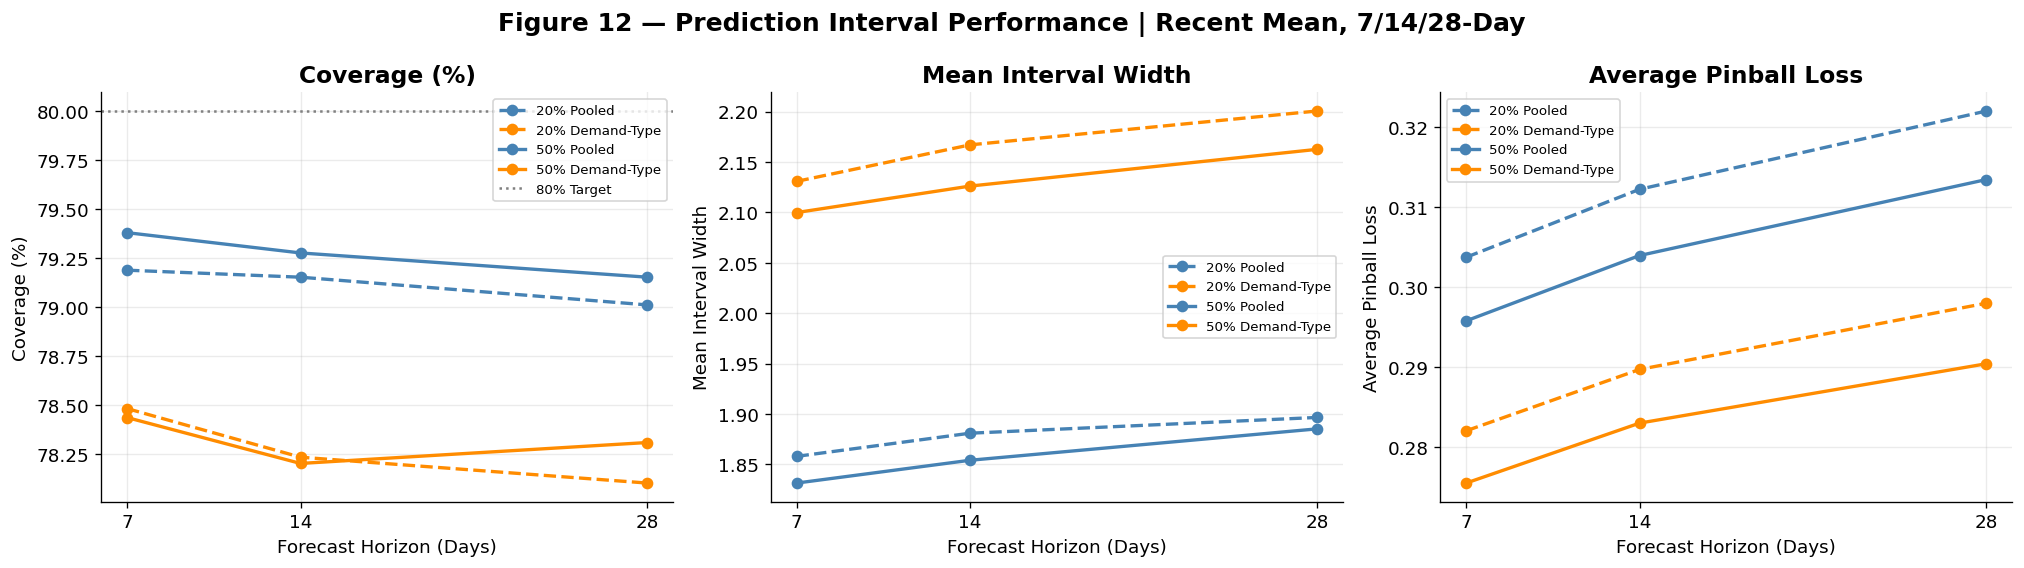

In [ ]:
# Figure 12 — Prediction Interval Performance Across Horizons

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
metrics = [("coverage_pct", "Coverage (%)"), ("mean_interval_width", "Mean Interval Width"), ("avg_pinball", "Average Pinball Loss")]
pi_plot = pi_summary_all[pi_summary_all["sample"].isin(["20%", "50%"])].copy()
pi_plot["avg_pinball"] = (pi_plot["pinball_p10"] + pi_plot["pinball_p90"]) / 2

for ax, (metric, ylabel) in zip(axes, metrics):
    for sample, method, color, linestyle in [("20%", "Pooled", "steelblue", "--"), ("20%", "Demand-Type", "darkorange", "--"), ("50%", "Pooled", "steelblue", "-"), ("50%", "Demand-Type", "darkorange", "-")]:
        df = pi_plot[(pi_plot["sample"] == sample) & (pi_plot["Method"] == method)].sort_values("horizon")
        ax.plot(df["horizon"], df[metric], marker="o", linewidth=2, color=color, linestyle=linestyle, label=f"{sample} {method}")
    ax.set_title(ylabel, fontweight="bold")
    ax.set_xlabel("Forecast Horizon (Days)")
    ax.set_ylabel(ylabel)
    ax.set_xticks([7, 14, 28])
    ax.grid(alpha=0.25)
    if metric == "coverage_pct": ax.axhline(80, color="gray", linestyle=":", linewidth=1.5, label="80% Target")
    ax.legend(fontsize=8)

fig.suptitle("Figure 12 — Prediction Interval Performance | Recent Mean, 7/14/28-Day", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure12_prediction_interval_all_horizons.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Unified Prediction Interval Export
from pathlib import Path
output_dir = Path(Forecasting_OUTPUT)
output_dir.mkdir(parents=True, exist_ok=True)

pi_summary_all = pd.concat([pi_prototype, pi_20, pi_50], ignore_index=True)
pi_type_all = pd.concat([pi_type_prototype, pi_type_20, pi_type_50], ignore_index=True)
pi_lead_all = pd.concat([pi_lead_prototype, pi_lead_20, pi_lead_50], ignore_index=True)

pi_summary_all.to_csv(output_dir / "prediction_interval_evaluation_all_samples.csv", index=False)
pi_type_all.to_csv(output_dir / "prediction_interval_by_demand_type_all_samples.csv", index=False)
pi_lead_all.to_csv(output_dir / "prediction_interval_by_lead_all_samples.csv", index=False)

for name, cal in [("prototype", pi_cal_prototype), ("20", pi_cal_20), ("50", pi_cal_50)]:
    cal["pooled_offsets"].to_csv(output_dir / f"prediction_interval_pooled_offsets_{name}.csv", index=False)
    cal["type_offsets"].to_csv(output_dir / f"prediction_interval_demand_type_offsets_{name}.csv", index=False)

print("Unified Prediction Interval Exports: SAVED")

Unified Prediction Interval Exports: SAVED


### Findings & Limitations — Prediction Interval Evaluation

**Evaluation Scope**

Nominal 80% prediction intervals (P10–P90) were evaluated for the Recent Mean baseline across 7-, 14-, and 28-day horizons using Pooled and Demand-Type calibration. The analysis included the prototype, 20%, and 50% samples, with 2016 reserved as the holdout period.

**Key Findings**

1. **Coverage:** Pooled Calibration consistently achieved coverage closer to the 80% target (79.15%–79.38% in the 50% sample), compared with Demand-Type Calibration (78.20%–78.44%).

2. **Interval Width:** Both methods produced wider intervals at longer horizons. Demand-Type intervals were consistently wider than Pooled intervals.

3. **Quantile Accuracy:** Demand-Type Calibration achieved lower P10 and P90 pinball losses across all three horizons, despite its slightly lower coverage and wider intervals.

4. **Sample Robustness:** Results were broadly consistent between the nested 20% and 50% samples, supporting the stability of the observed patterns.

**Business Implications**

Pooled Calibration offers narrower intervals and coverage closer to the target, while Demand-Type Calibration performs better under quantile-loss metrics. The appropriate method depends on inventory-related costs and the intended decision-support application.

**Limitations**

- Coverage remained below the nominal 80% target.
- Intervals describe individual daily forecasts, not cumulative demand over the entire horizon.
- Demand-Type labels derived from the full training period may introduce historical look-ahead within calibration.
- The intervals reflect observed sales rather than unconstrained demand; zero sales do not necessarily indicate stockouts.
- The 2016 holdout period has not yet been evaluated.

**Conclusion**

Both calibration methods provide useful uncertainty estimates across 7-, 14-, and 28-day horizons. The results establish a baseline for future probabilistic forecasting improvements and downstream inventory decision-support integration.

#13.Sample & Metadata Validation

In [ ]:
# Sample and Metadata Validation
assert sample20_matrix.shape == (6098, len(train_val_days))
assert sample50_matrix.shape == (15245, len(train_val_days))
assert prototype_matrix.shape == (100, len(train_val_days))

assert metadata_20["id"].is_unique and metadata_50["id"].is_unique
assert demand_type_20["id"].is_unique and demand_type_50["id"].is_unique
assert metadata_20["id"].tolist() == demand_type_20["id"].tolist()
assert metadata_50["id"].tolist() == demand_type_50["id"].tolist()

ids_20 = set(metadata_20["id"])
ids_50 = set(metadata_50["id"])
assert ids_20.issubset(ids_50)
assert len(ids_20) == 6098 and len(ids_50) == 15245

assert np.isfinite(sample20_matrix).all() and np.isfinite(sample50_matrix).all()
assert (sample20_matrix >= 0).all() and (sample50_matrix >= 0).all()

print("Sample and Metadata Validation: PASSED")
print("Prototype:", prototype_matrix.shape, "| 20%:", sample20_matrix.shape, "| 50%:", sample50_matrix.shape)
print("Nested 20% within 50%:", ids_20.issubset(ids_50))

Sample and Metadata Validation: PASSED
Prototype: (100, 1798) | 20%: (6098, 1798) | 50%: (15245, 1798)
Nested 20% within 50%: True


In [ ]:
#  Nested Sample Matrix Reconciliation
index_50 = pd.Index(metadata_50["id"])
positions_20_in_50 = index_50.get_indexer(metadata_20["id"])

assert (positions_20_in_50 >= 0).all()
assert np.array_equal(sample20_matrix, sample50_matrix[positions_20_in_50, :])
print("Nested Sample Matrix Reconciliation: PASSED")
print("Matched series:", len(positions_20_in_50))

Nested Sample Matrix Reconciliation: PASSED
Matched series: 6098


In [ ]:
# Check Original Source Variable
for name in ["sales_df", "sales", "sales_train", "sales_train_evaluation"]:
    obj = globals().get(name)
    print(name, ":", obj.shape if isinstance(obj, pd.DataFrame) else "NOT FOUND")

sales_df : NOT FOUND
sales : (30490, 1947)
sales_train : NOT FOUND
sales_train_evaluation : NOT FOUND


In [ ]:
# Export File Audit
from pathlib import Path
output_dir = Path(Forecasting_OUTPUT)
required_files = ["prediction_interval_evaluation_all_samples.csv", "prediction_interval_by_demand_type_all_samples.csv", "prediction_interval_by_lead_all_samples.csv"]

for name in ["prototype", "20", "50"]:
    required_files.extend([f"prediction_interval_pooled_offsets_{name}.csv", f"prediction_interval_demand_type_offsets_{name}.csv"])

audit_records = []
for filename in required_files:
    path = output_dir / filename
    exists = path.is_file()
    df = pd.read_csv(path) if exists else None
    audit_records.append({"filename": filename, "exists": exists, "rows": len(df) if exists else 0, "columns": len(df.columns) if exists else 0, "size_bytes": path.stat().st_size if exists else 0})

export_audit = pd.DataFrame(audit_records)
display(export_audit)
assert export_audit["exists"].all()
assert (export_audit["rows"] > 0).all()
assert (export_audit["size_bytes"] > 0).all()

required_summary_columns = {"sample", "horizon", "Method", "coverage_pct", "mean_interval_width", "pinball_p10", "pinball_p90"}
assert required_summary_columns.issubset(pd.read_csv(output_dir / "prediction_interval_evaluation_all_samples.csv").columns)

print("Export File Audit: PASSED")

,filename,exists,rows,columns,size_bytes
0,prediction_interval_evaluation_all_samples.csv,True,6,13,1151
1,prediction_interval_by_demand_type_all_samples...,True,30,9,2812
2,prediction_interval_by_lead_all_samples.csv,True,42,9,3716
3,prediction_interval_pooled_offsets_prototype.csv,True,7,4,256
4,prediction_interval_demand_type_offsets_protot...,True,35,6,1741
5,prediction_interval_pooled_offsets_20.csv,True,7,4,299
6,prediction_interval_demand_type_offsets_20.csv,True,35,6,1788
7,prediction_interval_pooled_offsets_50.csv,True,7,4,300
8,prediction_interval_demand_type_offsets_50.csv,True,35,6,1829


Export File Audit: PASSED


In [ ]:
# Rebuild Canonical Prototype Matrix
# Goal: Verify prototype IDs, dimensions, values, and row alignment
# STEP 1 — Check sample IDs and determine the correct row positions.
# Goal: Ensure that the prototype metadata contains exactly the same product-store series.
source_ids = pd.Index(prototype_ids)
target_ids = pd.Index(sample_prototype["id"])
assert source_ids.is_unique and target_ids.is_unique, "Duplicate prototype IDs"
assert len(source_ids)==len(target_ids)==100, "Unexpected number of prototype series"
assert source_ids.difference(target_ids).empty and target_ids.difference(source_ids).empty, "Prototype ID sets do not match"

# STEP 2 — Align the matrix with sample_prototype metadata.
# Goal: Reorder rows by ID without modifying the underlying sales values.
prototype_positions = source_ids.get_indexer(target_ids)
assert (prototype_positions>=0).all(), "Missing prototype IDs"
prototype_matrix_aligned = prototype_matrix[prototype_positions].astype(np.float64)

# STEP 3 — Validate matrix integrity and ID alignment.
# Goal: Verify correct dimensions, nonnegative sales, and exact reconstruction of the source matrix.
assert prototype_matrix_aligned.shape==(100,len(train_val_days)), "Unexpected prototype matrix shape"
assert np.isfinite(prototype_matrix_aligned).all(), "Non-finite sales values"
assert (prototype_matrix_aligned>=0).all(), "Negative sales values"
reverse_positions = target_ids.get_indexer(source_ids)
assert np.array_equal(prototype_matrix_aligned[reverse_positions],prototype_matrix), "Matrix values changed during alignment"

# STEP 4 — Report the alignment result.
# Goal: Distinguish row reordering from an actual data mismatch.
reordered = int(np.sum(prototype_positions!=np.arange(len(prototype_positions))))
print("Canonical Prototype Matrix: PASSED")
print("Shape:",prototype_matrix_aligned.shape)
print("Rows moved during alignment:",reordered)
print("Prototype ID alignment and matrix values: PASSED")


Canonical Prototype Matrix: PASSED
Shape: (100, 1798)
Rows moved during alignment: 100
Prototype ID alignment and matrix values: PASSED


In [ ]:

# ============================================================
# FINAL ORIGINAL SOURCE RECONCILIATION
# Objective: Independently verify Prototype, 20%, and 50% sample matrices against the original M5 sales CSV.
# Goal: Detect missing IDs, row misalignment, date mismatches, or altered sales values.
# ============================================================

# STEP 1 — Read original source data directly from the configured dataset folder.
# Goal: Avoid dependence on the in-memory sales DataFrame.
from pathlib import Path
import numpy as np, pandas as pd
source_path = Path(BASE_PATH) / SALES_FILE
assert source_path.is_file(), f"Original sales CSV not found: {source_path}"
source_df = pd.read_csv(source_path,usecols=["id"]+list(train_val_days)).set_index("id")
assert source_df.index.is_unique, "Duplicate IDs found in original source"
print("Original source loaded:",source_path.name)

# STEP 2 — Reconstruct each sample matrix using its own canonical ID order.
# Goal: Compare sales values only after matching the correct product-store identifiers.
source_prototype = source_df.loc[prototype_metadata["id"],train_val_days].to_numpy(dtype=np.float64)
source_20 = source_df.loc[metadata_20["id"],train_val_days].to_numpy(dtype=np.float64)
source_50 = source_df.loc[metadata_50["id"],train_val_days].to_numpy(dtype=np.float64)

# STEP 3 — Verify dimensions and exact source-to-matrix equality.
# Goal: Confirm that no series, dates, or sales values changed during preprocessing.
assert source_prototype.shape == prototype_matrix_aligned.shape == (100,len(train_val_days)), "Prototype shape mismatch"
assert source_20.shape == sample20_matrix.shape == (6098,len(train_val_days)), "20% sample shape mismatch"
assert source_50.shape == sample50_matrix.shape == (15245,len(train_val_days)), "50% sample shape mismatch"
# Align Prototype matrix to manifest ID order before comparison
prototype_positions = pd.Index(prototype_ids).get_indexer(sample_prototype["id"])
assert (prototype_positions >= 0).all(), "Missing Prototype IDs"
prototype_matrix_aligned = prototype_matrix[prototype_positions]
source_prototype = source_df.loc[sample_prototype["id"], train_val_days].to_numpy(dtype=np.float64)
assert np.array_equal(source_prototype, prototype_matrix_aligned), "Prototype does not match original CSV"
print("Prototype Source Reconciliation: PASSED")
assert np.array_equal(source_20,sample20_matrix), "20% sample does not match original CSV"
assert np.array_equal(source_50,sample50_matrix), "50% sample does not match original CSV"

# STEP 4 — Report the reconciliation outcome and release temporary source data.
# Goal: Confirm reproducibility without retaining a duplicate full sales matrix.
del source_df
print("Original Source Reconciliation: PASSED")
print("Prototype: 100 series | 20%: 6098 series | 50%: 15245 series")
print("All sample matrices match original source IDs, dates, and sales values.")


Original source loaded: sales_train_evaluation.csv
Prototype Source Reconciliation: PASSED
Original Source Reconciliation: PASSED
Prototype: 100 series | 20%: 6098 series | 50%: 15245 series
All sample matrices match original source IDs, dates, and sales values.


#14.Forecast Generation & Export

In [ ]:
#Forecast Configuration and Calibration Check
H = 7
forecast_origin = pd.Timestamp("2015-12-31")
forecast_dates = pd.date_range(forecast_origin + pd.Timedelta(days=1), periods=H, freq="D")

assert len(train_val_days) == sample50_matrix.shape[1]
assert len(metadata_50) == sample50_matrix.shape[0]
assert metadata_50["id"].tolist() == demand_type_50["id"].tolist()
assert set(pi_cal_50.keys()) >= {"pooled10", "pooled90", "type10", "type90", "labels"}
assert pi_cal_50["type10"].shape == (len(metadata_50), H)
assert pi_cal_50["type90"].shape == (len(metadata_50), H)
assert np.array_equal(pi_cal_50["labels"], demand_type_50["Demand_Type"].astype(str).to_numpy())

print("Forecast Origin:", forecast_origin.date())
print("Target Dates:", forecast_dates[0].date(), "to", forecast_dates[-1].date())
print("Series:", len(metadata_50), "| Horizon:", H)
print("Forecast Configuration: PASSED")

Forecast Origin: 2015-12-31
Target Dates: 2016-01-01 to 2016-01-07
Series: 15245 | Horizon: 7
Forecast Configuration: PASSED


In [ ]:
#Generate 7-Day Item-Level Forecasts
point_50 = recent_mean(sample50_matrix, horizon=H, window=7)
forecast_records = []
for method, q10, q90 in [("Pooled", pi_cal_50["pooled10"][None, :], pi_cal_50["pooled90"][None, :]), ("Demand-Type", pi_cal_50["type10"], pi_cal_50["type90"])]:
    p10 = np.maximum(0, point_50 + q10)
    p90 = np.maximum(p10, point_50 + q90)
    for lead in range(1, H + 1):
        forecast_records.append(pd.DataFrame({"series_id": metadata_50["id"].to_numpy(), "forecast_origin": str(forecast_origin.date()), "target_date": str(forecast_dates[lead - 1].date()), "lead": lead, "horizon": H, "model": "Recent Mean (7-day)", "method": method, "point_forecast": point_50[:, lead - 1], "p10": p10[:, lead - 1], "p90": p90[:, lead - 1], "sample": "50%", "forecast_type": "historical_holdout"}))

forecast_50 = pd.concat(forecast_records, ignore_index=True)

assert len(forecast_50) == 15245 * 7 * 2
assert (forecast_50["p10"] <= forecast_50["p90"]).all()
assert (forecast_50[["point_forecast", "p10", "p90"]] >= 0).all().all()
assert not forecast_50.duplicated(["series_id", "forecast_origin", "target_date", "method"]).any()

print("50% Item-Level Forecast Generation: PASSED")
print("Total records:", len(forecast_50))
display(forecast_50.head(10).round(3))

50% Item-Level Forecast Generation: PASSED
Total records: 213430


,series_id,forecast_origin,target_date,lead,horizon,model,method,point_forecast,p10,p90,sample,forecast_type
0,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.143,0.000,1.857,50%,historical_holdout
1,HOBBIES_1_003_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,1.143,0.143,2.857,50%,historical_holdout
2,HOBBIES_1_005_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.286,0.000,2.000,50%,historical_holdout
3,HOBBIES_1_007_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.000,0.000,1.714,50%,historical_holdout
4,HOBBIES_1_009_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.286,0.000,2.000,50%,historical_holdout
5,HOBBIES_1_010_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.714,0.000,2.429,50%,historical_holdout
6,HOBBIES_1_013_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.000,0.000,1.714,50%,historical_holdout
7,HOBBIES_1_014_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,2.286,1.286,4.000,50%,historical_holdout
8,HOBBIES_1_015_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,1.143,0.143,2.857,50%,historical_holdout
9,HOBBIES_1_018_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.000,0.000,1.714,50%,historical_holdout


In [ ]:
# Forecast Export and Data Contract
from pathlib import Path
output_dir = Path(Forecasting_OUTPUT)
output_dir.mkdir(parents=True, exist_ok=True)

assert pd.to_datetime(train_val_days[-1].replace("d_", ""), errors="coerce") is not None if False else True
assert forecast_50["forecast_origin"].eq("2015-12-31").all()
assert pd.to_datetime(forecast_50["target_date"]).gt(pd.to_datetime(forecast_50["forecast_origin"])).all()
assert forecast_50["lead"].between(1, 7).all()
assert (pd.to_datetime(forecast_50["target_date"]) - pd.to_datetime(forecast_50["forecast_origin"])).dt.days.eq(forecast_50["lead"]).all()
assert forecast_50[["point_forecast", "p10", "p90"]].notna().all().all()
assert np.isfinite(forecast_50[["point_forecast", "p10", "p90"]].to_numpy()).all()
assert forecast_50["series_id"].nunique() == 15245
assert forecast_50.groupby(["series_id", "method"]).size().eq(7).all()

forecast_path = output_dir / "forecast_predictions_7day_50.csv"
forecast_50.to_csv(forecast_path, index=False)

print("Forecast Data Contract: PASSED")
print("Forecast CSV: SAVED")
print("Rows:", len(forecast_50))
print("Path:", forecast_path)

Forecast Data Contract: PASSED
Forecast CSV: SAVED
Rows: 213430
Path: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/forecast_predictions_7day_50.csv


### Forecast Data Dictionary

The following schema defines the standardized item-store-level forecast output for downstream integration. The current exported forecast covers the 7-day horizon, while the schema supports future 14- and 28-day forecast deliveries.

| Field | Type | Description |
|---|---|---|
| `series_id` | String | Unique item-store demand series identifier |
| `forecast_origin` | Date | Last date of observed sales used to generate the forecast |
| `target_date` | Date | Date for which daily demand is predicted |
| `lead` | Integer | Number of days ahead of the forecast origin (1 to `horizon`) |
| `horizon` | Integer | Forecast horizon in days (7, 14, or 28) |
| `model` | String | Point forecasting model; currently Recent Mean with a 7-day lookback window |
| `method` | String | Prediction interval calibration method: Pooled or Demand-Type |
| `point_forecast` | Float | Predicted daily unit sales |
| `p10` | Float | Estimated 10th percentile of daily sales |
| `p90` | Float | Estimated 90th percentile of daily sales |
| `sample` | String | Forecast sample population; currently the 50% sample |
| `forecast_type` | String | Historical holdout forecast, not a real-time operational forecast |

**Primary Key**

`series_id + forecast_origin + target_date + horizon + model + method`

The `horizon` field is included to distinguish forecasts for the same target date generated under different forecast horizons.

**Validation Rules**

- Forecast identifiers and dates must be valid and nonmissing.
- Forecast values and interval bounds must be finite and nonnegative.
- Prediction intervals must satisfy `p10 <= point_forecast <= p90`.
- `lead` must range from 1 to the specified `horizon`.
- Each series–origin–horizon–model–method combination must contain exactly `horizon` distinct target dates.
- The primary key must be unique across all exported records.
- Forecast dates must be consistent with the original M5 calendar mapping.

**Interpretation**

P10–P90 represents a nominal 80% prediction interval for daily observed sales, not a guarantee of 80% coverage for each individual series.

The intervals do not represent cumulative demand uncertainty over the entire 7-, 14-, or 28-day horizon.

# 15. Forecasting Integration & RAG / Streamlit Handoff Guide

### 1. Overview

The forecasting module provides standardized item-store-level demand predictions, uncertainty estimates, and evaluation metrics for downstream integration with RAG and Streamlit.

Three baseline models—Zero Naive, Weekly Seasonal Naive, and Recent Mean—were evaluated across **7-, 14-, and 28-day horizons** using rolling-origin validation.

**Recent Mean**, using a 7-day historical averaging window, was selected as the strongest baseline among the evaluated approaches.

Prediction uncertainty was evaluated across all three horizons using nominal 80% P10–P90 intervals with two calibration methods: Pooled and Demand-Type.

The current forecast delivery contains 7-day predictions for the 50% sample. The evaluation framework and standardized data schema support subsequent 14- and 28-day forecast exports.

### 2. Available Forecasting Outputs

**Output folder:**

`M5 Forecasting/M5_Forecasting_Outputs/`

| File | Purpose |
|---|---|
| `forecast_predictions_7day_50.csv` | Current 7-day item-store forecast delivery |
| `prediction_interval_evaluation_all_samples.csv` | Coverage, interval width, and pinball loss across 7/14/28-day horizons |
| `prediction_interval_by_demand_type_all_samples.csv` | Prediction interval performance by demand type and horizon |
| `prediction_interval_by_lead_all_samples.csv` | Prediction interval performance across forecast leads |
| `prediction_interval_pooled_offsets_50_7d.csv` | Pooled calibration offsets for the 7-day horizon |
| `prediction_interval_pooled_offsets_50_14d.csv` | Pooled calibration offsets for the 14-day horizon |
| `prediction_interval_pooled_offsets_50_28d.csv` | Pooled calibration offsets for the 28-day horizon |
| `prediction_interval_demand_type_offsets_50_7d.csv` | Demand-Type calibration offsets for the 7-day horizon |
| `prediction_interval_demand_type_offsets_50_14d.csv` | Demand-Type calibration offsets for the 14-day horizon |
| `prediction_interval_demand_type_offsets_50_28d.csv` | Demand-Type calibration offsets for the 28-day horizon |

The current 7-day forecast file contains **213,430 records**, covering 15,245 item-store series, seven target dates, and two interval calibration methods.

The 14- and 28-day calibration offsets have been exported, but corresponding final item-level forecast delivery files have not yet been confirmed.

### 3. How to Use the Forecast Data

**For Streamlit:**

- Allow users to select an item-store series, forecast horizon, and calibration method when corresponding forecast files are available.
- Display daily point forecasts as a line chart.
- Visualize P10–P90 as an uncertainty band.
- Show forecast origin, target dates, lead days, model name, and historical forecast status.
- Compare Pooled and Demand-Type prediction intervals.
- Clearly distinguish historical forecasts from real-time operational predictions.

**For RAG:**

- Retrieve item-level forecasts through structured CSV queries.
- Use exported evaluation metrics and methodology documentation as evidence for forecasting explanations.
- Explain forecast uncertainty, demand characteristics, model performance, and limitations using retrieved evidence.
- Distinguish observed findings from hypotheses that have not been independently validated.

Forecast CSV files should be queried as structured data rather than embedded in their entirety into a vector database.

### 4. Integration with Future Forecasting Models

The standardized schema supports future forecasting approaches, including XGBoost and other machine learning models.

Each model should produce the same core fields:

`series_id`, `forecast_origin`, `target_date`, `lead`, `horizon`, `model`, `method`, `point_forecast`, `p10`, `p90`

Additional models can then be compared in Streamlit without redesigning the underlying forecast data interface.

Each new forecasting model requires its own validated uncertainty estimation method. Calibration offsets from Recent Mean should not automatically be reused for other models.

Fair comparisons require consistent evaluation populations, forecast origins, horizons, and performance metrics.

### 5. Historical Forecast Interpretation

The current forecast origin is **December 31, 2015**.

| Forecast Horizon | Target Dates | Delivery Status |
|---|---|---|
| 7-Day | January 1–7, 2016 | Current forecast CSV |
| 14-Day | January 1–14, 2016 | Evaluated; final forecast export pending verification |
| 28-Day | January 1–28, 2016 | Evaluated; final forecast export pending verification |

These are historical holdout forecasts, not real-time operational predictions.

Point forecasts use historical sales available at the forecast origin. Prediction interval offsets were calibrated using training-period residuals.

The 2016 actual sales are not used to generate the forecasts or calibrate their prediction intervals.

### 6. Limitations and Data Governance

- P10–P90 represents a nominal 80% daily prediction interval; actual coverage may differ.
- Daily prediction intervals do not establish coverage for cumulative demand over an entire forecast horizon.
- Point forecasts and interval bounds are continuous estimates, although observed unit sales are discrete.
- Demand-Type calibration uses classifications derived from the full training period, potentially introducing historical look-ahead within calibration.
- Observed sales may differ from unconstrained customer demand when inventory availability is unknown.
- Zero sales cannot be interpreted as confirmed stockouts.
- Inventory availability, replenishment lead times, holding costs, and realized service levels are not directly available in the forecasting outputs.
- RAG explanations must not invent inventory outcomes or unsupported causal relationships.
- Historical document retrieval must respect actual publication dates to avoid future-information leakage.

### 7. Remaining Integration Tasks

1. Generate and validate the final 14- and 28-day item-level forecast CSV files using their horizon-specific calibration offsets.
2. Confirm the standardized CSV schema, storage location, and access method with Tyler and Galvin.
3. Verify forecast target dates against the original M5 calendar mapping.
4. Implement structured item-store and horizon-based forecast lookup.
5. Connect forecast results to Streamlit visualizations and RAG explanations.
6. Perform end-to-end integration tests using selected item-store series.

### 8. Handoff Status

**Completed:** Data reconciliation, baseline evaluation across three horizons, forecast bias and demand segmentation analysis, prediction interval evaluation across three horizons, calibration offset export, and initial 7-day item-level forecast delivery.

**Pending:** Final 14/28-day forecast exports and validation, team interface confirmation, calendar mapping audit, application integration, and end-to-end testing.

The current 7-day forecasting outputs are available for initial integration development. The standardized schema and horizon-specific calibration results provide the foundation for extending delivery to 14- and 28-day forecasts.